In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# IQP observable variance: binary rank vs. light-cone size

This notebook uses QASP's `IQPAnsatz` and `CircuitBuilder` to test the exact variance law for commuting IQP circuits. Every empirical point uses **2,000 independent parameter samples** from $U[-\pi,\pi]$ by default.

For a one-layer QASP IQP circuit, `IQPAnsatz` implements
$$H^{\otimes n}\left(\prod_i R_{Z_i}(\alpha_i)\right)\left(\prod_{(i,j)\in E}R_{Z_iZ_j}(\beta_{ij})\right)H^{\otimes n}.$$
Because $HR_Z(\theta)H=R_X(\theta)$ and $(H\otimes H)R_{ZZ}(\theta)(H\otimes H)=R_{XX}(\theta)$, this is exactly the requested commuting $R_X/R_{XX}$ circuit.

# Table of contents

### Jump directly to an experiment

- [Theory: rank and light-cone variance laws](#theory)
- [Binary and QASP utilities](#utilities)
- [Experiment 1 — pure $R_{XX}$ IQP](#experiment-1)
- [Experiment 2 — graph IQP on chains](#experiment-2)
- [Experiment 3 — rank vs. light-cone counterexample](#experiment-3)
- [Combined observable-scaling results](#observable-scaling)
- [Experiments 4–6 — contiguous, recursive parity, and modulo policies](#policy-experiments)
  - [Policy theory and exact QASP action maps](#policy-experiments)
  - [QASP Monte Carlo policy experiments](#policy-monte-carlo)
  - [Graph-IQP policy scaling plots](#policy-graph-plots)
  - [Pure RXX policy scaling plots](#policy-pure-rxx)
  - [Policy comparison checks](#policy-results)
- [Repeated IQP experiments](#repeated-iqp-experiments)
  - [Repeated-IQP depth scaling for $|A|=4$](#repeated-iqp-depth-scaling)
- [Experiment 7 - Majority modulo policies](#majority-modulo-experiments)
- [Conclusions](#conclusions)

Each experiment section includes its representative circuit or policy definition, empirical results, theoretical prediction, and scaling plot.

<a id="theory"></a>

## Theory

Let $s\in\mathbb F_2^n$ encode the support of the measured Pauli word $Z_s$. Let each commuting $X$-type generator be encoded by a binary support vector $g_j$. Keep only generators that anticommute with $Z_s$, i.e. $g_j\cdot s=1\pmod 2$, and place those vectors in the columns of
$$G_s=[g_{j_1}\;g_{j_2}\;\cdots].$$
For independent angles uniform on $[-\pi,\pi]$,
$$\boxed{\operatorname{Var}(L_s)=2^{-\operatorname{rank}_{\mathbb F_2}(G_s)}}.$$

Define the generator light cone as the union of qubits touched by the anticommuting generators:
$$\Delta(s)=\left|\bigcup_{j:g_j\cdot s=1}\operatorname{supp}(g_j)\right|.$$
For graph-IQP circuits containing every local $R_{X_i}$ generator, the relevant columns span every coordinate in that light cone, so $\operatorname{rank}(G_s)=\Delta_G(s)$ and
$$\boxed{\operatorname{Var}(L_s)=2^{-\Delta_G(s)}}.$$
Without the local generators, $\operatorname{rank}(G_s)$ can be strictly smaller than the light-cone size. Experiment 3 isolates this distinction.

In [1]:
from pathlib import Path
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml

# Make the repository importable whether Jupyter starts in QASP/ or QASP/tests/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'tests':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'qasp').exists():
    raise RuntimeError('Start this notebook from the QASP repository or its tests/ directory.')
sys.path.insert(0, str(PROJECT_ROOT))

import qasp
from qasp.circuits import CircuitBuilder, IQPAnsatz

SEED = 20260821
N_SAMPLES = int(os.getenv('QASP_IQP_SAMPLES', '2000'))
N_VALUES = [3, 4, 6, 8, 10]
POLICY_N_VALUES = [3, 4, 6, 8, 10, 12, 14, 16]
FIGURE_DPI = 300
plt.rcParams.update({'figure.dpi': FIGURE_DPI, 'savefig.dpi': FIGURE_DPI})
print(f'QASP root: {PROJECT_ROOT}')
print(f'Parameter samples per circuit: {N_SAMPLES}')
print(f'Observable experiment sizes: {N_VALUES}')
print(f'Policy experiment sizes: {POLICY_N_VALUES}')
print(f'Figure DPI: {FIGURE_DPI}')

QASP root: .
Parameter samples per circuit: 2000
Observable experiment sizes: [3, 4, 6, 8, 10]
Policy experiment sizes: [3, 4, 6, 8, 10, 12, 14, 16]
Figure DPI: 300


<a id="utilities"></a>

## Binary and QASP utilities

Qubits are zero-indexed in code. Thus the requested $Z_2Z_3$ observable is represented by `support=(1, 2)`. The matrix display uses rows $q_1,\ldots,q_n$ and one column per anticommuting generator.

In [4]:
def chain_edges(n):
    return [(i, i + 1) for i in range(n - 1)]


def ring_edges(n):
    if n < 3:
        raise ValueError('A simple ring requires at least three qubits.')
    return [(i, (i + 1) % n) for i in range(n)]


def complete_edges(n):
    return [(i, j) for i in range(n) for j in range(i + 1, n)]


def observable_string(support):
    support = tuple(sorted(support))
    return f"{'Z' * len(support)} {' '.join(map(str, support))}"


def generator_supports(n, edges, include_local):
    generators, labels = [], []
    if include_local:
        for i in range(n):
            g = np.zeros(n, dtype=np.uint8)
            g[i] = 1
            generators.append(g)
            labels.append(f'X{i + 1}')
    for i, j in edges:
        g = np.zeros(n, dtype=np.uint8)
        g[[i, j]] = 1
        generators.append(g)
        labels.append(f'X{i + 1}X{j + 1}')
    return generators, labels


def binary_generator_matrix(n, edges, support, include_local):
    s = np.zeros(n, dtype=np.uint8)
    s[list(support)] = 1
    generators, labels = generator_supports(n, edges, include_local)
    keep = [k for k, g in enumerate(generators) if int(g @ s) % 2 == 1]
    if not keep:
        return np.zeros((n, 0), dtype=np.uint8), []
    return np.column_stack([generators[k] for k in keep]), [labels[k] for k in keep]


def gf2_rank(matrix):
    """Gaussian-elimination rank over GF(2), not over the reals."""
    a = np.asarray(matrix, dtype=np.uint8).copy() % 2
    n_rows, n_cols = a.shape
    rank = 0
    for col in range(n_cols):
        pivots = np.flatnonzero(a[rank:, col])
        if len(pivots) == 0:
            continue
        pivot = rank + pivots[0]
        a[[rank, pivot]] = a[[pivot, rank]]
        for row in range(n_rows):
            if row != rank and a[row, col]:
                a[row] ^= a[rank]
        rank += 1
        if rank == n_rows:
            break
    return rank


def light_cone_size(G_s):
    return int(np.count_nonzero(np.any(G_s, axis=1))) if G_s.shape[1] else 0


def matrix_frame(G_s, labels):
    return pd.DataFrame(G_s, index=[f'q{i + 1}' for i in range(G_s.shape[0])], columns=labels)

In [5]:
def build_qasp_iqp(n, edges, support, include_local):
    """Build one QASP IQP expectation-value QNode."""
    ansatz = IQPAnsatz(
        n_qubits=n,
        n_layers=1,
        imprimitive_pattern=edges,
        include_single_qubit=include_local,
    )
    builder = CircuitBuilder(n_qubits=n)
    builder.set_ansatz(ansatz)
    builder.set_measurement(
        'expectation',
        wires=list(range(n)),
        observables=[observable_string(support)],
    )
    builder.build()
    qnode = builder.compile(device='default.qubit', diff_method=None)
    n_parameters = ansatz.get_param_shapes()[0][0]
    return qnode, n_parameters


def draw_qasp_iqp(n, edges, support, include_local, title):
    """Draw the exact QASP QNode used by an experiment."""
    qnode, n_parameters = build_qasp_iqp(n, edges, support, include_local)
    # Nonzero illustrative angles make every parameterized gate label visible.
    theta = np.linspace(0.15, 1.05, n_parameters)
    fig, _ = qml.draw_mpl(qnode, decimals=2)(params=theta)
    fig.set_dpi(FIGURE_DPI)
    fig.suptitle(title, y=1.02, fontsize=13)
    plt.show()


def monte_carlo_variance(n, edges, support, include_local, n_samples, seed):
    qnode, n_parameters = build_qasp_iqp(n, edges, support, include_local)
    rng = np.random.default_rng(seed)
    parameters = rng.uniform(-np.pi, np.pi, size=(n_samples, n_parameters))
    values = np.empty(n_samples)
    for k, theta in enumerate(parameters):
        values[k] = float(np.asarray(qnode(params=theta))[0])

    variance = values.var(ddof=1)
    centered_fourth = np.mean((values - values.mean()) ** 4)
    # Plug-in standard error of the unbiased sample variance.
    mc_se = np.sqrt(max(centered_fourth - ((n_samples - 3) / (n_samples - 1)) * variance**2, 0) / n_samples)
    return variance, mc_se, values.mean()


def run_case(n, edges, support, include_local, experiment, seed):
    G_s, labels = binary_generator_matrix(n, edges, support, include_local)
    rank = gf2_rank(G_s)
    delta = light_cone_size(G_s)
    empirical, mc_se, mean = monte_carlo_variance(
        n, edges, support, include_local, N_SAMPLES, seed
    )
    theory = 2.0 ** (-rank)
    return {
        'experiment': experiment,
        'n': n,
        'observable': observable_string(support),
        'rank': rank,
        'delta': delta,
        'empirical_variance': empirical,
        'mc_se': mc_se,
        'rank_prediction': theory,
        'light_cone_prediction': 2.0 ** (-delta),
        'sample_mean': mean,
        'z_score': (empirical - theory) / mc_se if mc_se > 0 else np.nan,
    }

<a id="experiment-1"></a>

## Experiment 1 — pure $R_{XX}$ IQP

We remove all local generators and use complete $R_{XX}$ interaction graphs. The observable is the requested $Z_2Z_3$. For this family, every edge crossing the observable cut contributes a column to $G_s$. The rank grows with $n$, while the light cone contains all $n$ qubits.

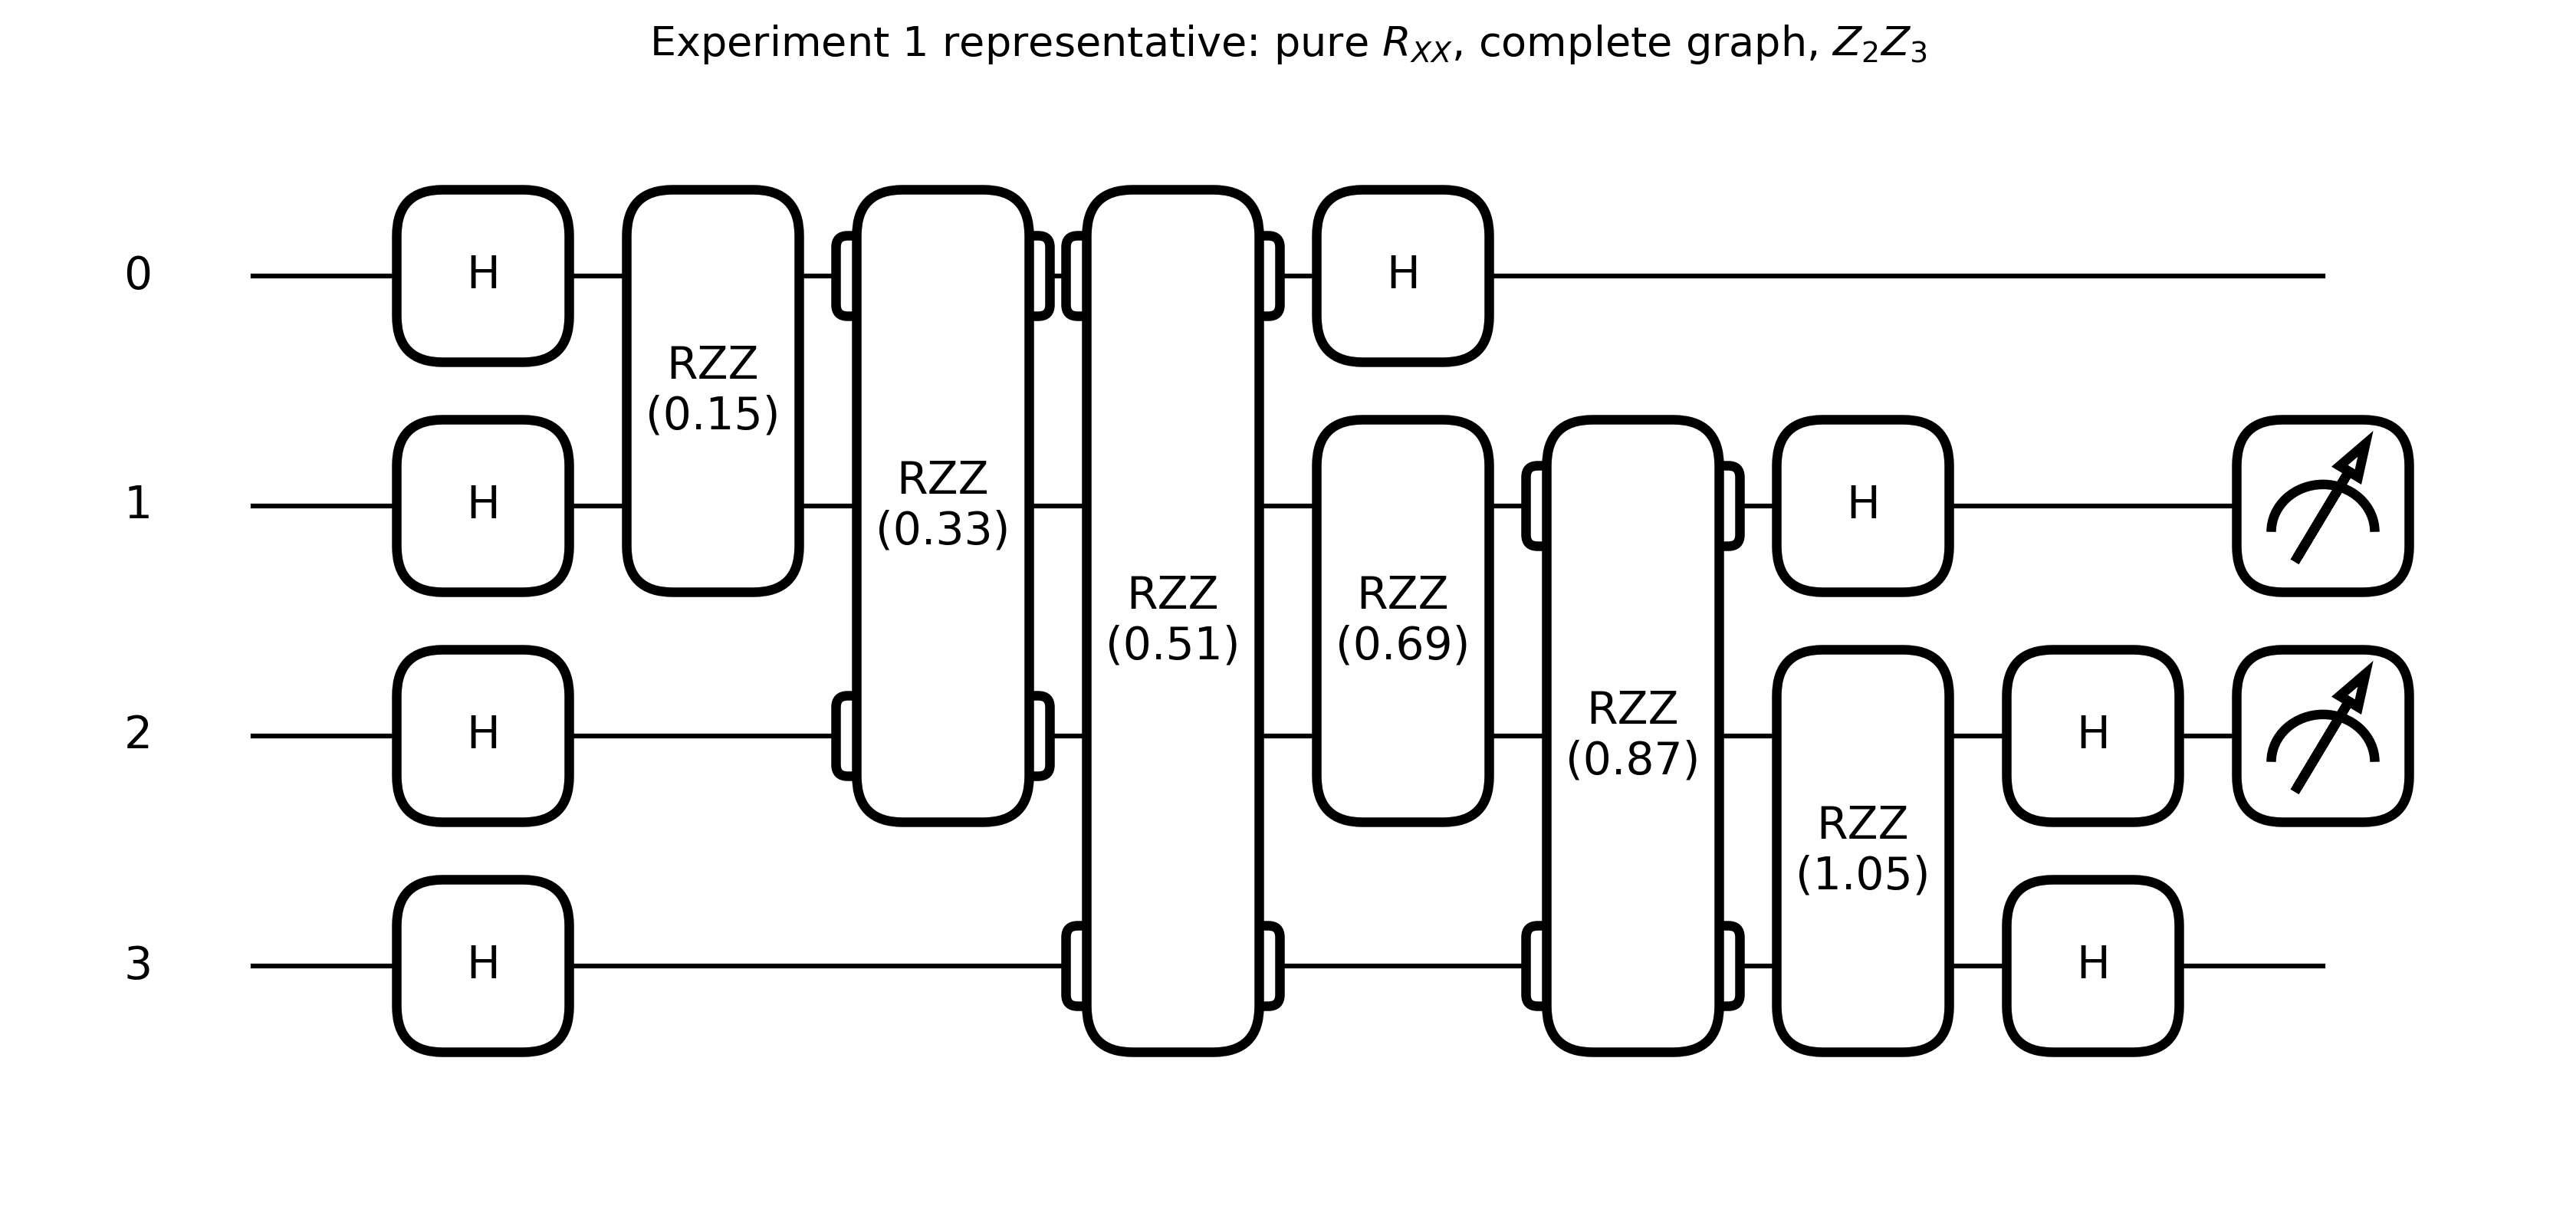

In [5]:
draw_qasp_iqp(
    n=4,
    edges=complete_edges(4),
    support=(1, 2),
    include_local=False,
    title=r'Experiment 1 representative: pure $R_{XX}$, complete graph, $Z_2Z_3$',
)

In [37]:
G_example, labels_example = binary_generator_matrix(
    n=4, edges=complete_edges(4), support=(1, 2), include_local=False
)
display(matrix_frame(G_example, labels_example))
print(f'rank_GF2(G_s) = {gf2_rank(G_example)}, delta = {light_cone_size(G_example)}')

,X1X2,X1X3,X2X4,X3X4
q1,1,1,0,0
q2,1,0,1,0
q3,0,1,0,1
q4,0,0,1,1


rank_GF2(G_s) = 3, delta = 4


In [38]:
start = time.perf_counter()
pure_rows = []
for idx, n in enumerate(N_VALUES):
    print(f'pure RXX: n={n}')
    pure_rows.append(run_case(
        n=n,
        edges=complete_edges(n),
        support=(1, 2),
        include_local=False,
        experiment='pure RXX / complete',
        seed=SEED + idx,
    ))
pure_df = pd.DataFrame(pure_rows)
display(pure_df.round(7))
print(f'Elapsed: {time.perf_counter() - start:.1f} s')

pure RXX: n=3
pure RXX: n=4
pure RXX: n=6
pure RXX: n=8
pure RXX: n=10


,experiment,n,observable,rank,delta,empirical_variance,mc_se,rank_prediction,light_cone_prediction,sample_mean,z_score
0,pure RXX / complete,3,ZZ 1 2,2,3,0.254453,0.006231,0.250000,0.125000,-0.003061,0.714562
1,pure RXX / complete,4,ZZ 1 2,3,4,0.125237,0.003687,0.125000,0.062500,0.003490,0.064147
2,pure RXX / complete,6,ZZ 1 2,5,6,0.033921,0.001363,0.031250,0.015625,0.002105,1.960141
3,pure RXX / complete,8,ZZ 1 2,7,8,0.007790,0.000420,0.007812,0.003906,0.002828,-0.052687
4,pure RXX / complete,10,ZZ 1 2,9,10,0.001898,0.000161,0.001953,0.000977,-0.000805,-0.344021


Elapsed: 51.0 s


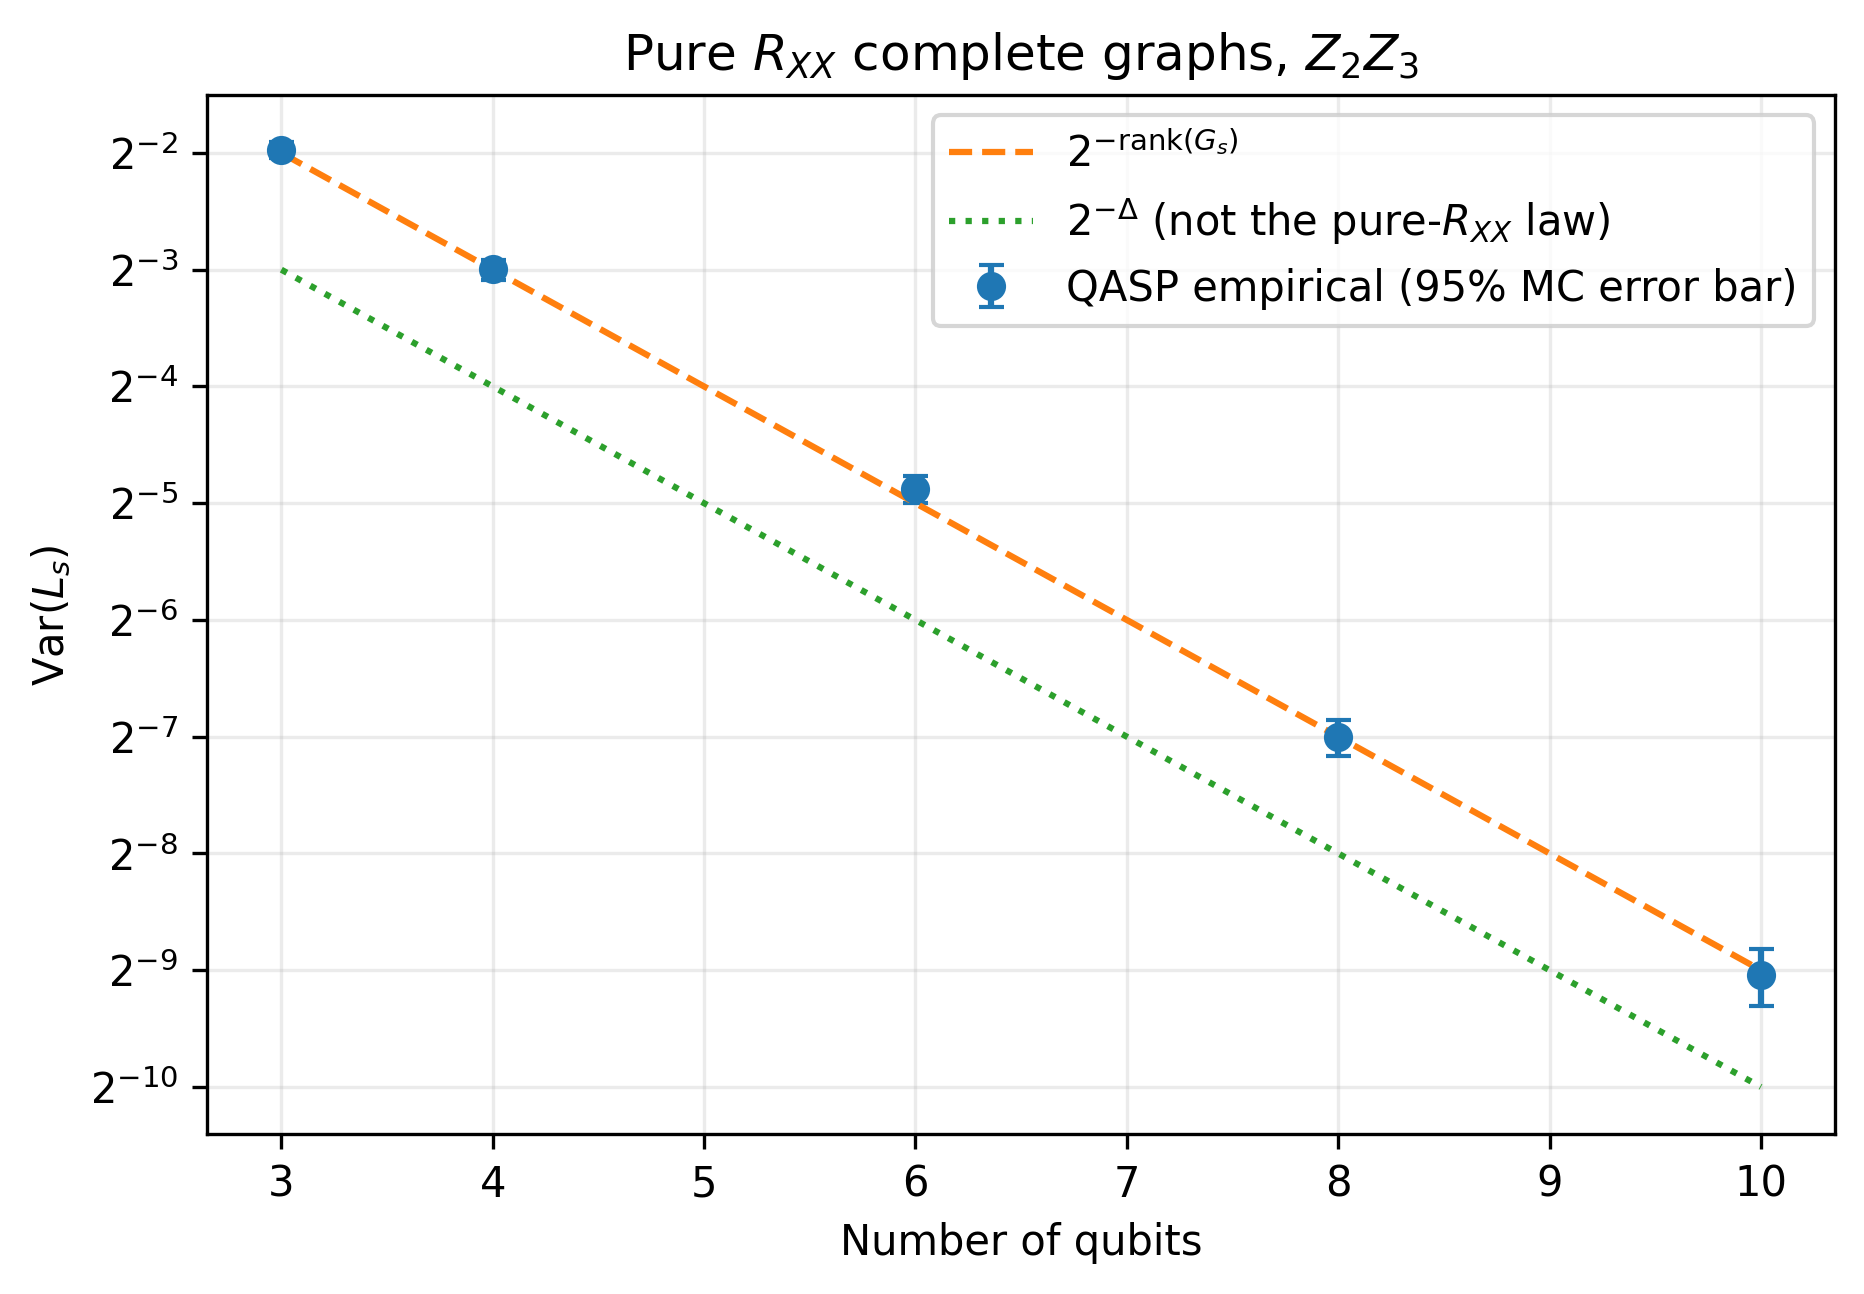

In [39]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=FIGURE_DPI)
ax.errorbar(pure_df['n'], pure_df['empirical_variance'], yerr=2 * pure_df['mc_se'],
            fmt='o', capsize=3, label='QASP empirical (95% MC error bar)')
ax.plot(pure_df['n'], pure_df['rank_prediction'], '--', label=r'$2^{-\mathrm{rank}(G_s)}$')
ax.plot(pure_df['n'], pure_df['light_cone_prediction'], ':', label=r'$2^{-\Delta}$ (not the pure-$R_{XX}$ law)')
ax.set(xlabel='Number of qubits', ylabel=r'$\mathrm{Var}(L_s)$', title=r'Pure $R_{XX}$ complete graphs, $Z_2Z_3$')
ax.set_yscale('log', base=2)
ax.grid(True, which='both', alpha=0.25)
ax.legend()
plt.show()

<a id="experiment-2"></a>

## Experiment 2 — graph IQP on chains

Now every local $R_{X_i}$ generator is present along with the chain edges. We test two observable families:

1. the fixed two-local observable $Z_2Z_3$;
2. an alternating-support observable $Z_1Z_3Z_5\cdots$, whose chain light cone grows with the system.

In both families the notebook explicitly checks $\operatorname{rank}(G_s)=\Delta_G(s)$.

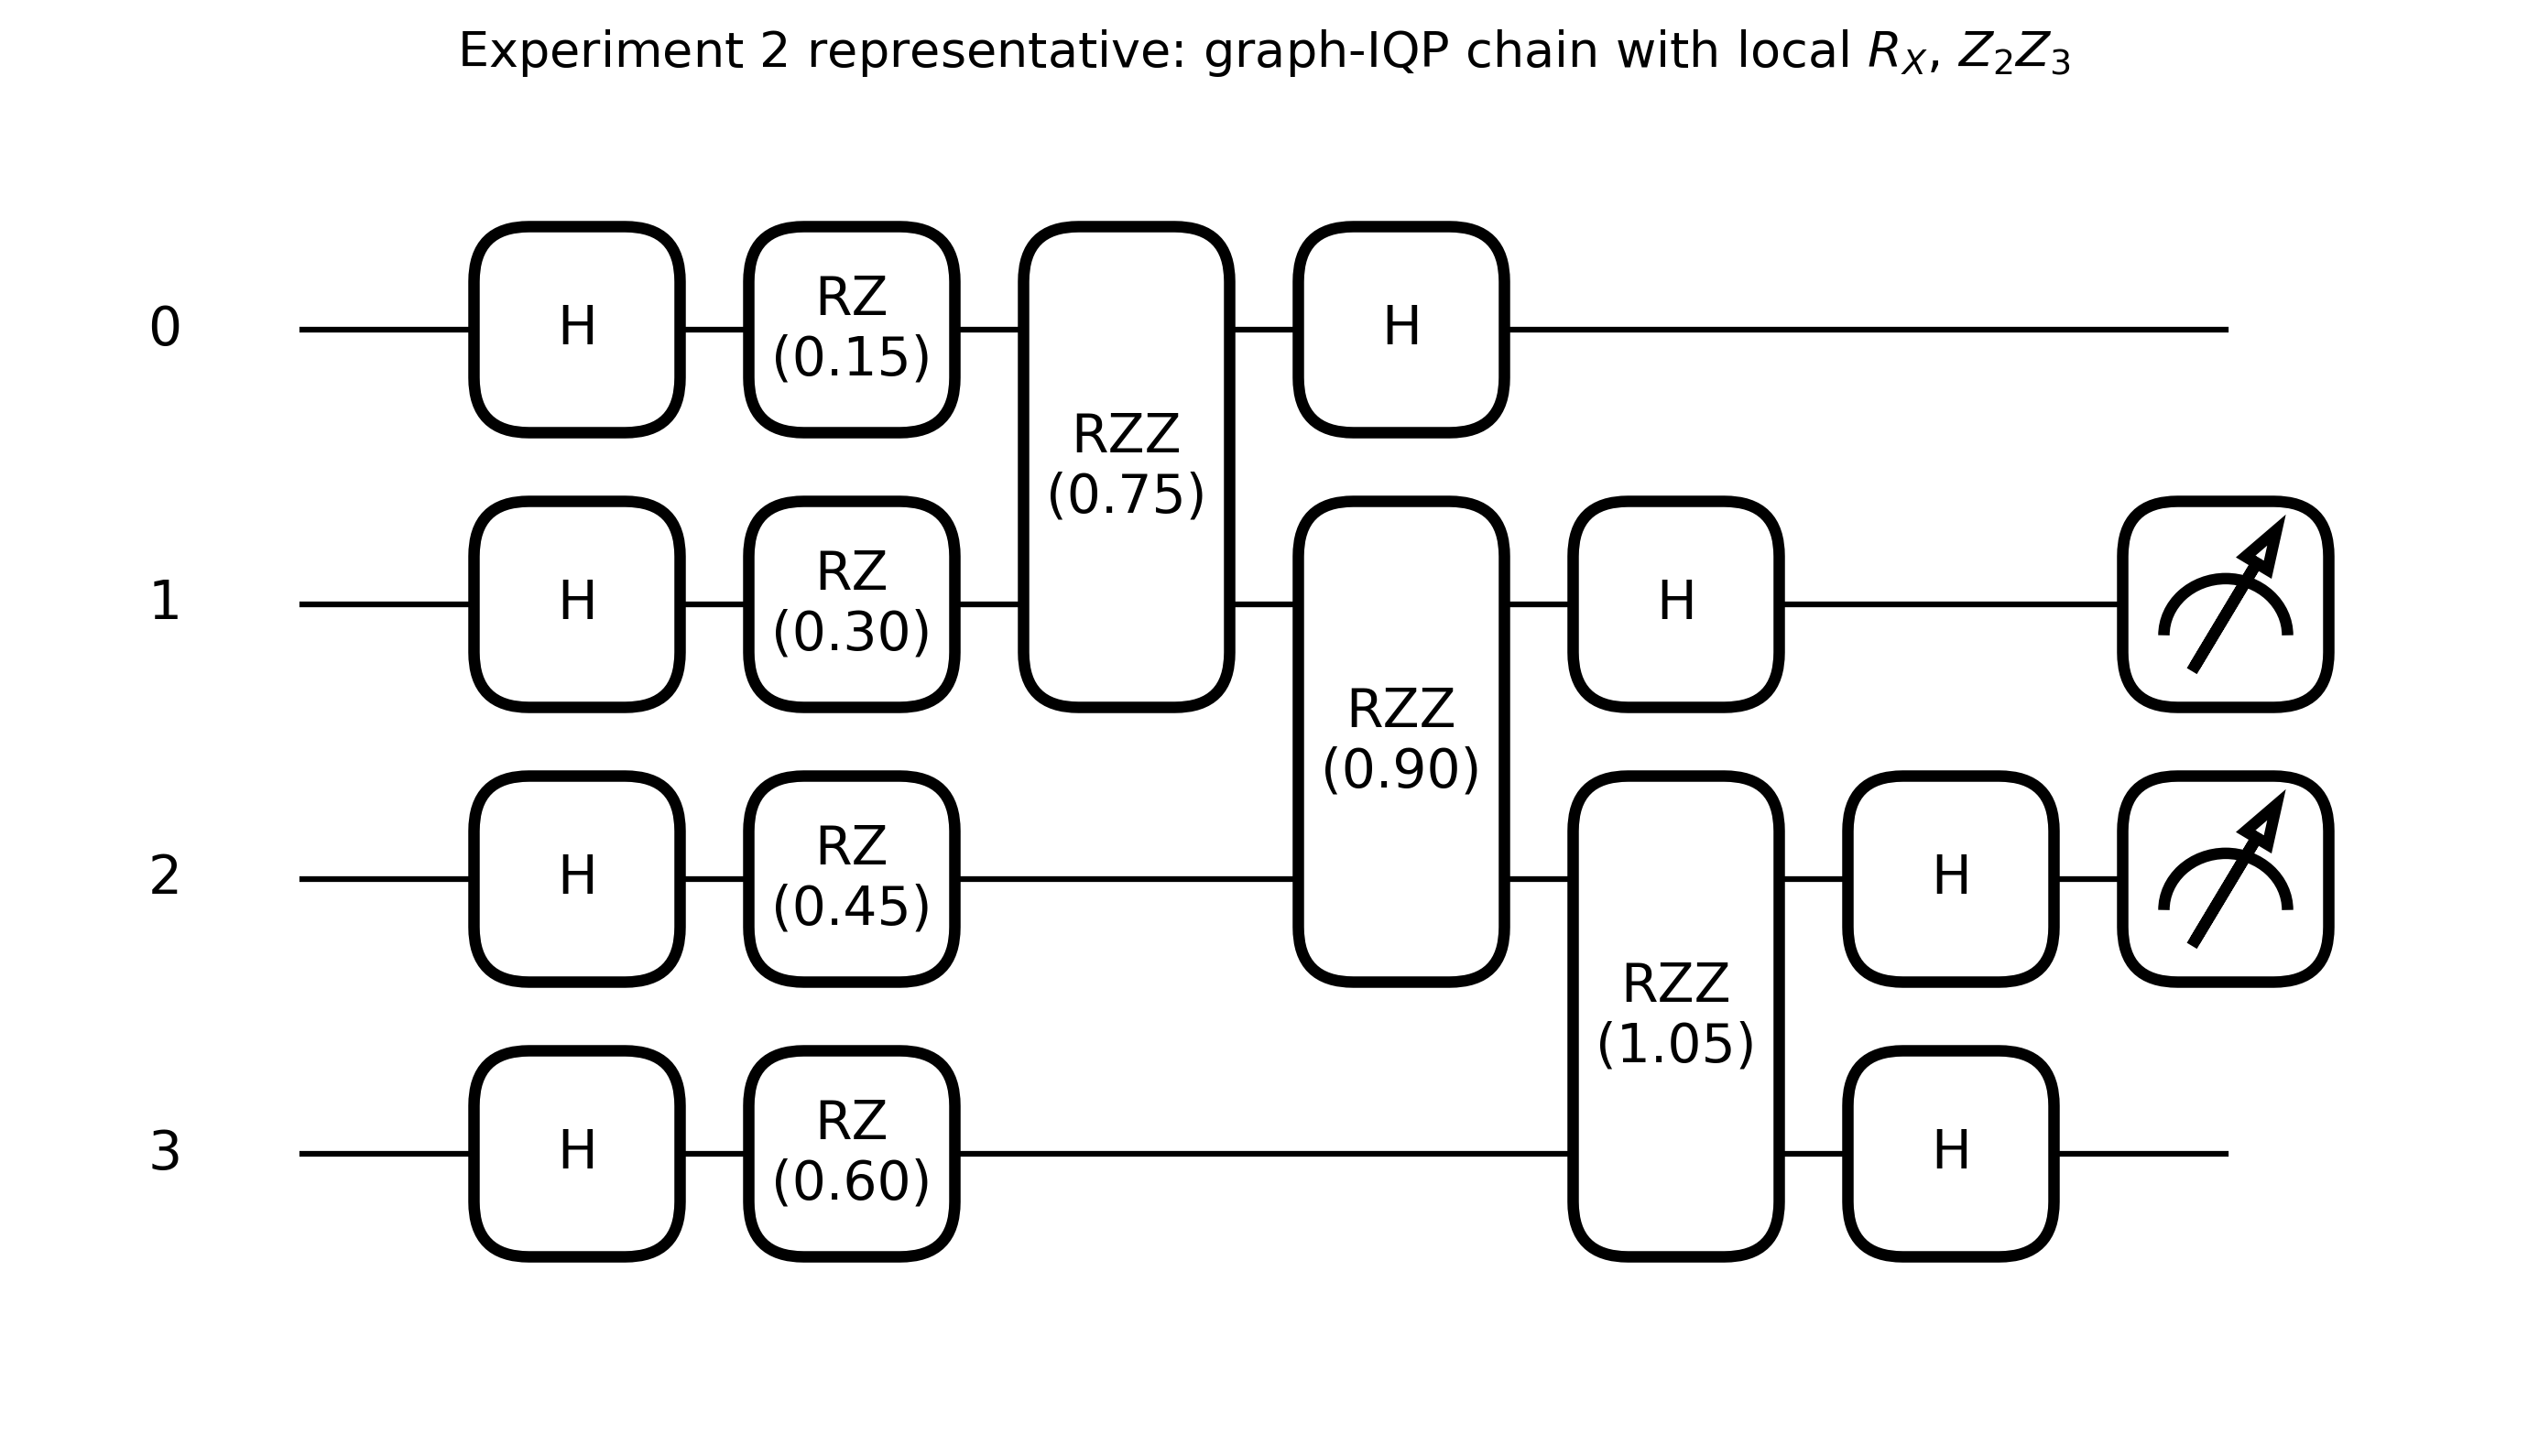

In [40]:
draw_qasp_iqp(
    n=4,
    edges=chain_edges(4),
    support=(1, 2),
    include_local=True,
    title=r'Experiment 2 representative: graph-IQP chain with local $R_X$, $Z_2Z_3$',
)

In [41]:
start = time.perf_counter()
graph_rows = []
for idx, n in enumerate(N_VALUES):
    cases = [
        ('graph IQP / chain / Z2Z3', (1, 2)),
        ('graph IQP / chain / alternating', tuple(range(0, n, 2))),
    ]
    for case_idx, (name, support) in enumerate(cases):
        print(f'{name}: n={n}')
        graph_rows.append(run_case(
            n=n,
            edges=chain_edges(n),
            support=support,
            include_local=True,
            experiment=name,
            seed=SEED + 100 + 2 * idx + case_idx,
        ))
graph_df = pd.DataFrame(graph_rows)
assert (graph_df['rank'] == graph_df['delta']).all()
display(graph_df.round(7))
print('Verified rank_GF2(G_s) = delta_G(s) for every graph-IQP case.')
print(f'Elapsed: {time.perf_counter() - start:.1f} s')

graph IQP / chain / Z2Z3: n=3
graph IQP / chain / alternating: n=3
graph IQP / chain / Z2Z3: n=4
graph IQP / chain / alternating: n=4
graph IQP / chain / Z2Z3: n=6
graph IQP / chain / alternating: n=6
graph IQP / chain / Z2Z3: n=8
graph IQP / chain / alternating: n=8
graph IQP / chain / Z2Z3: n=10
graph IQP / chain / alternating: n=10


,experiment,n,observable,rank,delta,empirical_variance,mc_se,rank_prediction,light_cone_prediction,sample_mean,z_score
0,graph IQP / chain / Z2Z3,3,ZZ 1 2,3,3,0.127370,0.004352,0.125000,0.125000,-0.001567,0.544572
1,graph IQP / chain / alternating,3,ZZ 0 2,3,3,0.119965,0.003446,0.125000,0.125000,-0.004040,-1.461002
2,graph IQP / chain / Z2Z3,4,ZZ 1 2,4,4,0.063741,0.002844,0.062500,0.062500,0.001191,0.436260
3,graph IQP / chain / alternating,4,ZZ 0 2,4,4,0.064985,0.002479,0.062500,0.062500,-0.002658,1.002674
4,graph IQP / chain / Z2Z3,6,ZZ 1 2,4,4,0.064620,0.002914,0.062500,0.062500,0.006155,0.727381
5,graph IQP / chain / alternating,6,ZZZ 0 2 4,6,6,0.013607,0.000728,0.015625,0.015625,0.003245,-2.772052
6,graph IQP / chain / Z2Z3,8,ZZ 1 2,4,4,0.064314,0.002823,0.062500,0.062500,0.003120,0.642409
7,graph IQP / chain / alternating,8,ZZZZ 0 2 4 6,8,8,0.004103,0.000308,0.003906,0.003906,-0.000931,0.639252
8,graph IQP / chain / Z2Z3,10,ZZ 1 2,4,4,0.058497,0.002629,0.062500,0.062500,0.010514,-1.522196
9,graph IQP / chain / alternating,10,ZZZZZ 0 2 4 6 8,10,10,0.001076,0.000090,0.000977,0.000977,0.000009,1.104899


Verified rank_GF2(G_s) = delta_G(s) for every graph-IQP case.
Elapsed: 60.2 s


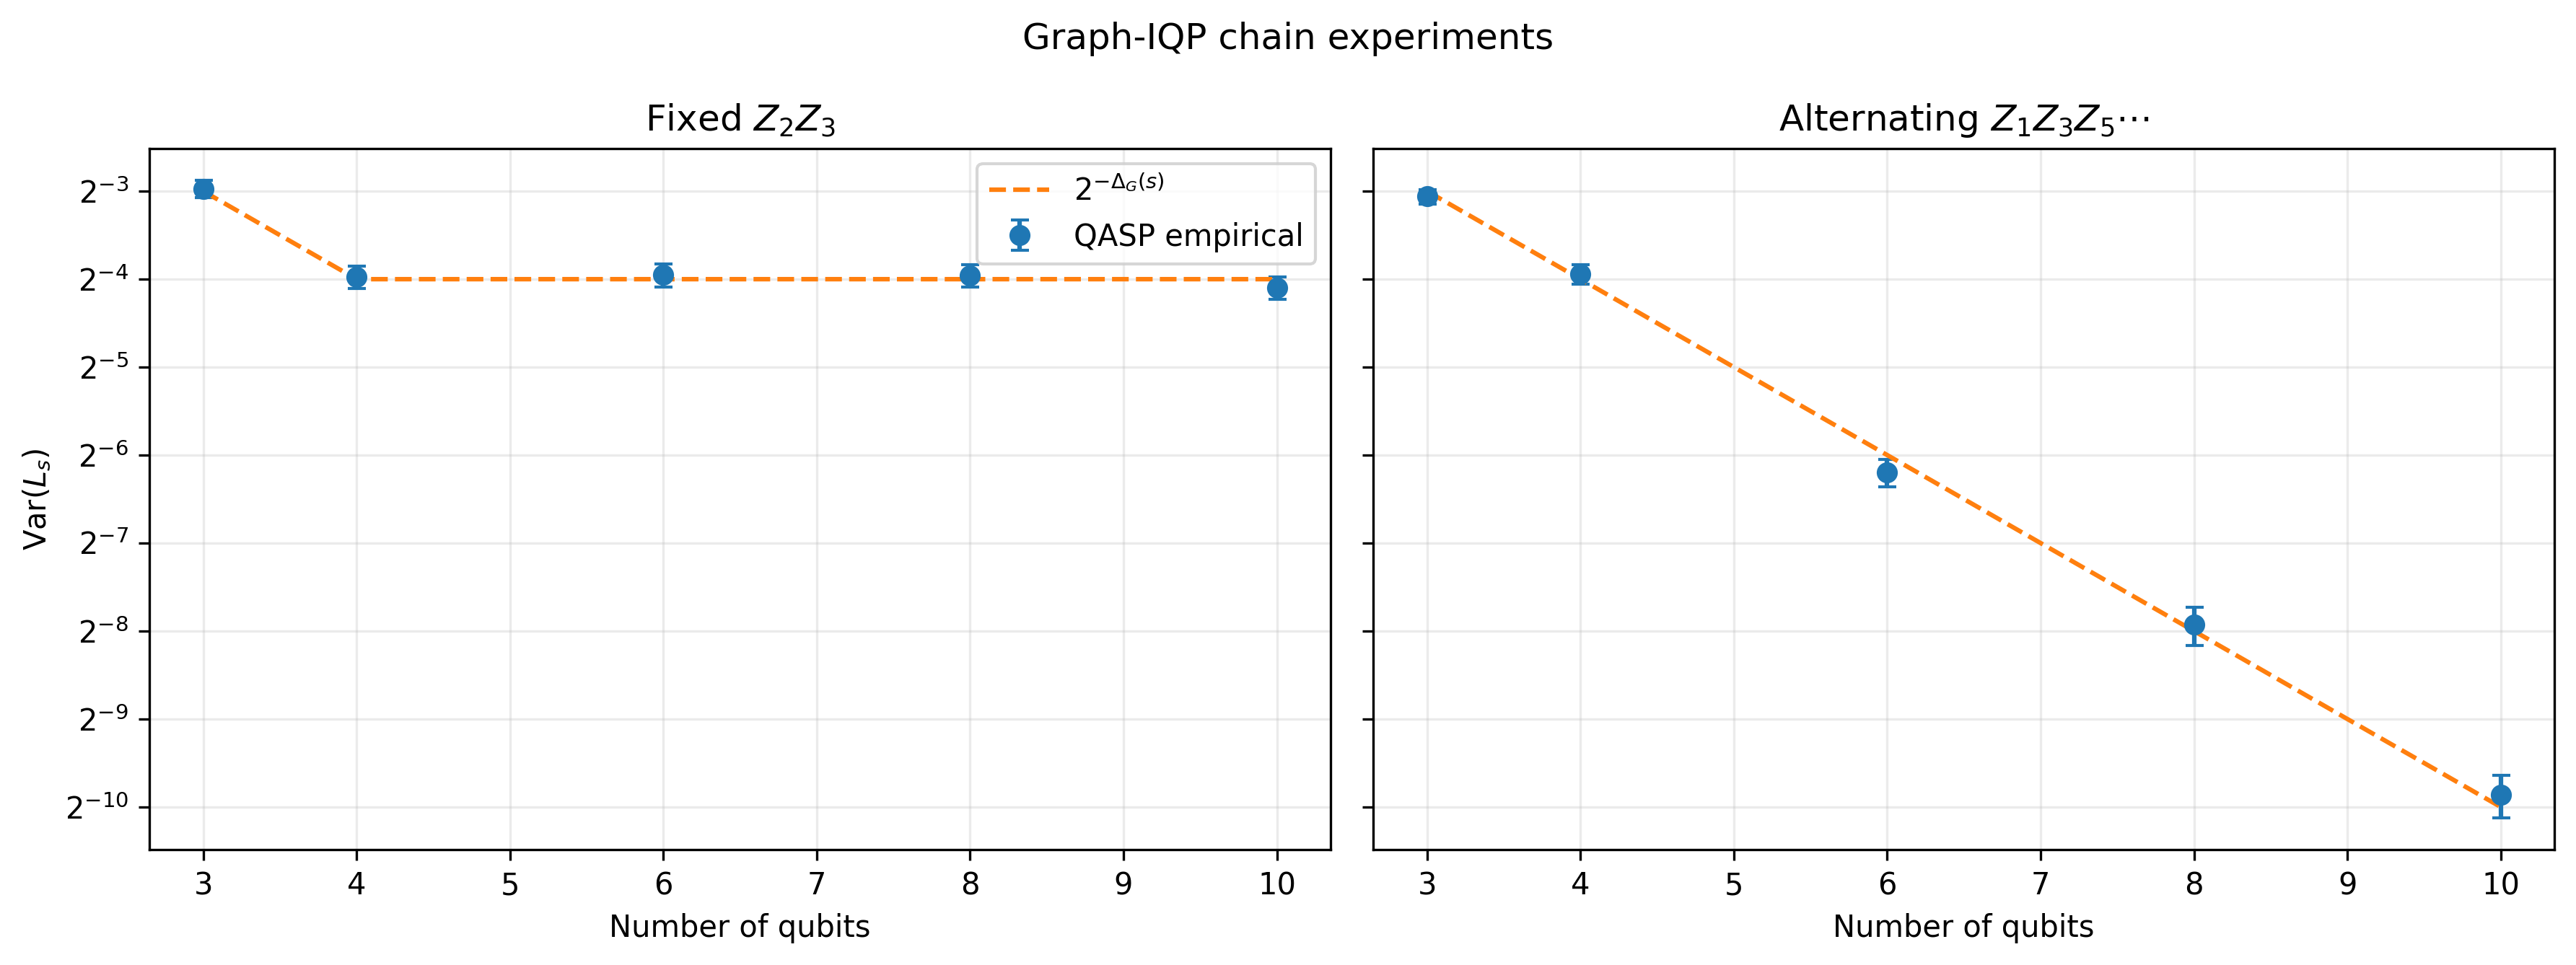

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, dpi=FIGURE_DPI)
for ax, name, title in [
    (axes[0], 'graph IQP / chain / Z2Z3', r'Fixed $Z_2Z_3$'),
    (axes[1], 'graph IQP / chain / alternating', r'Alternating $Z_1Z_3Z_5\cdots$'),
]:
    part = graph_df[graph_df['experiment'] == name]
    ax.errorbar(part['n'], part['empirical_variance'], yerr=2 * part['mc_se'],
                fmt='o', capsize=3, label='QASP empirical')
    ax.plot(part['n'], part['light_cone_prediction'], '--', label=r'$2^{-\Delta_G(s)}$')
    ax.set(title=title, xlabel='Number of qubits')
    ax.set_yscale('log', base=2)
    ax.grid(True, which='both', alpha=0.25)
axes[0].set_ylabel(r'$\mathrm{Var}(L_s)$')
axes[0].legend()
fig.suptitle('Graph-IQP chain experiments')
fig.tight_layout()
plt.show()

<a id="experiment-3"></a>

## Experiment 3 — rank vs. light-cone counterexample

Take the pure $R_{XX}$ triangle with generators $X_1X_2$, $X_2X_3$, and $X_1X_3$, and measure $Z_1Z_2$. The generator $X_1X_2$ commutes with the observable and is omitted from $G_s$. The other two columns touch all three qubits ($\Delta=3$) but have binary rank 2. Therefore the exact prediction is $2^{-2}=1/4$, not $2^{-3}=1/8$.

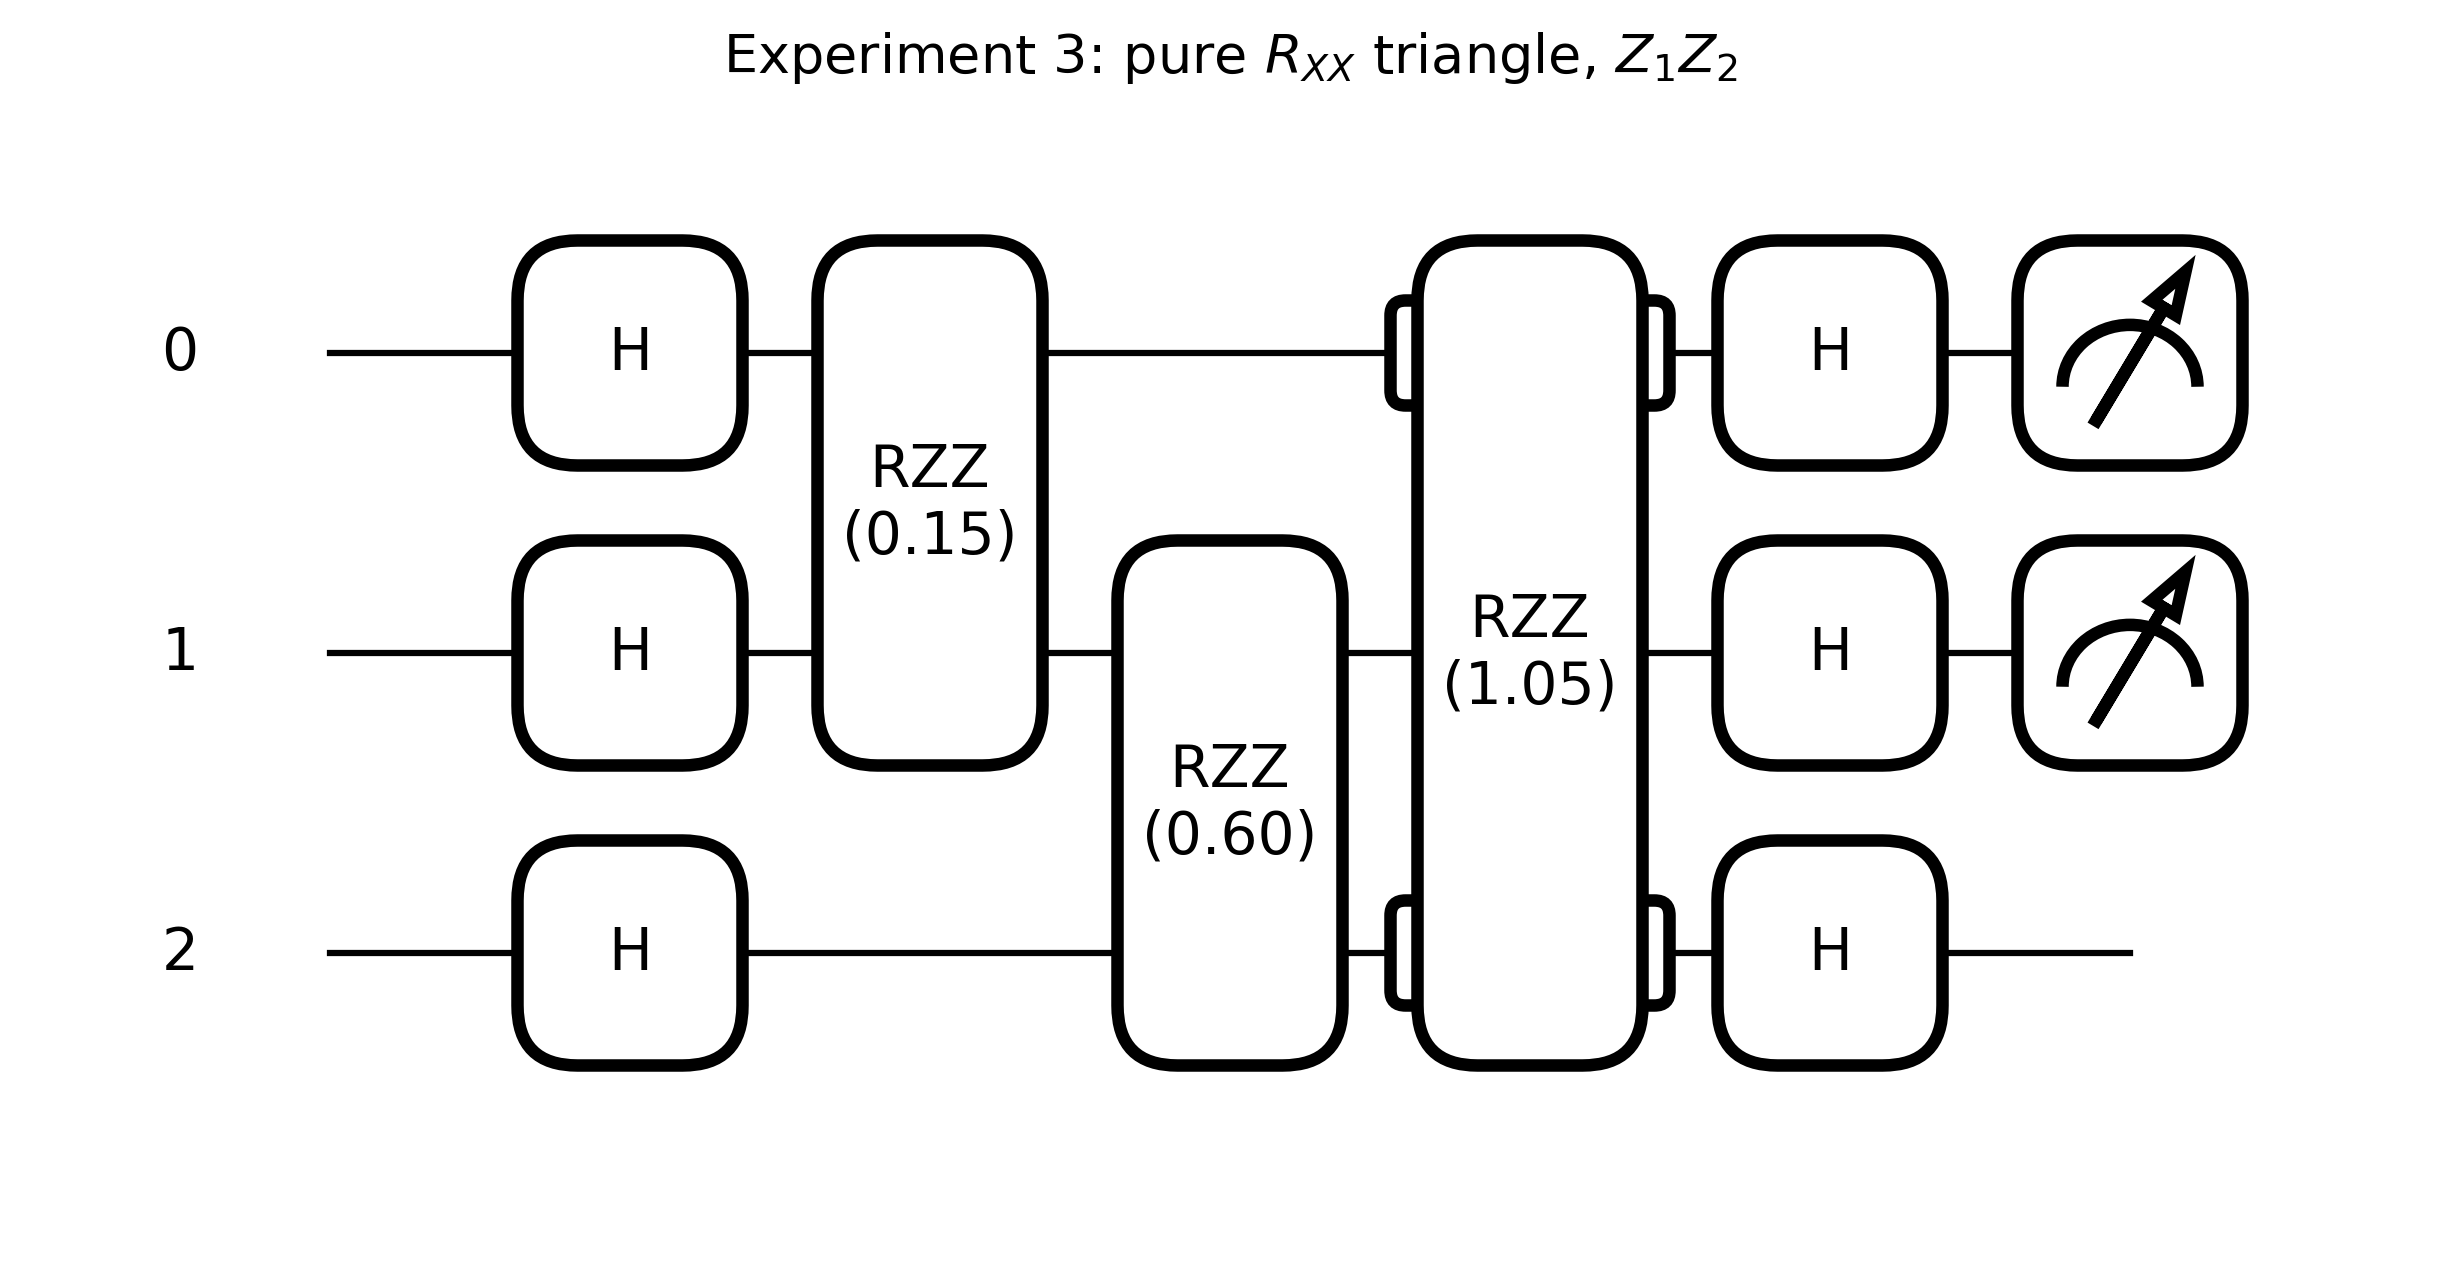

In [43]:
draw_qasp_iqp(
    n=3,
    edges=[(0, 1), (1, 2), (0, 2)],
    support=(0, 1),
    include_local=False,
    title=r'Experiment 3: pure $R_{XX}$ triangle, $Z_1Z_2$',
)

In [44]:
triangle_edges = [(0, 1), (1, 2), (0, 2)]
triangle_support = (0, 1)
triangle_G, triangle_labels = binary_generator_matrix(
    n=3, edges=triangle_edges, support=triangle_support, include_local=False
)
display(matrix_frame(triangle_G, triangle_labels))
triangle_rank = gf2_rank(triangle_G)
triangle_delta = light_cone_size(triangle_G)
print(f'delta = {triangle_delta}, rank_GF2(G_s) = {triangle_rank}')
assert triangle_delta == 3 and triangle_rank == 2

,X2X3,X1X3
q1,0,1
q2,1,0
q3,1,1


delta = 3, rank_GF2(G_s) = 2


In [45]:
triangle_row = run_case(
    n=3,
    edges=triangle_edges,
    support=triangle_support,
    include_local=False,
    experiment='pure RXX / triangle counterexample',
    seed=SEED + 999,
)
triangle_df = pd.DataFrame([triangle_row])
display(triangle_df.round(7))
print(f"QASP empirical variance: {triangle_row['empirical_variance']:.6f} ± {2 * triangle_row['mc_se']:.6f} (approx. 95% MC)")
print(f"rank prediction:       {triangle_row['rank_prediction']:.6f}")
print(f"light-cone guess:      {triangle_row['light_cone_prediction']:.6f}")

,experiment,n,observable,rank,delta,empirical_variance,mc_se,rank_prediction,light_cone_prediction,sample_mean,z_score
0,pure RXX / triangle counterexample,3,ZZ 0 1,2,3,0.250781,0.006234,0.25,0.125,0.005336,0.125214


QASP empirical variance: 0.250781 ± 0.012468 (approx. 95% MC)
rank prediction:       0.250000
light-cone guess:      0.125000


<a id="observable-scaling"></a>

## Combined scaling plot and numerical checks

The final log-scale figure compares the two families with growing rank. Error bars show twice the plug-in Monte Carlo standard error of the sample variance. The checks flag a result only when it is more than five estimated Monte Carlo standard errors from the exact law.

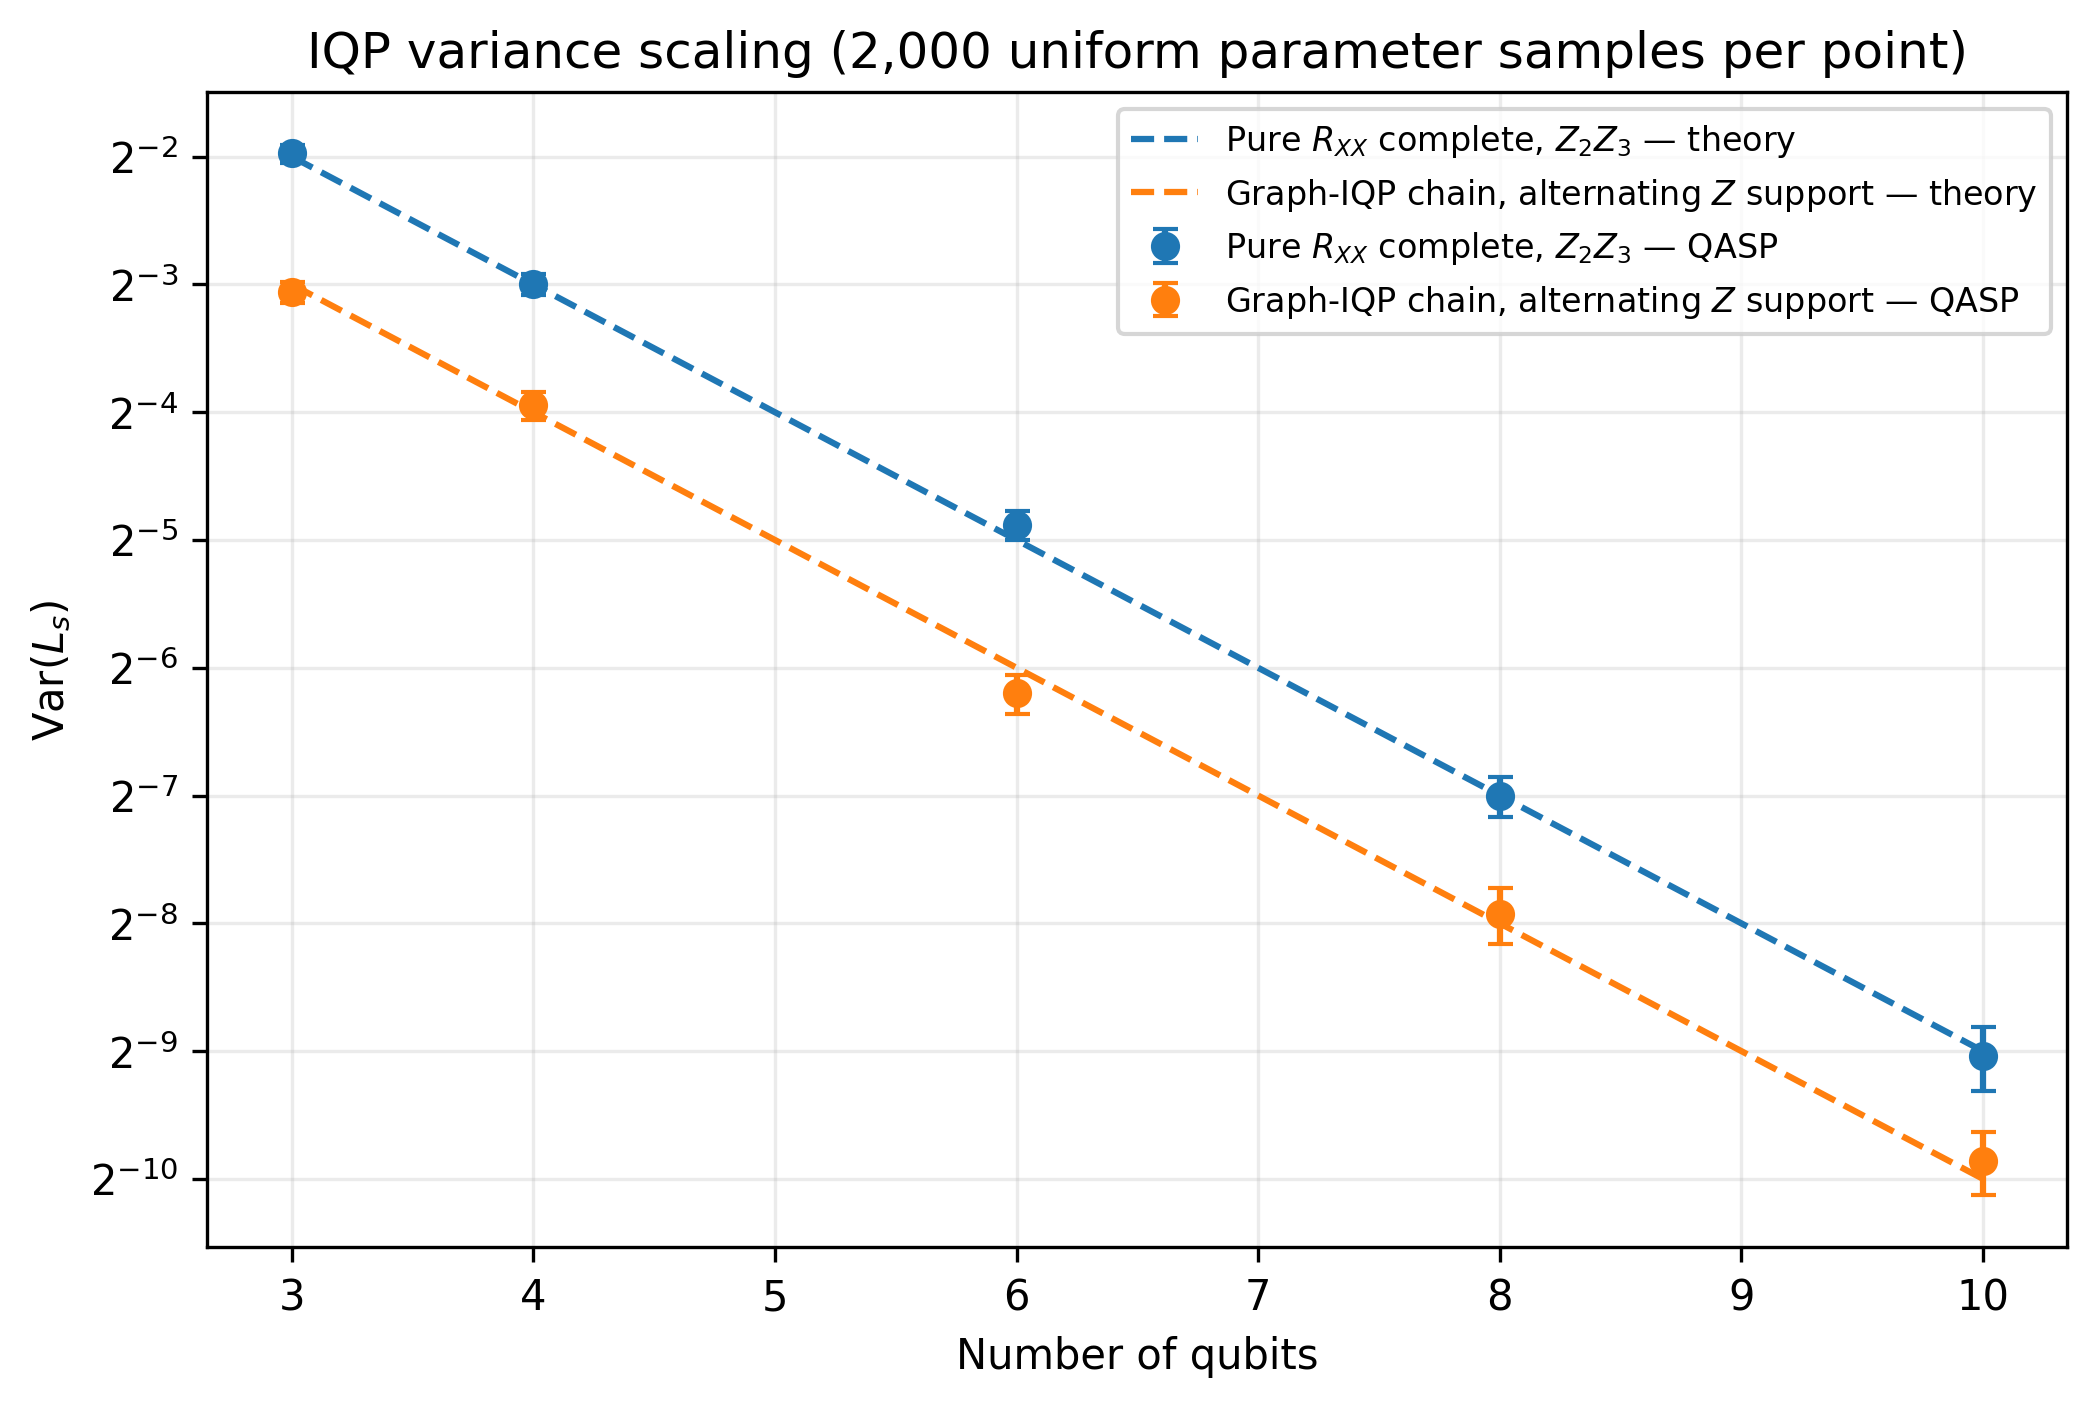

In [46]:
alternating_df = graph_df[graph_df['experiment'] == 'graph IQP / chain / alternating']
fig, ax = plt.subplots(figsize=(8, 5), dpi=FIGURE_DPI)
for frame, color, label in [
    (pure_df, 'tab:blue', r'Pure $R_{XX}$ complete, $Z_2Z_3$'),
    (alternating_df, 'tab:orange', r'Graph-IQP chain, alternating $Z$ support'),
]:
    ax.errorbar(frame['n'], frame['empirical_variance'], yerr=2 * frame['mc_se'],
                fmt='o', color=color, capsize=3, label=f'{label} — QASP')
    ax.plot(frame['n'], frame['rank_prediction'], '--', color=color, label=f'{label} — theory')
ax.set(xlabel='Number of qubits', ylabel=r'$\mathrm{Var}(L_s)$',
       title=f'IQP variance scaling ({N_SAMPLES:,} uniform parameter samples per point)')
ax.set_yscale('log', base=2)
ax.grid(True, which='both', alpha=0.25)
ax.legend(fontsize=8)
plt.show()

In [47]:
all_results = pd.concat([pure_df, graph_df, triangle_df], ignore_index=True)
all_results['within_5_mc_se'] = (
    (all_results['empirical_variance'] - all_results['rank_prediction']).abs()
    <= 5 * all_results['mc_se']
)
summary_columns = [
    'experiment', 'n', 'rank', 'delta', 'empirical_variance',
    'rank_prediction', 'mc_se', 'z_score', 'within_5_mc_se'
]
display(all_results[summary_columns].round(7))
if all_results['within_5_mc_se'].all():
    print('All empirical variances agree with the binary-rank law within 5 estimated MC standard errors.')
else:
    flagged = all_results.loc[~all_results['within_5_mc_se'], ['experiment', 'n', 'z_score']]
    print('Monte Carlo warning: the following points are outside the plug-in 5-SE band.')
    display(flagged)
    print('Increase N_SAMPLES before interpreting these points; deterministic rank assertions still passed.')

,experiment,n,rank,delta,empirical_variance,rank_prediction,mc_se,z_score,within_5_mc_se
0,pure RXX / complete,3,2,3,0.254453,0.250000,0.006231,0.714562,True
1,pure RXX / complete,4,3,4,0.125237,0.125000,0.003687,0.064147,True
2,pure RXX / complete,6,5,6,0.033921,0.031250,0.001363,1.960141,True
3,pure RXX / complete,8,7,8,0.007790,0.007812,0.000420,-0.052687,True
4,pure RXX / complete,10,9,10,0.001898,0.001953,0.000161,-0.344021,True
5,graph IQP / chain / Z2Z3,3,3,3,0.127370,0.125000,0.004352,0.544572,True
6,graph IQP / chain / alternating,3,3,3,0.119965,0.125000,0.003446,-1.461002,True
7,graph IQP / chain / Z2Z3,4,4,4,0.063741,0.062500,0.002844,0.436260,True
8,graph IQP / chain / alternating,4,4,4,0.064985,0.062500,0.002479,1.002674,True
9,graph IQP / chain / Z2Z3,6,4,4,0.064620,0.062500,0.002914,0.727381,True


All empirical variances agree with the binary-rank law within 5 estimated MC standard errors.


<a id="policy-experiments"></a>

## Experiments 4–6 — contiguous, recursive parity, and modulo policies

The corrected results from the earlier *Uniform vs Normal Initialization* discussion concern action probabilities rather than a single Pauli expectation. For an action projector
$$\Pi_a=\sum_{s\in\mathbb F_2^n}c_{a,s}Z^s,$$
the graph-IQP variance law gives
$$\boxed{\operatorname{Var}[\pi(a)]=\sum_{s\ne0}c_{a,s}^2 2^{-\Delta_G(s)}}.$$
The implementation below uses the light-cone shortcut for this graph-IQP family and the grouped binary-rank formula derived below for the pure-$R_{XX}$ family.

For a power-of-two contiguous action set $|A|=2^k$, action $a$ fixes the first $k$ computational-basis bits and
$$\Pi_a=\frac1{2^k}\sum_{S\subseteq[k]}(-1)^{a\cdot S}Z^S,\qquad\operatorname{Var}[\pi(a)]=\frac1{|A|^2}\sum_{\emptyset\ne S\subseteq[k]}2^{-\Delta_G(S)}.$$
In particular, $|A|=2$ gives $\operatorname{Var}[\pi(0)]=2^{-\Delta_G(\{0\})-2}$.

For recursive parity with $|A|=2^k$, define $P_m=Z_0\cdots Z_{m-1}$. Then
$$\Pi_a=\prod_{j=0}^{k-1}\frac{I+(-1)^{a_j}P_{n-j}}2,\qquad\operatorname{Var}[\pi(a)]=\frac1{4^k}\sum_{\emptyset\ne S\subseteq[k]}2^{-\Delta_G(P_S)}.$$
Thus $|A|=2$ has variance $2^{-n-2}$ on graph IQP, while $|A|=4$ also contains the one-local term $Z_{n-1}$ and need not concentrate exponentially.

For a modulo policy, the action is $a=x\bmod |A|$, where $x$ is the integer represented by the computational-basis string. If $|A|=2^k$, this extracts the last $k$ bits and the projector factorizes exactly like the contiguous case, but on the final $k$ qubits:
$$\operatorname{Var}[\pi(a)]=\frac1{|A|^2}\sum_{\emptyset\ne S\subseteq\{n-k,\ldots,n-1\}}2^{-\Delta_G(S)}.$$
For non-power-of-two action sets, its exact variance is determined by the Walsh spectrum of the modular indicator $\mathbf 1[x\bmod |A|=a]$.

All experiments below measure **action $a=0$**. For $|A|=n$ with non-power-of-two $n$, both recursive parity and modulo require their exact non-power-of-two maps. Rather than applying a power-of-two formula incorrectly, we enumerate each QASP-compatible binning map and calculate its Walsh–Pauli spectrum.

### Pure $R_{XX}$ policy correction

The graph-IQP formula above treats distinct Walsh strings independently because the local $R_{X_i}$ generators make their generator syndromes distinct. In a pure $R_{XX}$ circuit this is no longer true. If $B$ is the binary matrix containing **all** $R_{XX}$ generator supports, define the syndrome $y_s=B^Ts$. Strings with the same syndrome are identical on the symmetry sector reached from $|0^n\rangle$, so their coefficients must first be combined:
$$C_y=\sum_{s:B^Ts=y}c_{a,s}.$$
The exact mean and variance are then
$$\boxed{\mathbb E[\pi(a)]=C_0,\qquad \operatorname{Var}[\pi(a)]=\sum_{y\ne0}C_y^2 2^{-\operatorname{rank}_{\mathbb F_2}(B_y)}}.$$
Here $B_y$ retains the generator columns selected by the nonzero entries of $y$. This grouping captures conserved parity sectors—for example, binary parity action $0$ is deterministic in a pure $R_{XX}$ circuit initialized in $|0^n\rangle$, independently of whether the interaction graph is a chain, ring, or another graph.

In [2]:
def contiguous_action_map(n, n_actions):
    """QASP contiguous-like map using the first ceil(log2|A|) bits."""
    m = int(np.ceil(np.log2(n_actions)))
    if not (2 <= n_actions <= 2**n) or m > n:
        raise ValueError('Need 2 <= |A| <= 2**n.')
    prefix_states = np.arange(2**n, dtype=np.uint64) >> (n - m)
    base, remainder = divmod(2**m, n_actions)
    sizes = np.array([base + (a < remainder) for a in range(n_actions)], dtype=int)
    upper_edges = np.cumsum(sizes)
    return np.searchsorted(upper_edges, prefix_states, side='right')


def parity_action_map(n, n_actions):
    """QASP recursive parity-like map, including modulo for non-powers of two."""
    m = int(np.ceil(np.log2(n_actions)))
    if not (2 <= n_actions <= 2**n) or m > n:
        raise ValueError('Need 2 <= |A| <= 2**n.')
    actions = np.empty(2**n, dtype=int)
    for state in range(2**n):
        bits = np.array(list(np.binary_repr(state, width=n)), dtype=int)
        parity_bits = [int(bits[:n - j].sum() % 2) for j in range(m)]
        raw_label = 0
        for bit in parity_bits:
            raw_label = (raw_label << 1) | bit
        actions[state] = raw_label % n_actions
    return actions


def modulo_action_map(n, n_actions):
    """Modulo policy a(x)=x mod |A| for the n-bit basis-state integer x."""
    if not (2 <= n_actions <= 2**n):
        raise ValueError('Need 2 <= |A| <= 2**n.')
    return np.arange(2**n, dtype=np.uint64) % n_actions


def policy_action_map(n, n_actions, policy):
    if policy == 'contiguous':
        return contiguous_action_map(n, n_actions)
    if policy == 'parity-like':
        return parity_action_map(n, n_actions)
    if policy == 'modulo':
        return modulo_action_map(n, n_actions)
    raise ValueError(f'Unknown policy: {policy}')


def fwht_coefficients(diagonal):
    """Walsh coefficients c_s in diag(Pi)=sum_s c_s (-1)^(s.x)."""
    coeffs = np.asarray(diagonal, dtype=float).copy()
    length = len(coeffs)
    if length == 0 or length & (length - 1):
        raise ValueError('Walsh transform requires a power-of-two length.')
    width = 1
    while width < length:
        for start in range(0, length, 2 * width):
            left = coeffs[start:start + width].copy()
            right = coeffs[start + width:start + 2 * width].copy()
            coeffs[start:start + width] = left + right
            coeffs[start + width:start + 2 * width] = left - right
        width *= 2
    return coeffs / length


def integer_support(mask, n):
    return tuple(q for q in range(n) if (mask >> (n - 1 - q)) & 1)


def chain_closed_neighborhood_size(mask, n):
    """Delta_G(s) for a chain graph, evaluated directly with bit operations."""
    valid_bits = (1 << n) - 1
    closed_neighborhood = mask | (mask << 1) | (mask >> 1)
    return int((closed_neighborhood & valid_bits).bit_count())


def generator_integer_masks(n, edges, include_local):
    masks = []
    if include_local:
        masks.extend(1 << (n - 1 - q) for q in range(n))
    for i, j in edges:
        masks.append((1 << (n - 1 - i)) | (1 << (n - 1 - j)))
    return masks


def generator_syndrome(mask, generator_masks):
    syndrome = 0
    for index, generator_mask in enumerate(generator_masks):
        syndrome |= ((mask & generator_mask).bit_count() & 1) << index
    return syndrome


def chain_edge_sector_delta(syndrome, n):
    """Number of vertices touched by the selected chain-edge generators."""
    touched = 0
    for edge in range(n - 1):
        if (syndrome >> edge) & 1:
            touched |= (1 << (n - 1 - edge)) | (1 << (n - 2 - edge))
    return int(touched.bit_count())

In [6]:
def policy_rank_prediction(
    n, edges, n_actions, policy, action=0, include_local=True, collect_spectrum=True
):
    action_map = policy_action_map(n, n_actions, policy)
    diagonal = (action_map == action).astype(float)
    coeffs = fwht_coefficients(diagonal)
    variance = 0.0
    spectrum = []
    n_spectrum_terms = int(np.count_nonzero(np.abs(coeffs[1:]) >= 1e-12))
    is_chain = list(edges) == chain_edges(n)

    if include_local and is_chain:
        # Local RX generators make every nonzero syndrome unique, so the
        # familiar independent Walsh-term sum is exact.
        theory_mean = float(coeffs[0])
        for mask, coefficient in enumerate(coeffs):
            if mask == 0 or abs(coefficient) < 1e-12:
                continue
            delta = chain_closed_neighborhood_size(mask, n)
            rank = delta
            contribution = coefficient**2 * 2.0**(-rank)
            variance += contribution
            if collect_spectrum:
                spectrum.append({
                    'support': integer_support(mask, n),
                    'coefficient': coefficient, 'rank': rank,
                    'delta': delta, 'contribution': contribution,
                })
    else:
        # Without local RX rotations, several Pauli-Z strings can have the
        # same generator syndrome. They are the same random variable in the
        # symmetry sector, so their Walsh coefficients must be added first.
        generator_masks = generator_integer_masks(n, edges, include_local)
        grouped_coefficients = {}
        grouped_members = {}
        for mask, coefficient in enumerate(coeffs):
            if abs(coefficient) < 1e-12:
                continue
            syndrome = generator_syndrome(mask, generator_masks)
            grouped_coefficients[syndrome] = grouped_coefficients.get(syndrome, 0.0) + coefficient
            if collect_spectrum:
                grouped_members.setdefault(syndrome, []).append(integer_support(mask, n))

        theory_mean = float(grouped_coefficients.get(0, 0.0))
        generators, _ = generator_supports(n, edges, include_local)
        for syndrome, combined_coefficient in grouped_coefficients.items():
            if syndrome == 0 or abs(combined_coefficient) < 1e-12:
                continue
            if not include_local and is_chain:
                rank = int(syndrome.bit_count())
                delta = chain_edge_sector_delta(syndrome, n)
            else:
                active = [
                    generators[index] for index in range(len(generators))
                    if (syndrome >> index) & 1
                ]
                G_y = np.column_stack(active) if active else np.zeros((n, 0), dtype=np.uint8)
                rank = gf2_rank(G_y)
                delta = light_cone_size(G_y)
            contribution = combined_coefficient**2 * 2.0**(-rank)
            variance += contribution
            if collect_spectrum:
                spectrum.append({
                    'syndrome': syndrome,
                    'member_supports': grouped_members[syndrome],
                    'combined_coefficient': combined_coefficient,
                    'rank': rank, 'delta': delta,
                    'contribution': contribution,
                })

    # Parseval: sum_s c_s^2 = 2^-n Tr(Pi_a) for a diagonal projector.
    assert np.isclose(np.sum(coeffs**2), diagonal.mean())
    spectrum_result = pd.DataFrame(spectrum) if collect_spectrum else n_spectrum_terms
    return variance, spectrum_result, diagonal, coeffs, theory_mean


# Explicitly recover the corrected |A|=2 and |A|=4 formulas on a six-qubit chain.
for policy, n_actions in [
    ('contiguous', 2), ('contiguous', 4),
    ('parity-like', 2), ('parity-like', 4),
    ('modulo', 2), ('modulo', 4),
]:
    prediction, spectrum, diagonal, coeffs, theory_mean = policy_rank_prediction(
        n=6, edges=chain_edges(6), n_actions=n_actions, policy=policy
    )
    print(f'\n{policy}, |A|={n_actions}: action-0 bin fraction={diagonal.mean():.3f}, mean={theory_mean:.3f}, variance={prediction:.8f}')
    display(spectrum.round(8))

print('\nPure-RXX ring: coefficients sharing an edge syndrome are combined first')
for policy, n_actions in [
    ('contiguous', 2), ('contiguous', 4),
    ('parity-like', 2), ('parity-like', 4),
    ('modulo', 2), ('modulo', 4),
]:
    prediction, spectrum, diagonal, coeffs, theory_mean = policy_rank_prediction(
        n=6, edges=ring_edges(6), n_actions=n_actions, policy=policy,
        include_local=False,
    )
    print(f'\n{policy}, |A|={n_actions}: mean={theory_mean:.3f}, variance={prediction:.8f}')
    display(spectrum.round(8))

binary_parity_ring = policy_rank_prediction(
    n=6, edges=ring_edges(6), n_actions=2, policy='parity-like',
    include_local=False, collect_spectrum=False,
)
assert np.isclose(binary_parity_ring[0], 0.0)
assert np.isclose(binary_parity_ring[4], 1.0)
print(
    '\nBinary parity remains deterministic on the ring: '
    f'mean={binary_parity_ring[4]:.1f}, variance={binary_parity_ring[0]:.1f}'
)


contiguous, |A|=2: action-0 bin fraction=0.500, mean=0.500, variance=0.06250000


,support,coefficient,rank,delta,contribution
0,"(0,)",0.5,2,2,0.0625



contiguous, |A|=4: action-0 bin fraction=0.250, mean=0.250, variance=0.03125000


,support,coefficient,rank,delta,contribution
0,"(1,)",0.25,3,3,0.007812
1,"(0,)",0.25,2,2,0.015625
2,"(0, 1)",0.25,3,3,0.007812



parity-like, |A|=2: action-0 bin fraction=0.500, mean=0.500, variance=0.00390625


,support,coefficient,rank,delta,contribution
0,"(0, 1, 2, 3, 4, 5)",0.5,6,6,0.003906


... (15 outputs left out)

,syndrome,member_supports,combined_coefficient,rank,delta,contribution
0,48,"[(5,)]",0.5,2,3,0.0625



modulo, |A|=4: mean=0.250, variance=0.04687500


,syndrome,member_supports,combined_coefficient,rank,delta,contribution
0,48,"[(5,)]",0.25,2,3,0.015625
1,24,"[(4,)]",0.25,2,3,0.015625
2,40,"[(4, 5)]",0.25,2,4,0.015625



Binary parity remains deterministic on the ring: mean=1.0, variance=0.0


<a id="policy-monte-carlo"></a>

### QASP Monte Carlo policy experiment

For each circuit family and size, one QASP probability QNode is evaluated at the same $N_{\rm samples}$ parameter vectors for all nine policy/action-set combinations. The classical action maps are then applied to the returned computational-basis probabilities. Reusing each circuit evaluation this way both matches QASP's policy semantics and avoids nine redundant simulations. We run the full grid twice: first with local $R_X$ plus **chain** $R_{XX}$ generators, and then with only **ring** $R_{XX}$ generators.

> **Binary-parity warning.** Replacing the chain by a ring does not make the pure-$R_{XX}$, $|A|=2$ parity-like variance nonzero. Every $R_{XX}^{(i,j)}$ commutes with $P=Z_0\cdots Z_{n-1}$, and $|0^n\rangle$ starts in the $P=+1$ sector. Thus the even-parity action has probability one for every parameter vector and its variance is exactly zero. The ring changes the non-protected policy curves, not this symmetry-protected case. Any outputs immediately below that were produced before this edit are retained for provenance and should be regenerated by rerunning the Monte Carlo and plotting cells.

In [7]:
def build_qasp_iqp_probs(n, edges, include_local=True):
    ansatz = IQPAnsatz(
        n_qubits=n, n_layers=1, imprimitive_pattern=edges,
        include_single_qubit=include_local,
    )
    builder = CircuitBuilder(n_qubits=n)
    builder.set_ansatz(ansatz)
    builder.set_measurement('probs', wires=list(range(n)))
    builder.build()
    qnode = builder.compile(device='default.qubit', diff_method=None)
    return qnode, ansatz.get_param_shapes()[0][0]


def variance_and_mc_se(values):
    values = np.asarray(values, dtype=float)
    variance = values.var(ddof=1)
    fourth = np.mean((values - values.mean())**4)
    mc_se = np.sqrt(max(fourth - ((len(values) - 3) / (len(values) - 1)) * variance**2, 0) / len(values))
    return variance, mc_se


def run_policy_experiments_for_n(n, n_samples, seed, circuit_family='graph_iqp'):
    if circuit_family not in {'graph_iqp', 'pure_rxx'}:
        raise ValueError("circuit_family must be 'graph_iqp' or 'pure_rxx'")
    include_local = circuit_family == 'graph_iqp'
    if include_local:
        circuit_label = 'graph IQP chain (RX + RXX)'
        topology = 'chain'
        edges = chain_edges(n)
    else:
        circuit_label = 'pure RXX ring'
        topology = 'ring'
        edges = ring_edges(n)
    specifications = []
    for policy in ['contiguous', 'parity-like', 'modulo']:
        for action_case, n_actions in [('2', 2), ('4', 4), ('n', n)]:
            action_map = policy_action_map(n, n_actions, policy)
            action_mask = (action_map == 0).astype(float)
            theory, n_pauli_terms, _, _, theory_mean = policy_rank_prediction(
                n, edges, n_actions, policy, action=0, include_local=include_local,
                collect_spectrum=False,
            )
            specifications.append({
                'policy': policy, 'action_case': action_case, 'n_actions': n_actions,
                'mask': action_mask, 'theory': theory,
                'theory_mean': theory_mean,
                'n_pauli_terms': n_pauli_terms, 'bin_fraction': action_mask.mean(),
            })

    qnode, n_parameters = build_qasp_iqp_probs(n, edges, include_local=include_local)
    rng = np.random.default_rng(seed)
    parameters = rng.uniform(-np.pi, np.pi, size=(n_samples, n_parameters))
    samples = np.empty((n_samples, len(specifications)))
    for sample_index, theta in enumerate(parameters):
        basis_probabilities = np.asarray(qnode(params=theta), dtype=float)
        for spec_index, spec in enumerate(specifications):
            samples[sample_index, spec_index] = basis_probabilities @ spec['mask']

    rows = []
    for spec_index, spec in enumerate(specifications):
        empirical, mc_se = variance_and_mc_se(samples[:, spec_index])
        rows.append({
            'circuit_family': circuit_family, 'circuit_label': circuit_label,
            'topology': topology,
            'policy': spec['policy'], 'action_case': spec['action_case'],
            'n_actions': spec['n_actions'], 'n': n, 'action': 0,
            'bin_fraction': spec['bin_fraction'],
            'n_pauli_terms': spec['n_pauli_terms'],
            'empirical_variance': empirical, 'mc_se': mc_se,
            'theory_variance': spec['theory'],
            'sample_mean': samples[:, spec_index].mean(),
            'theory_mean': spec['theory_mean'],
            'mean_error': samples[:, spec_index].mean() - spec['theory_mean'],
            'z_score': (empirical - spec['theory']) / mc_se if mc_se > 0 else np.nan,
        })
    return rows

/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_3104/2937386807.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pure_policy_fig.tight_layout()


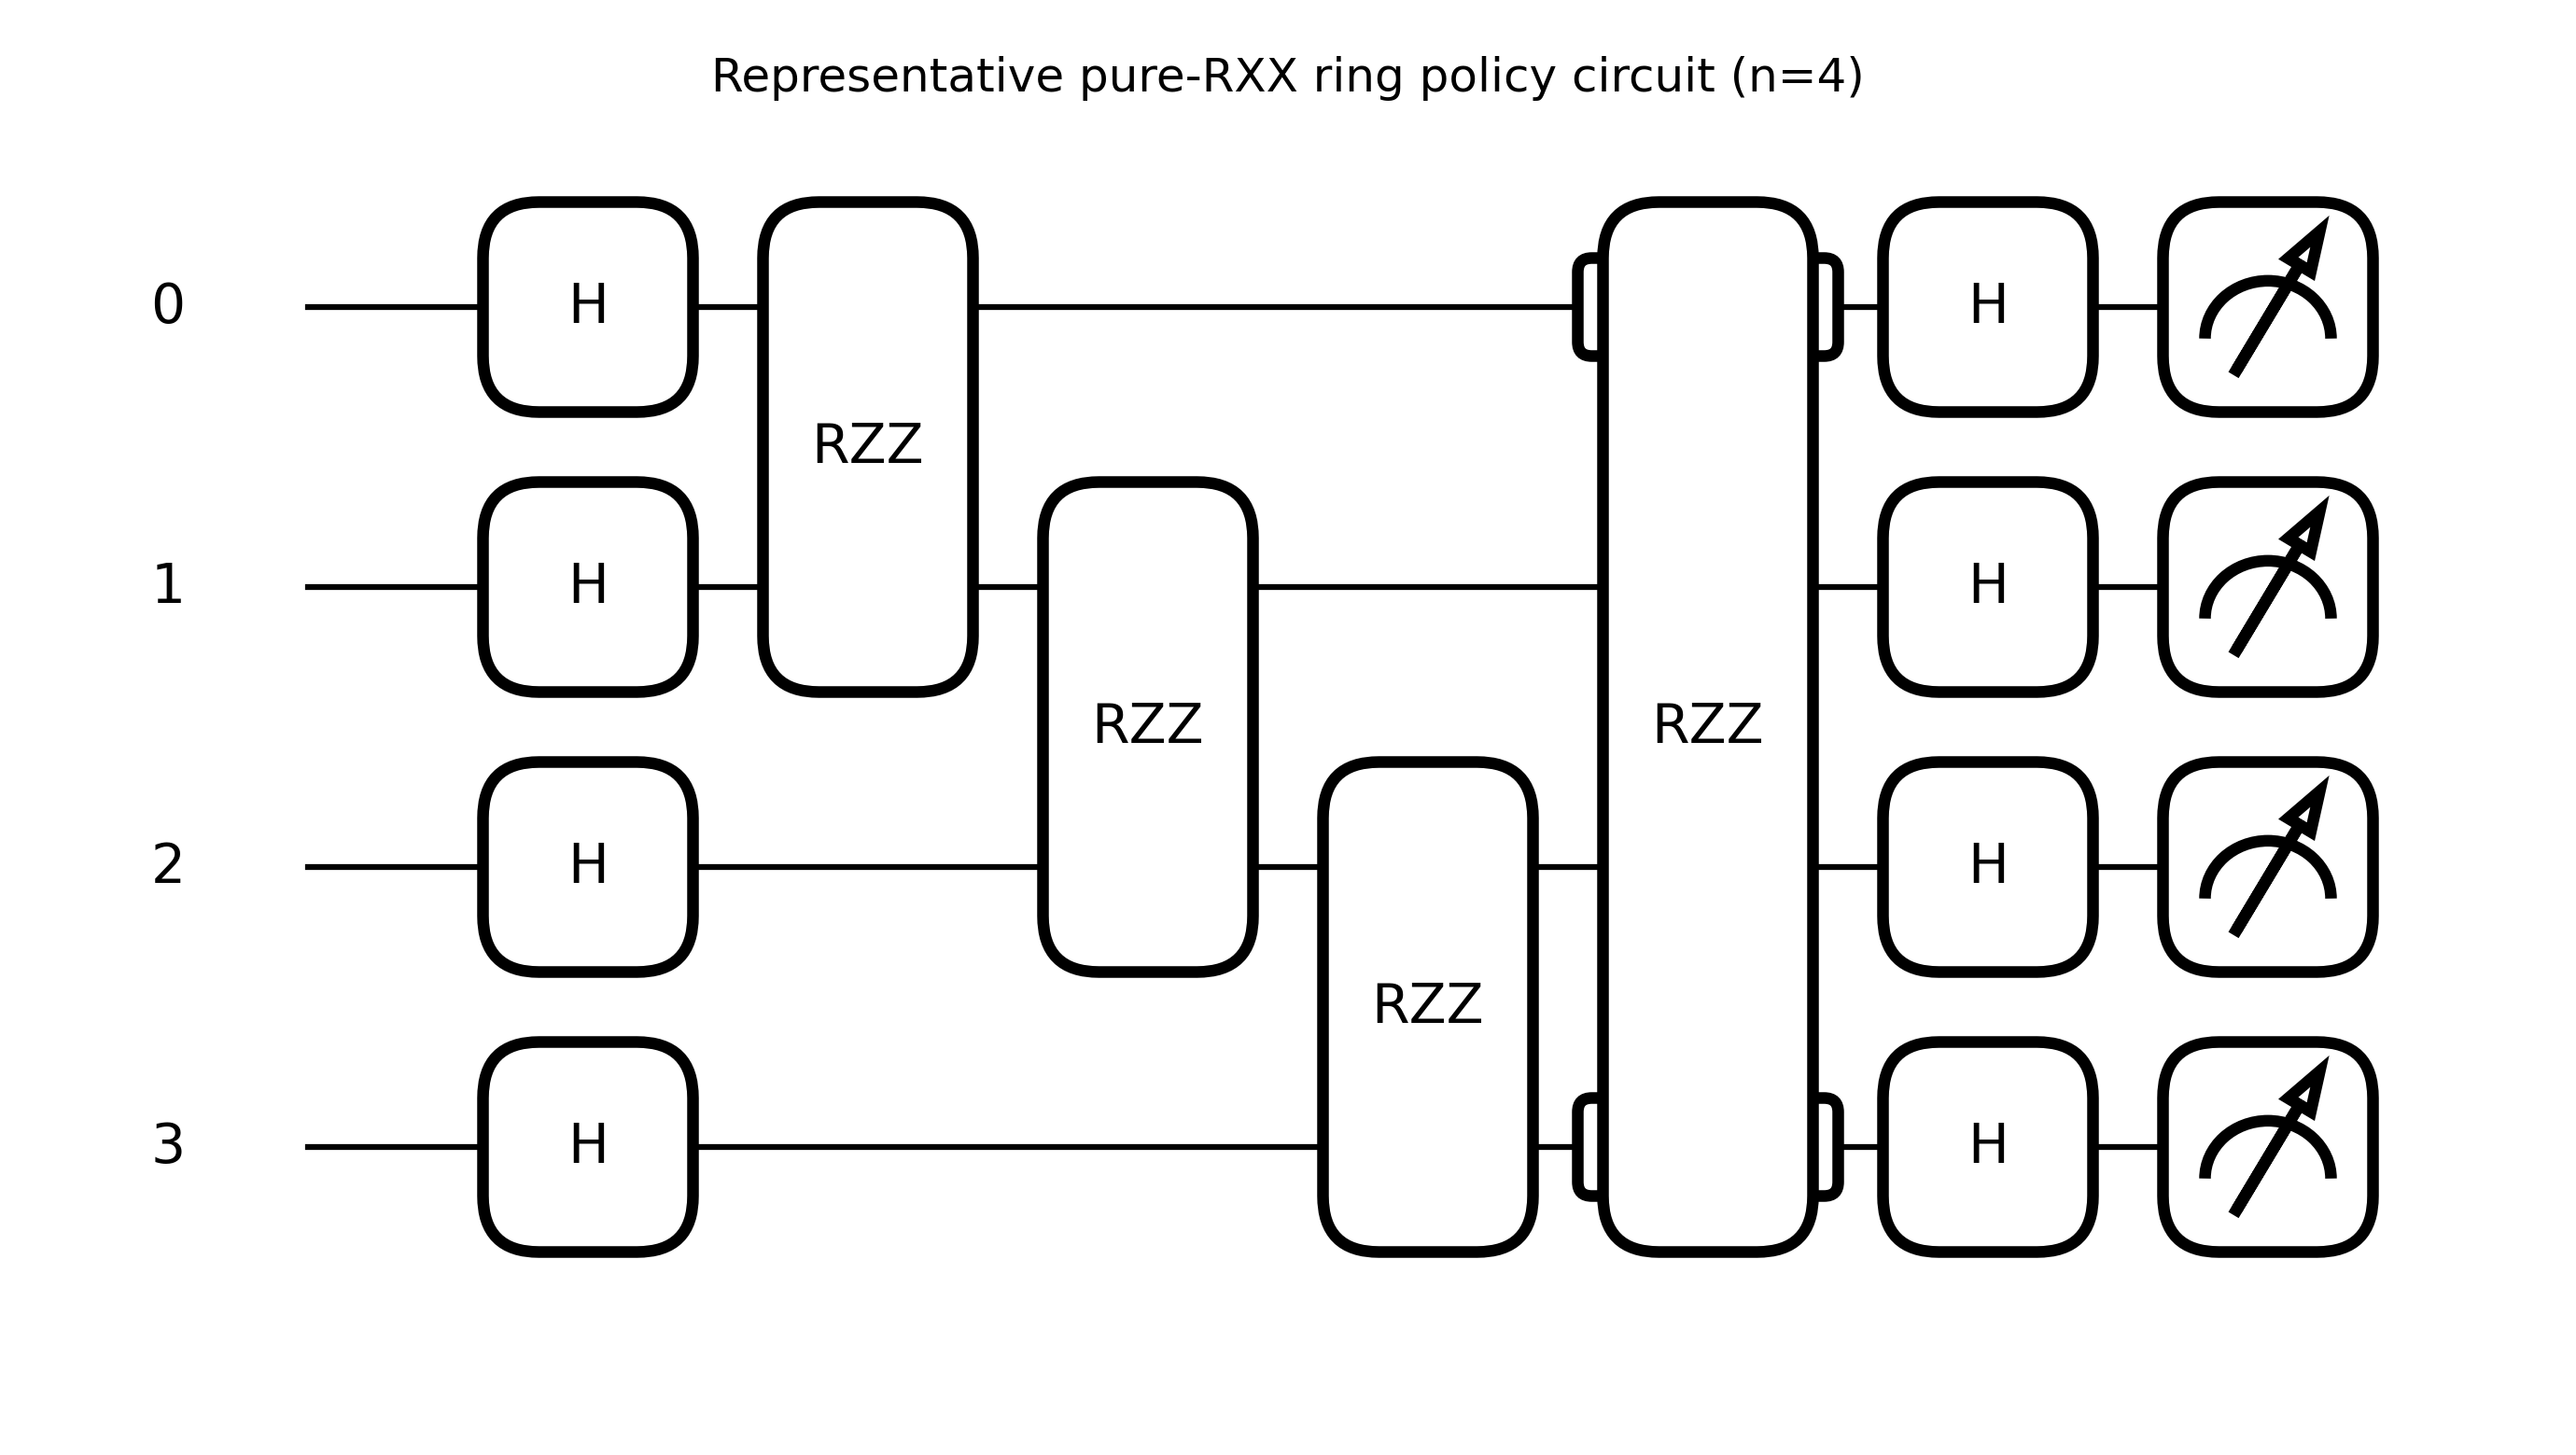

graph_iqp (chain): contiguous + parity-like + modulo, n=3, |A| in {2, 4, n}
graph_iqp (chain): contiguous + parity-like + modulo, n=4, |A| in {2, 4, n}
graph_iqp (chain): contiguous + parity-like + modulo, n=6, |A| in {2, 4, n}
graph_iqp (chain): contiguous + parity-like + modulo, n=8, |A| in {2, 4, n}
graph_iqp (chain): contiguous + parity-like + modulo, n=10, |A| in {2, 4, n}
graph_iqp (chain): contiguous + parity-like + modulo, n=12, |A| in {2, 4, n}
graph_iqp (chain): contiguous + parity-like + modulo, n=14, |A| in {2, 4, n}
graph_iqp (chain): contiguous + parity-like + modulo, n=16, |A| in {2, 4, n}
pure_rxx (ring): contiguous + parity-like + modulo, n=3, |A| in {2, 4, n}
pure_rxx (ring): contiguous + parity-like + modulo, n=4, |A| in {2, 4, n}
pure_rxx (ring): contiguous + parity-like + modulo, n=6, |A| in {2, 4, n}
pure_rxx (ring): contiguous + parity-like + modulo, n=8, |A| in {2, 4, n}
pure_rxx (ring): contiguous + parity-like + modulo, n=10, |A| in {2, 4, n}
pure_rxx (ring): 

,circuit_family,circuit_label,topology,policy,action_case,n_actions,n,action,bin_fraction,n_pauli_terms,empirical_variance,mc_se,theory_variance,sample_mean,theory_mean,mean_error,z_score
0,graph_iqp,graph IQP chain (RX + RXX),chain,contiguous,2,2,3,0,0.5000,1,0.065017,0.001592,0.062500,0.495649,0.5000,-0.004351,1.581185
1,graph_iqp,graph IQP chain (RX + RXX),chain,contiguous,4,4,3,0,0.2500,3,0.029980,0.001181,0.031250,0.240490,0.2500,-0.009510,-1.074887
2,graph_iqp,graph IQP chain (RX + RXX),chain,contiguous,n,3,3,0,0.5000,1,0.065017,0.001592,0.062500,0.495649,0.5000,-0.004351,1.581185
3,graph_iqp,graph IQP chain (RX + RXX),chain,parity-like,2,2,3,0,0.5000,1,0.035379,0.001165,0.031250,0.499637,0.5000,-0.000363,3.544666
4,graph_iqp,graph IQP chain (RX + RXX),chain,parity-like,4,4,3,0,0.2500,3,0.031666,0.001290,0.031250,0.244783,0.2500,-0.005217,0.322557
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,pure_rxx,pure RXX ring,ring,parity-like,4,4,16,0,0.2500,3,0.061598,0.001539,0.062500,0.489228,0.5000,-0.010772,-0.586275
140,pure_rxx,pure RXX ring,ring,parity-like,n,16,16,0,0.0625,15,0.022651,0.001285,0.024414,0.123671,0.1250,-0.001329,-1.372278
141,pure_rxx,pure RXX ring,ring,modulo,2,2,16,0,0.5000,1,0.061598,0.001539,0.062500,0.489228,0.5000,-0.010772,-0.586275
142,pure_rxx,pure RXX ring,ring,modulo,4,4,16,0,0.2500,3,0.046261,0.001719,0.046875,0.247252,0.2500,-0.002748,-0.356999


Elapsed: 284.2 s


In [8]:
# Draw a representative policy circuit to verify that the pure-RXX family
# contains edge rotations only (no local single-qubit rotations).
pure_policy_qnode, pure_policy_n_parameters = build_qasp_iqp_probs(
    4, ring_edges(4), include_local=False
)
pure_policy_theta = np.linspace(0.2, 0.8, pure_policy_n_parameters)
pure_policy_fig, _ = qml.draw_mpl(pure_policy_qnode)(params=pure_policy_theta)
pure_policy_fig.set_dpi(FIGURE_DPI)
pure_policy_fig.suptitle('Representative pure-RXX ring policy circuit (n=4)')
pure_policy_fig.tight_layout()
plt.show()

start = time.perf_counter()
policy_rows = []
for family_index, circuit_family in enumerate(['graph_iqp', 'pure_rxx']):
    for index, n in enumerate(POLICY_N_VALUES):
        topology = 'chain' if circuit_family == 'graph_iqp' else 'ring'
        print(f'{circuit_family} ({topology}): contiguous + parity-like + modulo, n={n}, |A| in {{2, 4, n}}')
        policy_rows.extend(run_policy_experiments_for_n(
            n, N_SAMPLES, SEED + 2000 + 100 * family_index + index, circuit_family
        ))
policy_df = pd.DataFrame(policy_rows)
display(policy_df.round(8))
print(f'Elapsed: {time.perf_counter() - start:.1f} s')

<a id="policy-graph-plots"></a>

### Graph-IQP policy scaling plots

These panels retain the original policy experiments with all local $R_X$ generators present.

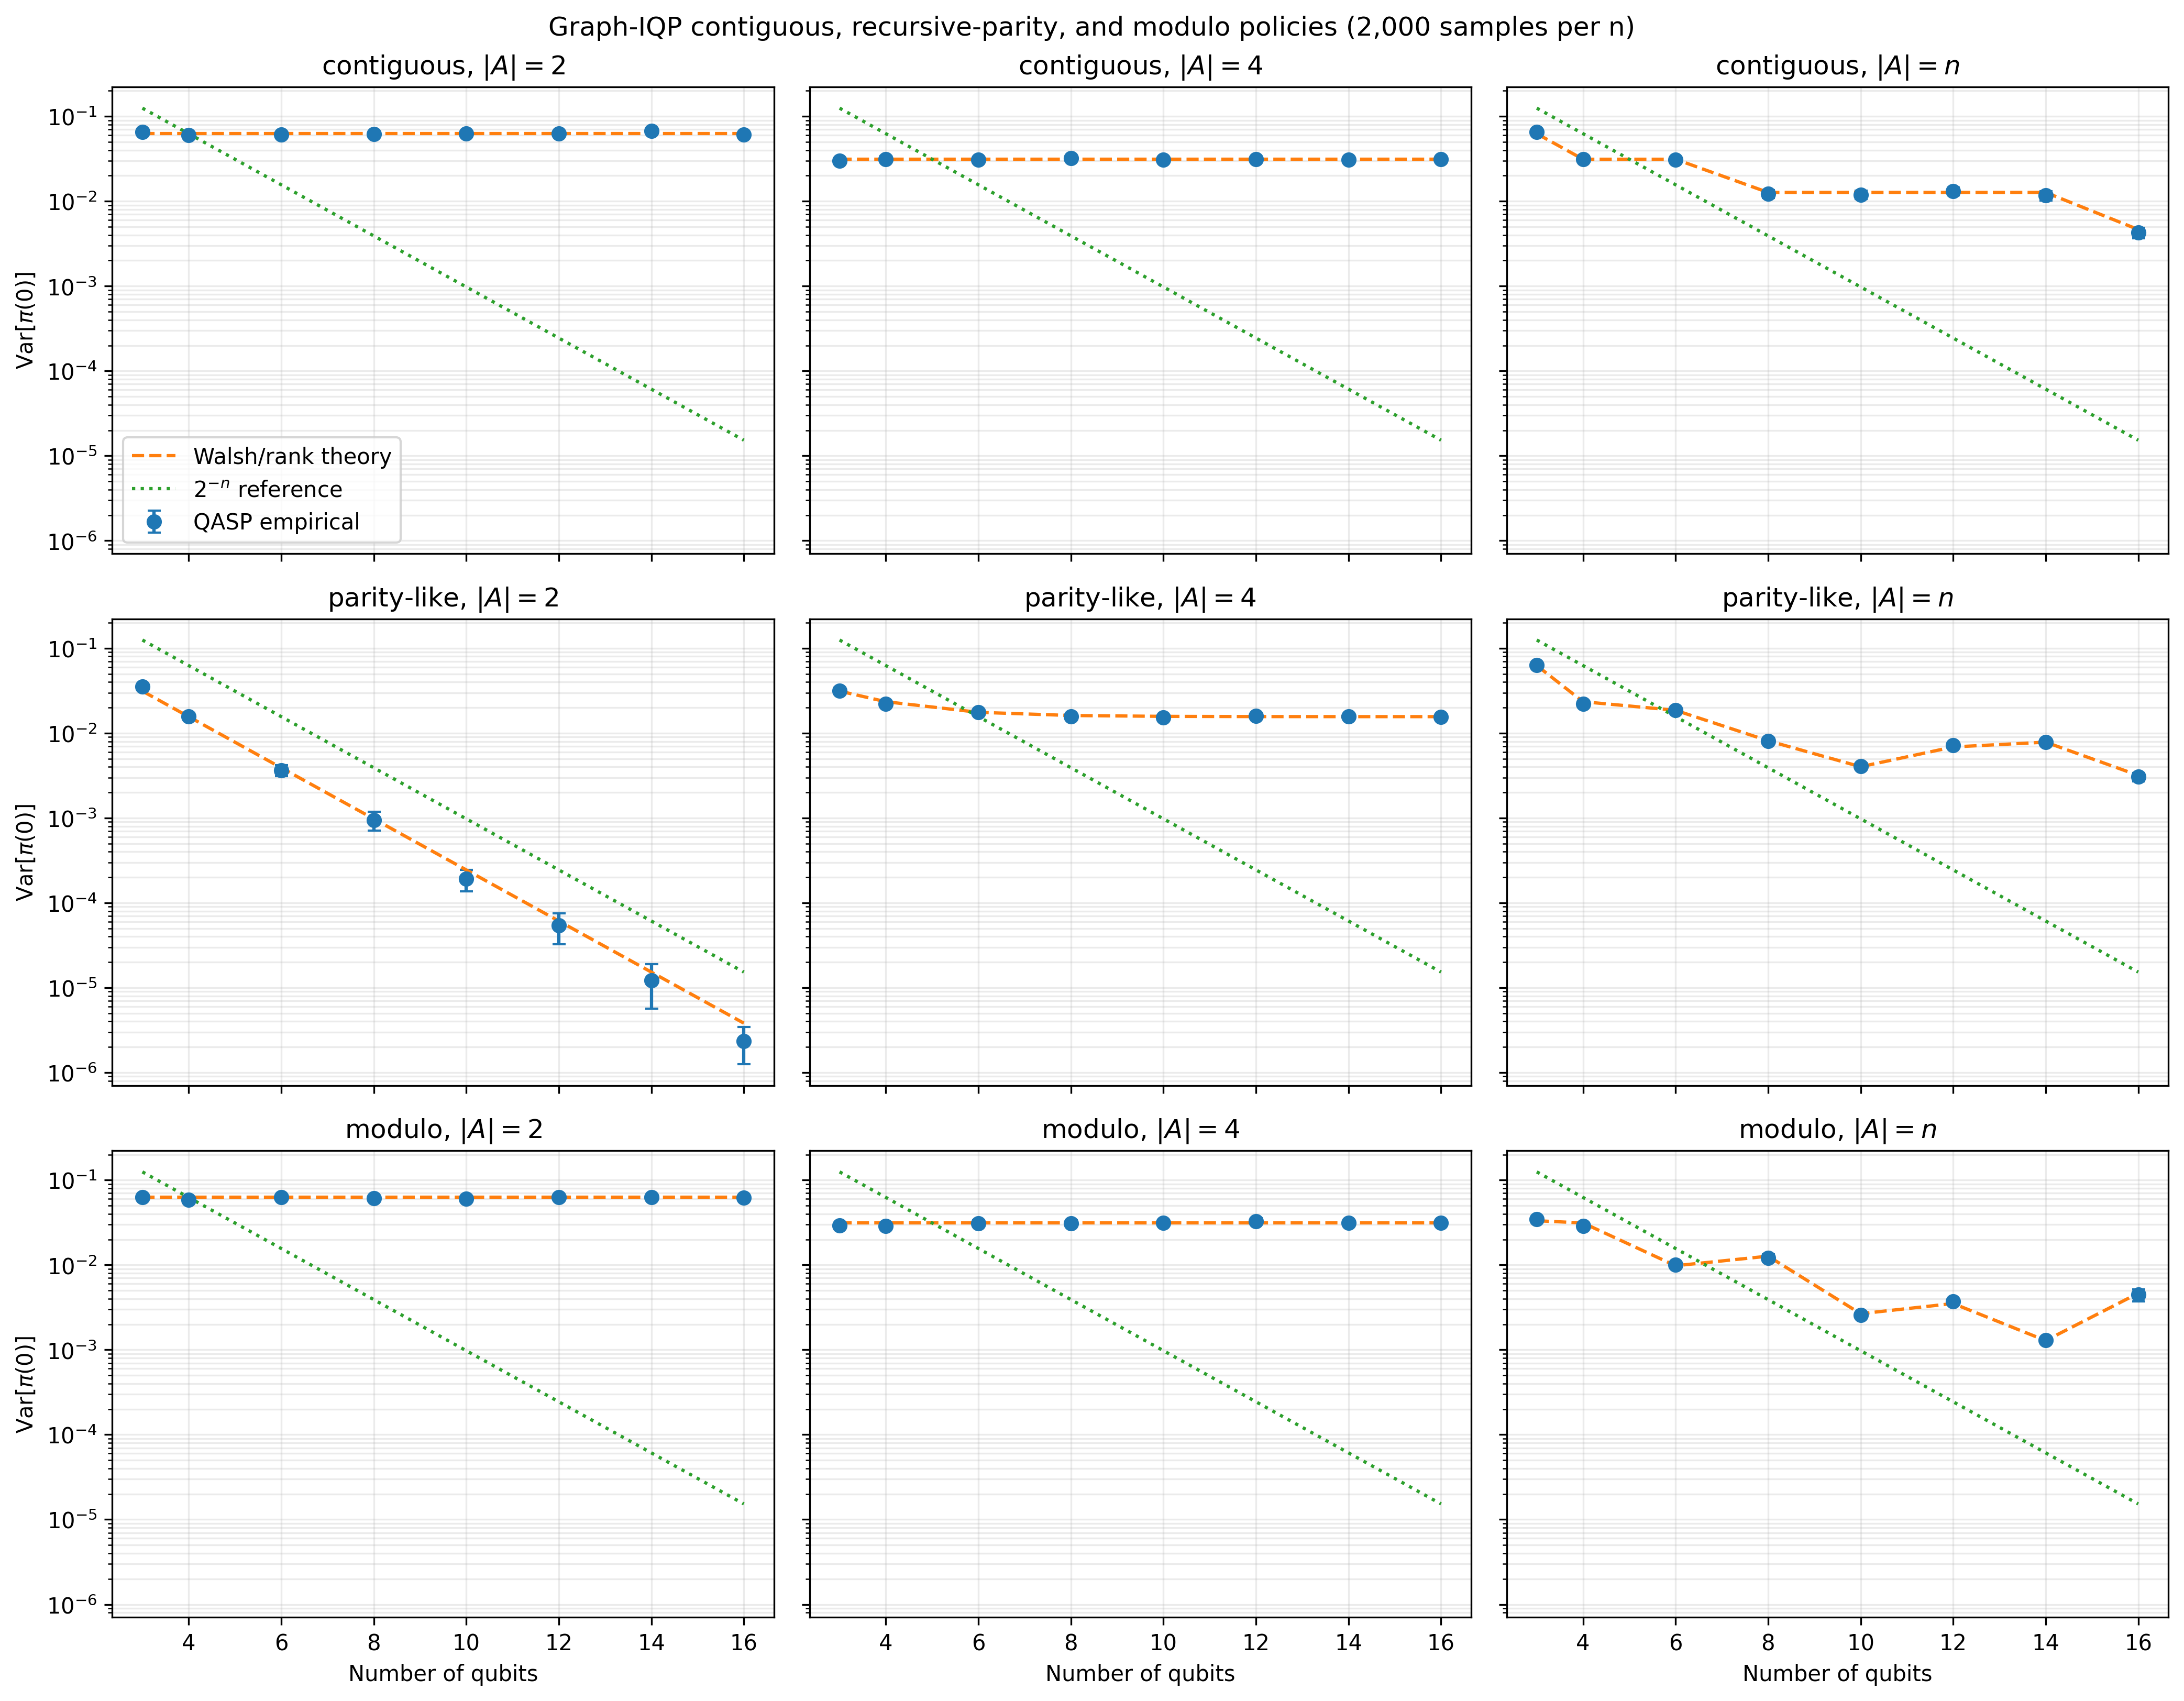

In [42]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex=True, sharey=True, dpi=FIGURE_DPI)
for row_index, policy in enumerate(['contiguous', 'parity-like', 'modulo']):
    for column_index, action_case in enumerate(['2', '4', 'n']):
        ax = axes[row_index, column_index]
        part = policy_df[(policy_df['circuit_family'] == 'graph_iqp') & (policy_df['policy'] == policy) & (policy_df['action_case'] == action_case)]
        ax.errorbar(part['n'], part['empirical_variance'], yerr=2 * part['mc_se'],
                    fmt='o', capsize=3, label='QASP empirical')
        ax.plot(part['n'], part['theory_variance'], '--', label='Walsh/rank theory')
        ax.set_title(f'{policy}, $|A|={action_case}$')
        ax.set_yscale('log')
        #add exponential reference
        n_values = part['n'].to_numpy(dtype=float)
        ax.plot(
            n_values,
            2.0 ** (-n_values),
            ':',
            label=r'$2^{-n}$ reference',
        )
        ax.grid(True, which='both', alpha=0.25)
        if row_index == 2:
            ax.set_xlabel('Number of qubits')
        if column_index == 0:
            ax.set_ylabel(r'$\mathrm{Var}[\pi(0)]$')
axes[0, 0].legend()
fig.suptitle(f'Graph-IQP contiguous, recursive-parity, and modulo policies ({N_SAMPLES:,} samples per n)')
fig.tight_layout()
plt.show()

<a id="policy-pure-rxx"></a>

### Pure RXX policy scaling plots

The same policies and action-set sizes are now evaluated on a periodic $R_{XX}$ **ring**, after removing every local $R_X$ generator. A symmetric-log vertical scale is used because conserved parity sectors can make some variances exactly zero. In particular, for parity-like $|A|=2$, $\Pi_0=(I+Z_0\cdots Z_{n-1})/2$ and all two-qubit $R_{XX}$ rotations conserve $Z_0\cdots Z_{n-1}$, so the theoretical and empirical variances are both exactly zero.

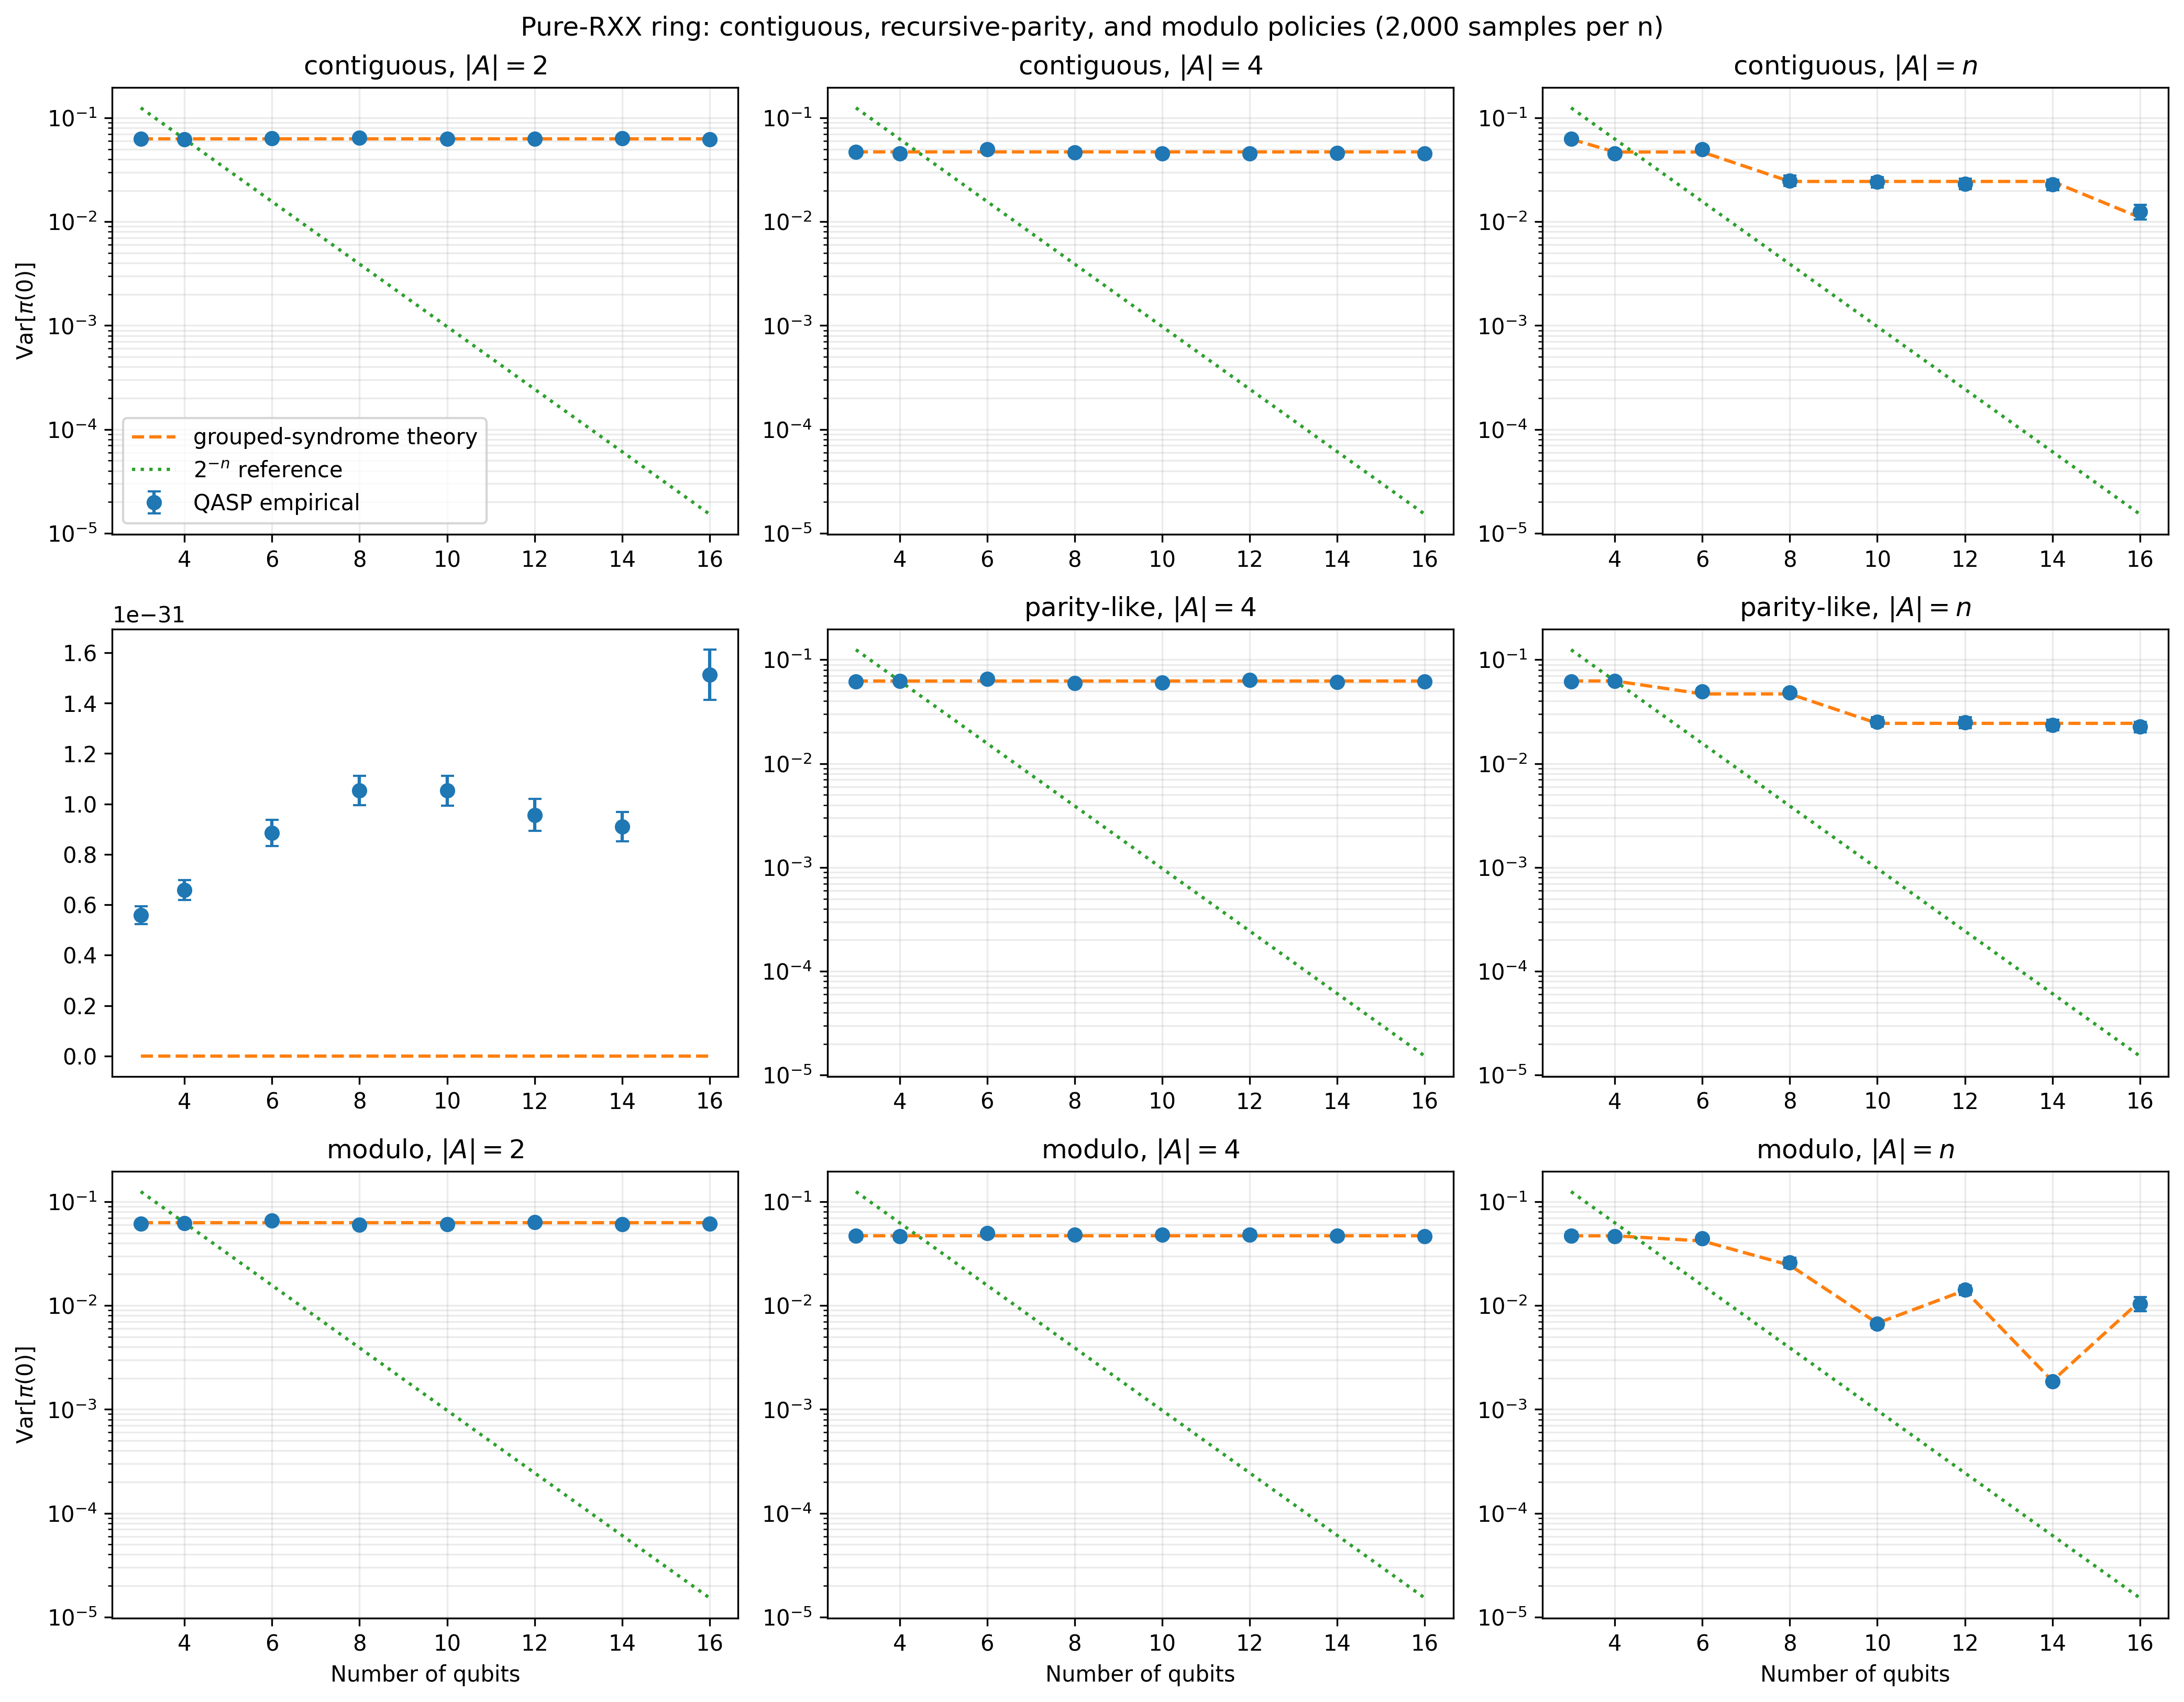

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex=False, sharey=False, dpi=FIGURE_DPI)
for row_index, policy in enumerate(['contiguous', 'parity-like', 'modulo']):
    for column_index, action_case in enumerate(['2', '4', 'n']):
        ax = axes[row_index, column_index]
        part = policy_df[(policy_df['circuit_family'] == 'pure_rxx') & (policy_df['policy'] == policy) & (policy_df['action_case'] == action_case)]
        ax.errorbar(part['n'], part['empirical_variance'], yerr=2 * part['mc_se'],
                    fmt='o', capsize=3, label='QASP empirical')
        ax.plot(part['n'], part['theory_variance'], '--', label='grouped-syndrome theory')
        n_values = part['n'].to_numpy(dtype=float)
        if (action_case == '2' and policy == 'parity-like'):
            continue
        else:
            ax.plot(
                n_values,
                2.0 ** (-n_values),
                ':',
                label=r'$2^{-n}$ reference',
            )
        ax.set_title(f'{policy}, $|A|={action_case}$')
        ax.set_yscale('log')#, linthresh=1e-12, linscale=0.5, base=10)
        ax.axhline(0.0, color='0.55', linewidth=0.7)
        ax.grid(True, which='both', alpha=0.25)
        if row_index == 2:
            ax.set_xlabel('Number of qubits')
        if column_index == 0:
            ax.set_ylabel(r'$\mathrm{Var}[\pi(0)]$')
axes[0, 0].legend()
fig.suptitle(f'Pure-RXX ring: contiguous, recursive-parity, and modulo policies ({N_SAMPLES:,} samples per n)')
fig.tight_layout()
plt.show()

<a id="policy-results"></a>

### Policy comparison checks

The following table compares every empirical policy variance with its exact Walsh/rank prediction and reports the corresponding Monte Carlo diagnostic.

In [54]:
policy_df['within_5_mc_se'] = (
    (policy_df['empirical_variance'] - policy_df['theory_variance']).abs()
    <= np.maximum(5 * policy_df['mc_se'], 1e-12)
)
policy_summary = policy_df[[
    'circuit_label', 'policy', 'action_case', 'n_actions', 'n',
    'bin_fraction', 'n_pauli_terms', 'sample_mean', 'theory_mean', 'mean_error',
    'empirical_variance', 'theory_variance', 'mc_se', 'z_score', 'within_5_mc_se'
]]
display(policy_summary.round(8))
if policy_df['within_5_mc_se'].all():
    print('All policy variances agree with the Walsh/rank prediction within 5 estimated MC standard errors.')
else:
    print('Monte Carlo diagnostic: increase N_SAMPLES for any flagged rows before interpretation.')
    display(policy_df.loc[~policy_df['within_5_mc_se'], ['circuit_label', 'policy', 'action_case', 'n', 'z_score']])

,circuit_label,policy,action_case,n_actions,n,bin_fraction,n_pauli_terms,sample_mean,theory_mean,mean_error,empirical_variance,theory_variance,mc_se,z_score,within_5_mc_se
0,graph IQP (RX + RXX),contiguous,2,2,3,0.5000,1,0.495649,0.5000,-0.004351,0.065017,0.062500,0.001592,1.581185,True
1,graph IQP (RX + RXX),contiguous,4,4,3,0.2500,3,0.240490,0.2500,-0.009510,0.029980,0.031250,0.001181,-1.074887,True
2,graph IQP (RX + RXX),contiguous,n,3,3,0.5000,1,0.495649,0.5000,-0.004351,0.065017,0.062500,0.001592,1.581185,True
3,graph IQP (RX + RXX),parity-like,2,2,3,0.5000,1,0.499637,0.5000,-0.000363,0.035379,0.031250,0.001165,3.544666,True
4,graph IQP (RX + RXX),parity-like,4,4,3,0.2500,3,0.244783,0.2500,-0.005217,0.031666,0.031250,0.001290,0.322557,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,pure RXX,parity-like,4,4,16,0.2500,3,0.508714,0.5000,0.008714,0.128923,0.125000,0.001970,1.991070,True
140,pure RXX,parity-like,n,16,16,0.0625,15,0.126611,0.1250,0.001611,0.038184,0.037109,0.002112,0.508493,True
141,pure RXX,modulo,2,2,16,0.5000,1,0.508714,0.5000,0.008714,0.128923,0.125000,0.001970,1.991070,True
142,pure RXX,modulo,4,4,16,0.2500,3,0.254267,0.2500,0.004267,0.080625,0.078125,0.002445,1.022528,True


All policy variances agree with the Walsh/rank prediction within 5 estimated MC standard errors.


### Repeated IQP experiments <a id="repeated-iqp-experiments"></a>

In [6]:
import qasp 
import torch
import numpy as np

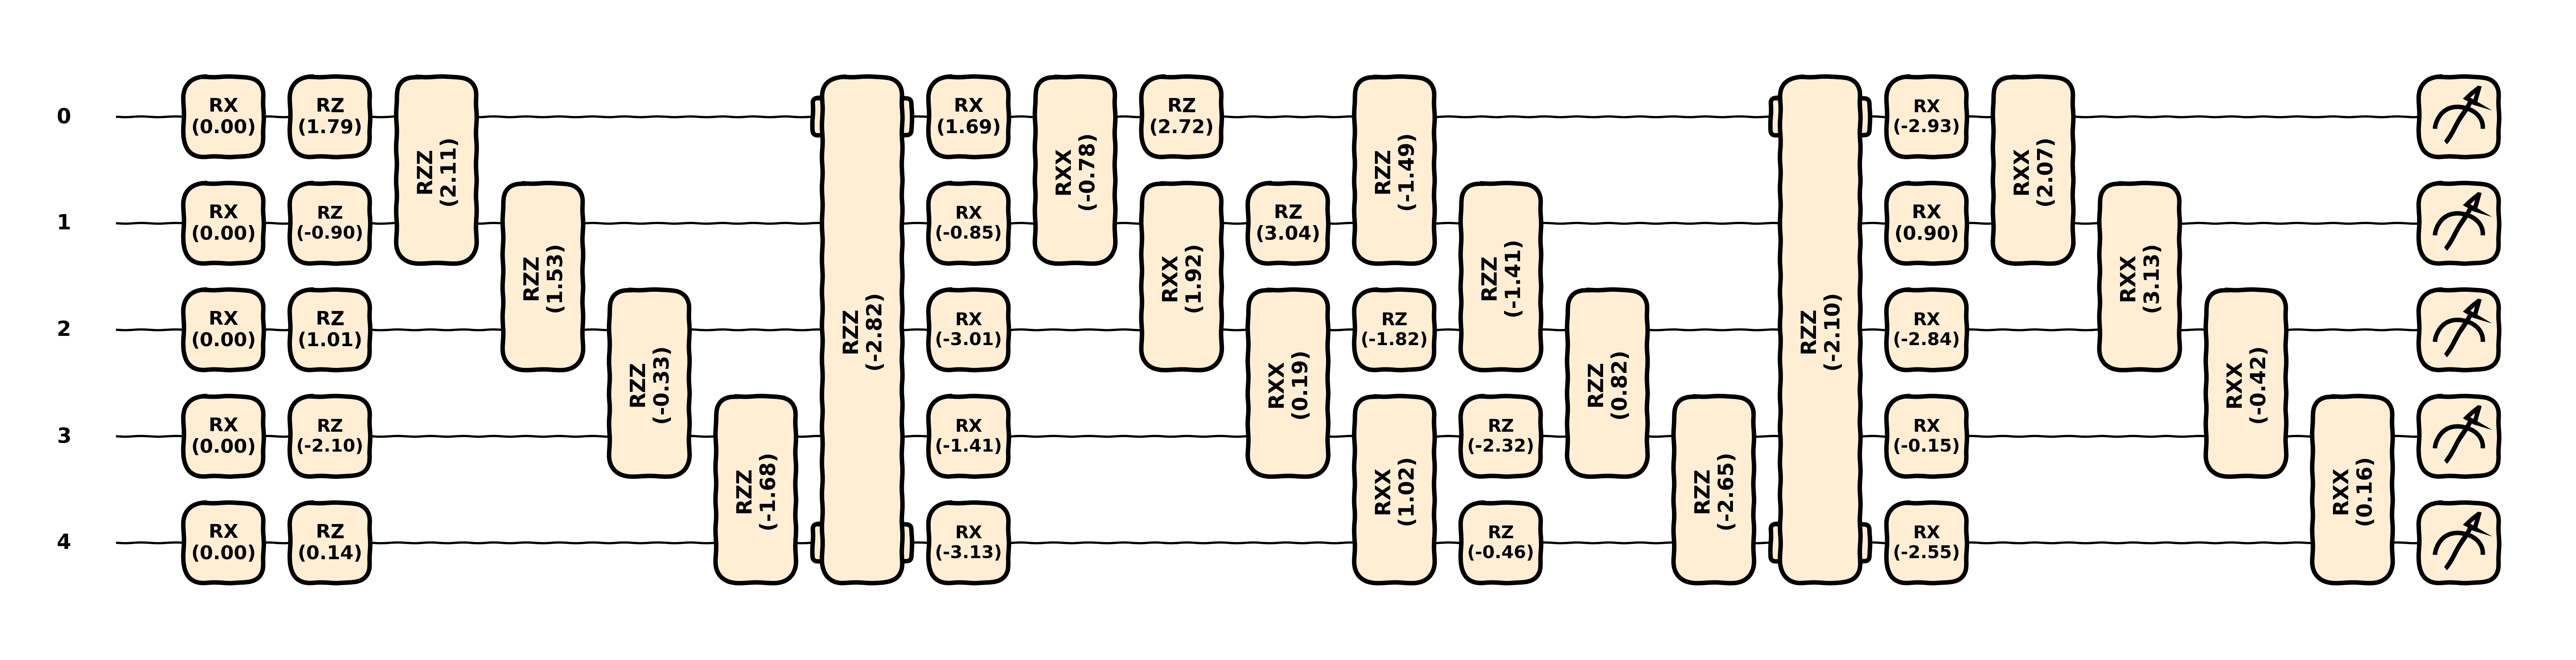

In [9]:
n_qubits=5

fm_config = {
    "features": 1,
    "rotations": "X",
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : ["Z {}".format(i) for i in range(n_qubits)]+["ZZ {} {}".format(i, (i + 1)%n_qubits) for i in range(n_qubits)]+["X {}".format(i) for i in range(n_qubits)]+["XX {} {}".format(i, i + 1) for i in range(n_qubits - 1)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    #"init": "constant",
    #"init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.qubit",
    #"device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,3)],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": False
}


policy = qasp.rl.model.create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
#policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
#print(policy2.qlayer.state_dict()["params"])

fig, ax = qasp.rl.model.draw_model(model=policy,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))

In [62]:
fm_config = {
    "features": 1,
    "rotations": "X",
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : lambda n_qubits: ["Z {}".format(i) for i in range(n_qubits)]+["ZZ {} {}".format(i, i + 1) for i in range(n_qubits - 1)]+["X {}".format(i) for i in range(n_qubits)]+["XX {} {}".format(i, i + 1) for i in range(n_qubits - 1)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    #"init": "constant",
    #"init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.qubit",
    #"device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,3)],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": False
}

variance_qubit = qasp.rl.metrics.policy_variance(policy_class="PQCBorn", 
                            policy_config_kwargs=policy_model_config,
                            n_samples=2000,
                            #action=0,
                            qubit_list=[4,6,8,10,12,14,16],
                            parallel=True)

2026-08-25 17:46:38,121	INFO worker.py:1888 -- Started a local Ray instance.


- Starting sampling for n_qubits: 4
- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8
- Starting sampling for n_qubits: 10
- Starting sampling for n_qubits: 12
- Starting sampling for n_qubits: 14
- Starting sampling for n_qubits: 16


In [65]:
variance_qubit[0]

[np.float64(0.015844722166780536),
 np.float64(0.009428398320996498),
 np.float64(0.008346684151006383),
 np.float64(0.007762202791391186),
 np.float64(0.007957684160875618),
 np.float64(0.007781838003642762),
 np.float64(0.00767290682716232)]

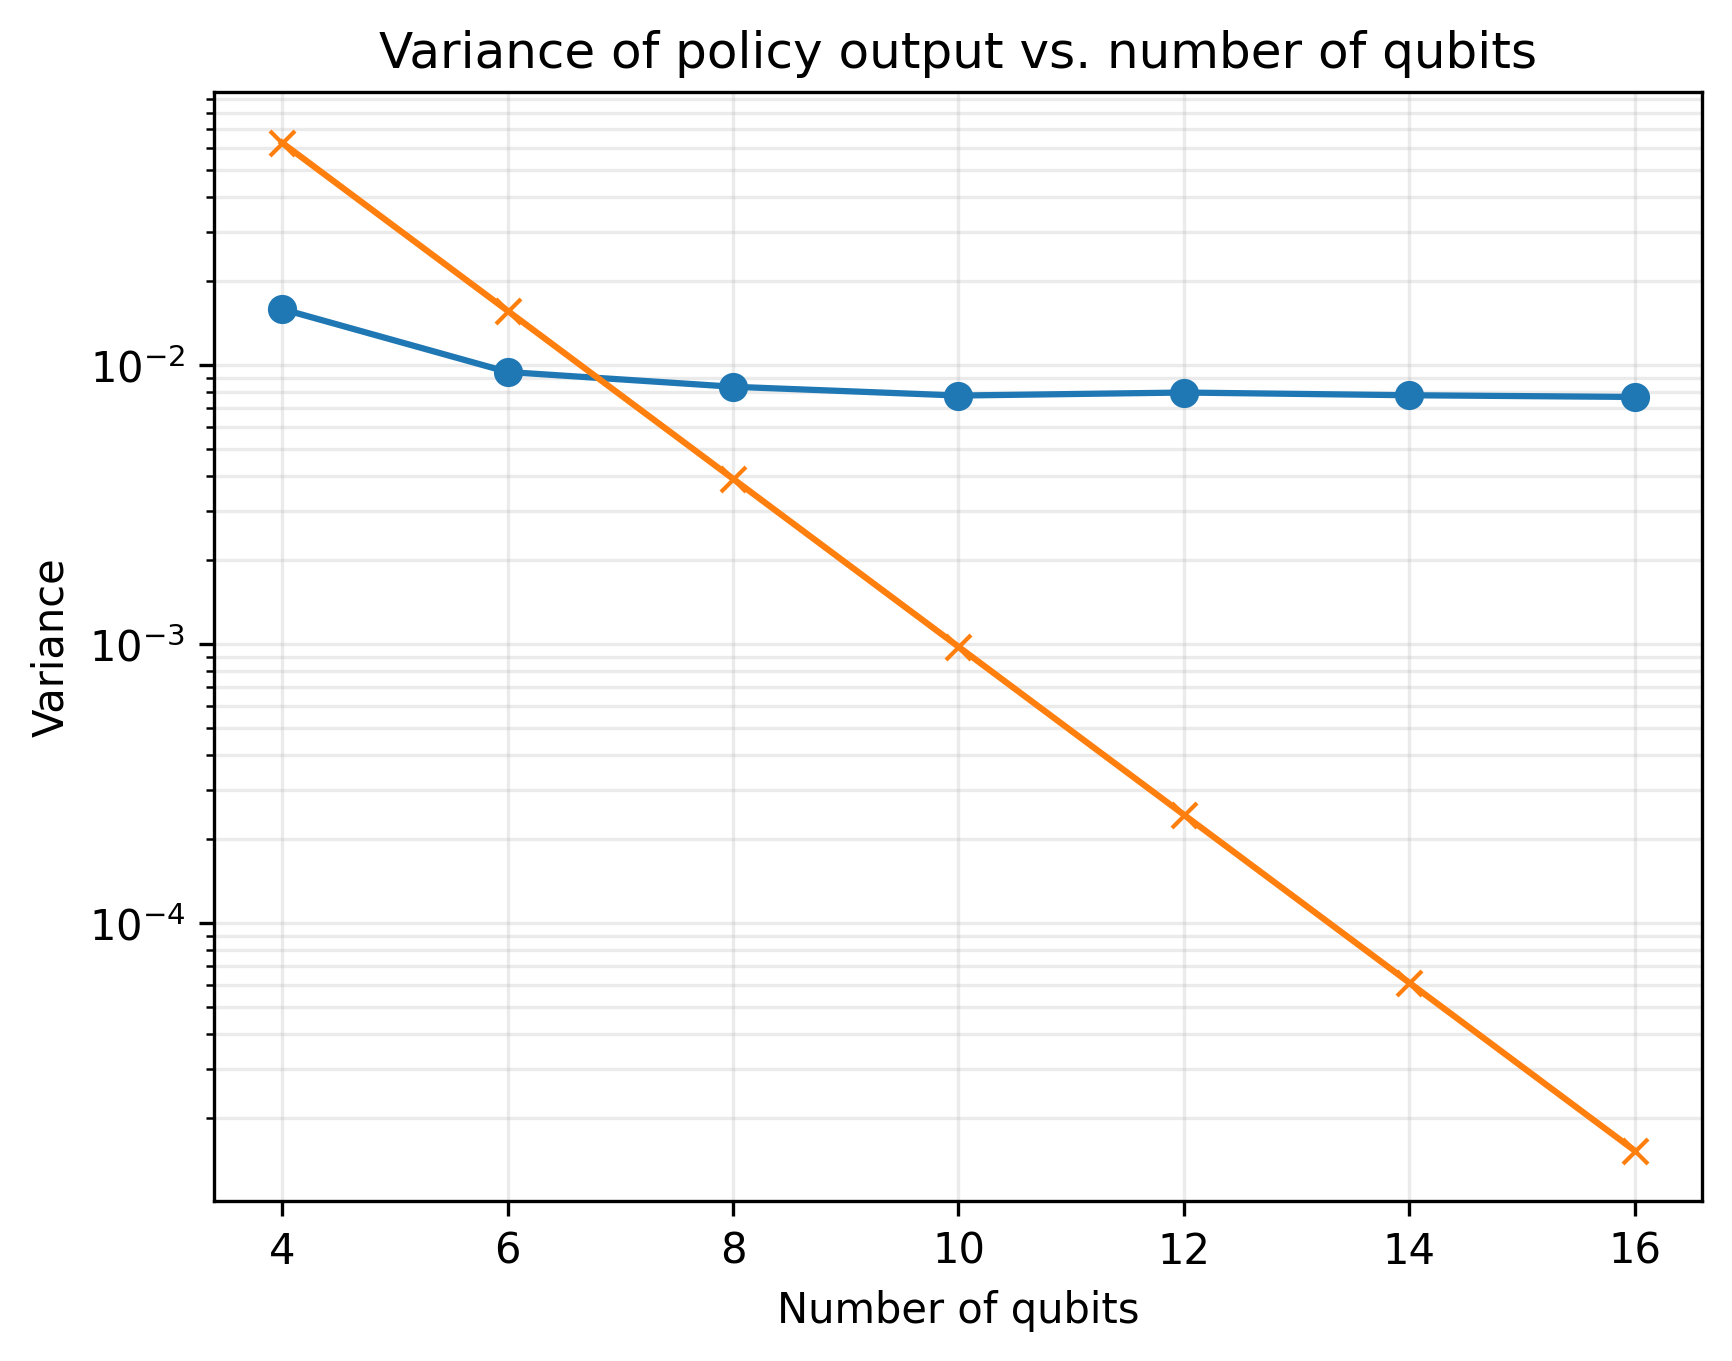

In [66]:
import matplotlib.pyplot as plt
qubit_list=[4,6,8,10,12,14,16]
plt.plot(qubit_list, variance_qubit[0], marker='o')
plt.plot(qubit_list, [2**(-n) for n in qubit_list], marker='x')
plt.xlabel('Number of qubits')
plt.ylabel('Variance')
plt.yscale('log')
plt.title('Variance of policy output vs. number of qubits')
plt.grid(True, which='both', alpha=0.25)    


In [ ]:
import qasp 


In [5]:
n_qubits=5

fm_config = {
    "features": 1,
    "rotations": "X",
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : ["Z {}".format(i) for i in range(n_qubits)]+["ZZ {} {}".format(i, (i + 1)%n_qubits) for i in range(n_qubits)]+["X {}".format(i) for i in range(n_qubits)]+["XX {} {}".format(i, i + 1) for i in range(n_qubits - 1)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    #"init": "constant",
    #"init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.qubit",
    #"device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,3)],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": False
}


policy = qasp.rl.model.create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
#policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
#print(policy2.qlayer.state_dict()["params"])

fig, ax = qasp.rl.model.draw_model(model=policy,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(1))

NameError: name 'torch' is not defined

In [9]:
fm_config = {
    "features": 1,
    "rotations": "X",
}

ansatz_config = {
    "n_layers": lambda n_qubits: int(np.log2(n_qubits)),
    "rotations" : lambda n_qubits: ["Z {}".format(i) for i in range(n_qubits)]+["ZZ {} {}".format(i, i + 1) for i in range(n_qubits - 1)]+["X {}".format(i) for i in range(n_qubits)]+["XX {} {}".format(i, i + 1) for i in range(n_qubits - 1)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    #"init": "constant",
    #"init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    #"device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,3)],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": False
}

variance_qubit = qasp.rl.metrics.policy_variance(policy_class="PQCBorn", 
                            policy_config_kwargs=policy_model_config,
                            n_samples=2000,
                            #action=0,
                            state = torch.zeros(1),
                            qubit_list=[4,6,8,10,12,14,16],
                            parallel=True)

- Starting sampling for n_qubits: 4


- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8
- Starting sampling for n_qubits: 10
- Starting sampling for n_qubits: 12
- Starting sampling for n_qubits: 14
- Starting sampling for n_qubits: 16


In [11]:
variance_qubit[0]

[np.float64(0.016484906017239162),
 np.float64(0.00950524503311576),
 np.float64(0.006163774782443891),
 np.float64(0.005586327053744115),
 np.float64(0.005695927686519287),
 np.float64(0.005461664602328094),
 np.float64(0.003980233173791727)]

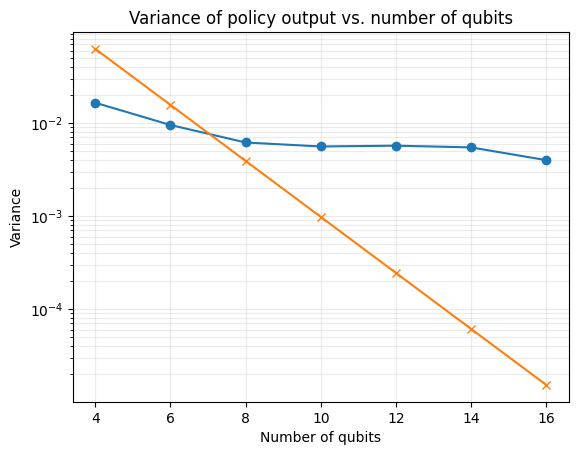

In [12]:
import matplotlib.pyplot as plt
qubit_list=[4,6,8,10,12,14,16]
plt.plot(qubit_list, variance_qubit[0], marker='o')
plt.plot(qubit_list, [2**(-n) for n in qubit_list], marker='x')
plt.xlabel('Number of qubits')
plt.ylabel('Variance')
plt.yscale('log')
plt.title('Variance of policy output vs. number of qubits')
plt.grid(True, which='both', alpha=0.25)    


## Experiment 7 — majority–modulo policies <a id="majority-modulo-experiments"></a>

We now test the newly derived majority–modulo policy.

For an action space of size

$$
A=|\mathcal A|,
$$

define

$$
k=\lceil \log_2 A\rceil,
\qquad
C=2^k.
$$

The measured qubits are partitioned into $k$ approximately equal contiguous blocks

$$
V_1,\ldots,V_k.
$$

Each block produces one majority bit

$$
m_r(x)=
\begin{cases}
0,&\text{if block }r\text{ contains at least as many zeros as ones},\\
1,&\text{if block }r\text{ contains strictly more ones than zeros}.
\end{cases}
$$

Thus ties, which can occur for even block sizes, are assigned to majority bit $0$, consistently with the deterministic even-majority convention used in the theory.

The majority bits define

$$
m(x)=m_1(x)\cdots m_k(x),
$$

which is interpreted as an integer

$$
J(m)=\operatorname{int}(m_1\cdots m_k).
$$

The final action is

$$
\boxed{
b_A(x)=J(m(x))\bmod A.
}
$$

For $A=2^k$, this reduces exactly to the ordinary majority-code policy.

For non-power-of-two $A$, some actions have two majority-code preimages. If the two codes differ on the block set $D$, the corresponding action projector is

$$
\boxed{
\Pi_a
=
\frac{2}{C}
\sum_{\substack{
T\subseteq[k]\\
|T\cap D|\ {\rm even}
}}
(-1)^{T\cdot y}
\mathcal M_T.
}
$$

Hence unchanged majority bits survive through linear terms $\mathcal M_r$, while changed majority bits survive through at least quadratic products $\mathcal M_r\mathcal M_s$.

For a graph-IQP circuit with all local $R_X$ generators,

$$
\operatorname{Var}[\pi(a)]
=
\sum_{S\neq\emptyset}
c_{a,S}^2
2^{-\Delta_G(S)}.
$$

The notebook computes this prediction exactly from the Walsh transform of the full majority–modulo indicator, rather than using only the asymptotic lower bound.

We additionally inspect the one- and two-local sectors, which are responsible for the trainability bound

$$
\operatorname{Var}
\left[
\partial_{\theta_j}\pi(a)
\right]
=
\Omega
\left(
\frac{\log A}{A^2n}
\right)
$$

for bounded-degree graph-IQP circuits.

In [6]:
def balanced_contiguous_blocks(n, k):
    """
    Partition qubits 0,...,n-1 into k nonempty contiguous blocks whose
    sizes differ by at most one.

    Example:
        n=10, k=3 -> [(0,1,2,3), (4,5,6), (7,8,9)]
    """
    if not (1 <= k <= n):
        raise ValueError(f'Need 1 <= k <= n, got k={k}, n={n}.')

    base, remainder = divmod(n, k)
    sizes = [base + (r < remainder) for r in range(k)]

    blocks = []
    start = 0
    for size in sizes:
        blocks.append(tuple(range(start, start + size)))
        start += size

    assert sum(len(block) for block in blocks) == n
    assert set(q for block in blocks for q in block) == set(range(n))
    return blocks


def majority_bit(bits):
    """
    Majority bit used in the book theory.

    0 -> zeros are at least as numerous as ones.
    1 -> strictly more ones than zeros.

    Therefore ties for even block size are assigned to majority bit 0.
    """
    bits = np.asarray(bits, dtype=np.uint8)
    return int(bits.sum() > len(bits) / 2)


def majority_code_from_bits(bits, blocks):
    """Return the majority-bit tuple and its binary integer label."""
    majority_bits = tuple(majority_bit(bits[list(block)]) for block in blocks)

    raw_label = 0
    for bit in majority_bits:
        raw_label = (raw_label << 1) | bit

    return majority_bits, raw_label


def majority_modulo_action_map(n, n_actions, return_codes=False):
    """
    Majority-modulo policy

        a(x) = int(m_1(x)...m_k(x)) mod |A|,

    where k = ceil(log2 |A|) and each m_r is the majority bit of one
    balanced contiguous qubit block.
    """
    if not (2 <= n_actions <= 2**n):
        raise ValueError('Need 2 <= |A| <= 2**n.')

    k = int(np.ceil(np.log2(n_actions)))
    if k > n:
        raise ValueError(
            f'Majority-modulo needs at least k={k} qubits for |A|={n_actions}.'
        )

    blocks = balanced_contiguous_blocks(n, k)

    actions = np.empty(2**n, dtype=int)
    raw_codes = np.empty(2**n, dtype=int)

    for state in range(2**n):
        # Consistent with the existing notebook convention:
        # qubit 0 is the left-most / most-significant computational-basis bit.
        bits = np.array(list(np.binary_repr(state, width=n)), dtype=np.uint8)

        _, raw_label = majority_code_from_bits(bits, blocks)

        raw_codes[state] = raw_label
        actions[state] = raw_label % n_actions

    if return_codes:
        return actions, raw_codes, blocks

    return actions


# Small sanity check: A=5 requires k=3 majority bits.
mm_actions_5, mm_codes_5, mm_blocks_5 = majority_modulo_action_map(
    n=9, n_actions=5, return_codes=True
)

print('A=5 majority-modulo example')
print('blocks:', mm_blocks_5)
print('unique raw majority codes:', np.unique(mm_codes_5))
print('unique final actions:', np.unique(mm_actions_5))

assert len(mm_blocks_5) == 3
assert set(np.unique(mm_actions_5)) == set(range(5))

A=5 majority-modulo example
blocks: [(0, 1, 2), (3, 4, 5), (6, 7, 8)]
unique raw majority codes: [0 1 2 3 4 5 6 7]
unique final actions: [0 1 2 3 4]


In [7]:
def majority_modulo_code_preimages(n_actions):
    """
    Return the k-bit majority-code preimages of every final modulo action.
    """
    k = int(np.ceil(np.log2(n_actions)))
    C = 2**k

    preimages = {}
    for raw in range(C):
        action = raw % n_actions
        code = tuple(int(bit) for bit in np.binary_repr(raw, width=k))
        preimages.setdefault(action, []).append((raw, code))

    return preimages


def code_difference_set(code_a, code_b):
    """Indices of majority bits on which two binary codes differ."""
    return tuple(
        r for r, (x, y) in enumerate(zip(code_a, code_b))
        if x != y
    )


for A in [3, 5, 6, 7]:
    print(f'\n|A| = {A}')
    preimages = majority_modulo_code_preimages(A)

    rows = []
    for action, codes in preimages.items():
        row = {
            'action': action,
            'raw_labels': [raw for raw, _ in codes],
            'majority_codes': [''.join(map(str, code)) for _, code in codes],
            'n_preimages': len(codes),
        }

        if len(codes) == 2:
            D = code_difference_set(codes[0][1], codes[1][1])
            row['D'] = D
            row['Hamming_distance'] = len(D)

            # Non-power-of-two collisions must differ in at least two bits.
            assert len(D) >= 2
        else:
            row['D'] = ()
            row['Hamming_distance'] = 0

        rows.append(row)

    display(pd.DataFrame(rows))


|A| = 3


,action,raw_labels,majority_codes,n_preimages,D,Hamming_distance
0,0,"[0, 3]","[00, 11]",2,"(0, 1)",2
1,1,[1],[01],1,(),0
2,2,[2],[10],1,(),0



|A| = 5


,action,raw_labels,majority_codes,n_preimages,D,Hamming_distance
0,0,"[0, 5]","[000, 101]",2,"(0, 2)",2
1,1,"[1, 6]","[001, 110]",2,"(0, 1, 2)",3
2,2,"[2, 7]","[010, 111]",2,"(0, 2)",2
3,3,[3],[011],1,(),0
4,4,[4],[100],1,(),0



|A| = 6


,action,raw_labels,majority_codes,n_preimages,D,Hamming_distance
0,0,"[0, 6]","[000, 110]",2,"(0, 1)",2
1,1,"[1, 7]","[001, 111]",2,"(0, 1)",2
2,2,[2],[010],1,(),0
3,3,[3],[011],1,(),0
4,4,[4],[100],1,(),0
5,5,[5],[101],1,(),0



|A| = 7


,action,raw_labels,majority_codes,n_preimages,D,Hamming_distance
0,0,"[0, 7]","[000, 111]",2,"(0, 1, 2)",3
1,1,[1],[001],1,(),0
2,2,[2],[010],1,(),0
3,3,[3],[011],1,(),0
4,4,[4],[100],1,(),0
5,5,[5],[101],1,(),0
6,6,[6],[110],1,(),0


In [8]:
def majority_modulo_rank_prediction(
    n,
    edges,
    n_actions,
    action=0,
    include_local=True,
    collect_spectrum=True,
):
    """
    Exact variance prediction for the majority-modulo policy.

    For graph-IQP chain circuits with all local RX generators:
        Var[pi(a)] = sum_{S != empty} c_S^2 2^{-Delta_G(S)}.

    For pure-RXX circuits, coefficients sharing a generator syndrome
    are grouped first exactly as in policy_rank_prediction().
    """
    action_map = majority_modulo_action_map(n, n_actions)
    diagonal = (action_map == action).astype(float)

    coeffs = fwht_coefficients(diagonal)

    variance = 0.0
    spectrum = []
    n_spectrum_terms = int(np.count_nonzero(np.abs(coeffs[1:]) >= 1e-12))

    is_chain = list(edges) == chain_edges(n)

    if include_local and is_chain:
        theory_mean = float(coeffs[0])

        for mask, coefficient in enumerate(coeffs):
            if mask == 0 or abs(coefficient) < 1e-12:
                continue

            delta = chain_closed_neighborhood_size(mask, n)
            rank = delta

            contribution = coefficient**2 * 2.0**(-rank)
            variance += contribution

            if collect_spectrum:
                support = integer_support(mask, n)
                spectrum.append({
                    'support': support,
                    'weight': len(support),
                    'coefficient': coefficient,
                    'coefficient_sq': coefficient**2,
                    'rank': rank,
                    'delta': delta,
                    'contribution': contribution,
                })

    else:
        # Same symmetry-sector correction used by the existing
        # pure-RXX policy experiments.
        generator_masks = generator_integer_masks(n, edges, include_local)

        grouped_coefficients = {}
        grouped_members = {}

        for mask, coefficient in enumerate(coeffs):
            if abs(coefficient) < 1e-12:
                continue

            syndrome = generator_syndrome(mask, generator_masks)
            grouped_coefficients[syndrome] = (
                grouped_coefficients.get(syndrome, 0.0) + coefficient
            )

            if collect_spectrum:
                grouped_members.setdefault(syndrome, []).append(
                    integer_support(mask, n)
                )

        theory_mean = float(grouped_coefficients.get(0, 0.0))
        generators, _ = generator_supports(n, edges, include_local)

        for syndrome, combined_coefficient in grouped_coefficients.items():
            if syndrome == 0 or abs(combined_coefficient) < 1e-12:
                continue

            if not include_local and is_chain:
                rank = int(syndrome.bit_count())
                delta = chain_edge_sector_delta(syndrome, n)

            else:
                active = [
                    generators[index]
                    for index in range(len(generators))
                    if (syndrome >> index) & 1
                ]

                G_y = (
                    np.column_stack(active)
                    if active
                    else np.zeros((n, 0), dtype=np.uint8)
                )

                rank = gf2_rank(G_y)
                delta = light_cone_size(G_y)

            contribution = (
                combined_coefficient**2
                * 2.0**(-rank)
            )

            variance += contribution

            if collect_spectrum:
                spectrum.append({
                    'syndrome': syndrome,
                    'member_supports': grouped_members[syndrome],
                    'combined_coefficient': combined_coefficient,
                    'rank': rank,
                    'delta': delta,
                    'contribution': contribution,
                })

    # Parseval check for the diagonal action projector.
    assert np.isclose(
        np.sum(coeffs**2),
        diagonal.mean(),
        atol=1e-10,
    )

    spectrum_result = (
        pd.DataFrame(spectrum)
        if collect_spectrum
        else n_spectrum_terms
    )

    return (
        variance,
        spectrum_result,
        diagonal,
        coeffs,
        theory_mean,
    )

In [14]:
# Inspect the exact majority-modulo Walsh spectrum for A=5.

MM_EXAMPLE_N = 9
MM_EXAMPLE_A = 5

preimages = majority_modulo_code_preimages(MM_EXAMPLE_A)

for action in range(MM_EXAMPLE_A):
    theory, spectrum, diagonal, coeffs, theory_mean = (
        majority_modulo_rank_prediction(
            n=MM_EXAMPLE_N,
            edges=chain_edges(MM_EXAMPLE_N),
            n_actions=MM_EXAMPLE_A,
            action=action,
            include_local=True,
            collect_spectrum=True,
        )
    )

    codes = preimages[action]

    print('\n' + '=' * 70)
    print(f'n={MM_EXAMPLE_N}, |A|={MM_EXAMPLE_A}, action={action}')
    print(
        'majority-code preimages:',
        [''.join(map(str, code)) for _, code in codes]
    )

    if len(codes) == 2:
        D = code_difference_set(codes[0][1], codes[1][1])
        print(f'collision difference set D={D}, |D|={len(D)}')
    else:
        print('single-preimage action')

    print(f'action-bin fraction = {diagonal.mean():.8f}')
    print(f'exact initialization mean = {theory_mean:.8f}')
    print(f'exact theory variance = {theory:.10f}')
    print(
        f'nonzero nonidentity Walsh terms = '
        f'{np.count_nonzero(np.abs(coeffs[1:]) > 1e-12)}'
    )

    if not spectrum.empty:
        weight_summary = (
            spectrum
            .groupby('weight')
            .agg(
                n_terms=('support', 'count'),
                squared_fourier_weight=('coefficient_sq', 'sum'),
                variance_contribution=('contribution', 'sum'),
                max_abs_coefficient=('coefficient', lambda x: np.max(np.abs(x))),
            )
            .reset_index()
        )

        print('\nFourier/Pauli spectrum grouped by Pauli weight:')
        display(weight_summary.round(10))

        print('\nOne- and two-local terms:')
        display(
            spectrum[
                spectrum['weight'].isin([1, 2])
            ]
            .sort_values(['weight', 'support'])
            .round(10)
        )


n=9, |A|=5, action=0
majority-code preimages: ['000', '101']
collision difference set D=(0, 2), |D|=2
action-bin fraction = 0.25000000
exact initialization mean = 0.25000000
exact theory variance = 0.0078716278
nonzero nonidentity Walsh terms = 84

Fourier/Pauli spectrum grouped by Pauli weight:


,weight,n_terms,squared_fourier_weight,variance_contribution,max_abs_coefficient
0,1,3,0.046875,0.005859,0.12500
1,2,9,0.035156,0.000977,0.06250
2,3,28,0.041992,0.000658,0.12500
3,4,6,0.023438,0.000244,0.06250
4,5,27,0.026367,0.000095,0.03125
5,6,1,0.003906,0.000015,0.06250
6,7,9,0.008789,0.000021,0.03125
7,9,1,0.000977,0.000002,0.03125



One- and two-local terms:


,support,weight,coefficient,coefficient_sq,rank,delta,contribution
2,"(3,)",1,0.1250,0.015625,3,3,0.001953
1,"(4,)",1,0.1250,0.015625,3,3,0.001953
0,"(5,)",1,0.1250,0.015625,3,3,0.001953
46,"(0, 6)",2,0.0625,0.003906,5,5,0.000122
45,"(0, 7)",2,0.0625,0.003906,5,5,0.000122
44,"(0, 8)",2,0.0625,0.003906,4,4,0.000244
26,"(1, 6)",2,0.0625,0.003906,6,6,0.000061
25,"(1, 7)",2,0.0625,0.003906,6,6,0.000061
24,"(1, 8)",2,0.0625,0.003906,5,5,0.000122
6,"(2, 6)",2,0.0625,0.003906,6,6,0.000061



n=9, |A|=5, action=1
majority-code preimages: ['001', '110']
collision difference set D=(0, 1, 2), |D|=3
action-bin fraction = 0.25000000
exact initialization mean = 0.25000000
exact theory variance = 0.0040435791
nonzero nonidentity Walsh terms = 48

Fourier/Pauli spectrum grouped by Pauli weight:


,weight,n_terms,squared_fourier_weight,variance_contribution,max_abs_coefficient
0,2,27,0.105469,0.003052,0.0625
1,4,18,0.070312,0.000916,0.0625
2,6,3,0.011719,0.000076,0.0625


... (10 outputs left out)


n=9, |A|=5, action=4
majority-code preimages: ['100']
single-preimage action
action-bin fraction = 0.12500000
exact initialization mean = 0.12500000
exact theory variance = 0.0070643425
nonzero nonidentity Walsh terms = 124

Fourier/Pauli spectrum grouped by Pauli weight:


,weight,n_terms,squared_fourier_weight,variance_contribution,max_abs_coefficient
0,1,9,0.035156,5.371094e-03,0.062500
1,2,27,0.026367,7.629395e-04,0.031250
2,3,30,0.018311,6.527901e-04,0.062500
3,4,18,0.017578,2.288818e-04,0.031250
4,5,27,0.006592,2.384190e-05,0.015625
5,6,3,0.002930,1.907350e-05,0.031250
6,7,9,0.002197,5.245200e-06,0.015625
7,9,1,0.000244,4.768000e-07,0.015625



One- and two-local terms:


,support,weight,coefficient,coefficient_sq,rank,delta,contribution
74,"(0,)",1,-0.06250,0.003906,2,2,0.000977
49,"(1,)",1,-0.06250,0.003906,3,3,0.000488
24,"(2,)",1,-0.06250,0.003906,3,3,0.000488
14,"(3,)",1,0.06250,0.003906,3,3,0.000488
9,"(4,)",1,0.06250,0.003906,3,3,0.000488
4,"(5,)",1,0.06250,0.003906,3,3,0.000488
2,"(6,)",1,0.06250,0.003906,3,3,0.000488
1,"(7,)",1,0.06250,0.003906,3,3,0.000488
0,"(8,)",1,0.06250,0.003906,2,2,0.000977
89,"(0, 3)",2,-0.03125,0.000977,5,5,0.000031


In [15]:
# Structural verification of the A=5 theory.

n = MM_EXAMPLE_N
A = 5
blocks = balanced_contiguous_blocks(n, int(np.ceil(np.log2(A))))
preimages = majority_modulo_code_preimages(A)

structure_rows = []

for action in range(A):
    theory, spectrum, diagonal, coeffs, theory_mean = (
        majority_modulo_rank_prediction(
            n=n,
            edges=chain_edges(n),
            n_actions=A,
            action=action,
            include_local=True,
            collect_spectrum=True,
        )
    )

    codes = preimages[action]

    singleton_supports = {
        row.support
        for row in spectrum.itertuples()
        if row.weight == 1
    }

    pair_supports = {
        row.support
        for row in spectrum.itertuples()
        if row.weight == 2
    }

    if len(codes) == 2:
        D = code_difference_set(codes[0][1], codes[1][1])
    else:
        D = ()

    block_singleton_present = []

    for block_index, block in enumerate(blocks):
        present = all(
            (q,) in singleton_supports
            for q in block
        )
        block_singleton_present.append(present)

    structure_rows.append({
        'action': action,
        'codes': [
            ''.join(map(str, code))
            for _, code in codes
        ],
        'D': D,
        'singleton_blocks_present': block_singleton_present,
        'n_singletons': len(singleton_supports),
        'n_two_local_terms': len(pair_supports),
        'theory_variance': theory,
    })

structure_df = pd.DataFrame(structure_rows)
display(structure_df)

# Check the theoretical rule:
# - unchanged collided blocks retain singleton terms;
# - changed collided blocks lose singleton terms.
for row in structure_rows:
    action = row['action']
    codes = preimages[action]

    if len(codes) != 2:
        continue

    D = set(row['D'])

    for r, singleton_present in enumerate(row['singleton_blocks_present']):
        if r in D:
            assert not singleton_present
        else:
            assert singleton_present

print(
    'Verified: for every collided A=5 action, '
    'singleton majority terms survive exactly on unchanged majority blocks.'
)

,action,codes,D,singleton_blocks_present,n_singletons,n_two_local_terms,theory_variance
0,0,"[000, 101]","(0, 2)","[False, True, False]",3,9,0.007872
1,1,"[001, 110]","(0, 1, 2)","[False, False, False]",0,27,0.004044
2,2,"[010, 111]","(0, 2)","[False, True, False]",3,9,0.007872
3,3,[011],(),"[True, True, True]",9,27,0.007064
4,4,[100],(),"[True, True, True]",9,27,0.007064


Verified: for every collided A=5 action, singleton majority terms survive exactly on unchanged majority blocks.


In [16]:
def run_majority_modulo_experiments_for_n(
    n,
    n_samples,
    seed,
    action_specs,
    circuit_family='graph_iqp',
):
    """
    QASP Monte Carlo experiment for majority-modulo policies.

    action_specs:
        iterable of tuples
            (label, n_actions, action)

    Example:
        [
            ('A=3,a=0', 3, 0),
            ('A=5,a=0', 5, 0),
            ('A=5,a=1', 5, 1),
        ]
    """
    if circuit_family not in {'graph_iqp', 'pure_rxx'}:
        raise ValueError(
            "circuit_family must be 'graph_iqp' or 'pure_rxx'"
        )

    include_local = circuit_family == 'graph_iqp'

    circuit_label = (
        'graph IQP (RX + RXX)'
        if include_local
        else 'pure RXX'
    )

    edges = chain_edges(n)

    specifications = []

    for label, n_actions, action in action_specs:
        k = int(np.ceil(np.log2(n_actions)))

        if k > n:
            continue

        action_map = majority_modulo_action_map(
            n,
            n_actions,
        )

        action_mask = (
            action_map == action
        ).astype(float)

        (
            theory,
            n_pauli_terms,
            _,
            _,
            theory_mean,
        ) = majority_modulo_rank_prediction(
            n=n,
            edges=edges,
            n_actions=n_actions,
            action=action,
            include_local=include_local,
            collect_spectrum=False,
        )

        preimages = majority_modulo_code_preimages(n_actions)[action]

        if len(preimages) == 2:
            D = code_difference_set(
                preimages[0][1],
                preimages[1][1],
            )
        else:
            D = ()

        specifications.append({
            'label': label,
            'n_actions': n_actions,
            'action': action,
            'mask': action_mask,
            'theory': theory,
            'theory_mean': theory_mean,
            'n_pauli_terms': n_pauli_terms,
            'bin_fraction': action_mask.mean(),
            'n_preimages': len(preimages),
            'collision_hamming_distance': len(D),
            'k_majority_bits': k,
            'blocks': balanced_contiguous_blocks(n, k),
        })

    qnode, n_parameters = build_qasp_iqp_probs(
        n,
        edges,
        include_local=include_local,
    )

    rng = np.random.default_rng(seed)

    parameters = rng.uniform(
        -np.pi,
        np.pi,
        size=(n_samples, n_parameters),
    )

    samples = np.empty(
        (
            n_samples,
            len(specifications),
        )
    )

    for sample_index, theta in enumerate(parameters):
        basis_probabilities = np.asarray(
            qnode(params=theta),
            dtype=float,
        )

        for spec_index, spec in enumerate(specifications):
            samples[sample_index, spec_index] = (
                basis_probabilities
                @ spec['mask']
            )

    rows = []

    for spec_index, spec in enumerate(specifications):
        empirical, mc_se = variance_and_mc_se(
            samples[:, spec_index]
        )

        sample_mean = samples[:, spec_index].mean()

        rows.append({
            'circuit_family': circuit_family,
            'circuit_label': circuit_label,
            'policy': 'majority-modulo',
            'case': spec['label'],
            'n_actions': spec['n_actions'],
            'action': spec['action'],
            'n': n,
            'k_majority_bits': spec['k_majority_bits'],
            'block_sizes': tuple(
                len(block)
                for block in spec['blocks']
            ),
            'n_preimages': spec['n_preimages'],
            'collision_hamming_distance':
                spec['collision_hamming_distance'],
            'bin_fraction': spec['bin_fraction'],
            'n_pauli_terms': spec['n_pauli_terms'],
            'empirical_variance': empirical,
            'mc_se': mc_se,
            'theory_variance': spec['theory'],
            'sample_mean': sample_mean,
            'theory_mean': spec['theory_mean'],
            'mean_error':
                sample_mean
                - spec['theory_mean'],
            'z_score':
                (
                    empirical
                    - spec['theory']
                )
                / mc_se
                if mc_se > 0
                else np.nan,
        })

    return rows

In [17]:
MAJMOD_N_VALUES = [6, 8, 10, 12, 14, 16]

MAJMOD_ACTION_SPECS = [
    ('A=2, a=0', 2, 0),
    ('A=3, a=0', 3, 0),
    ('A=4, a=0', 4, 0),
    ('A=5, a=0', 5, 0),
    ('A=5, a=1', 5, 1),
]

start = time.perf_counter()

majority_modulo_rows = []

for index, n in enumerate(MAJMOD_N_VALUES):
    specs = list(MAJMOD_ACTION_SPECS)

    # Polynomially growing action space A=n.
    specs.append((f'A=n={n}, a=0', n, 0))

    print(
        f'graph IQP majority-modulo: n={n}, '
        f'{len(specs)} action cases'
    )

    majority_modulo_rows.extend(
        run_majority_modulo_experiments_for_n(
            n=n,
            n_samples=N_SAMPLES,
            seed=SEED + 6000 + index,
            action_specs=specs,
            circuit_family='graph_iqp',
        )
    )

majority_modulo_df = pd.DataFrame(
    majority_modulo_rows
)

display(
    majority_modulo_df.round(9)
)

print(
    f'Elapsed: '
    f'{time.perf_counter() - start:.1f} s'
)

graph IQP majority-modulo: n=6, 6 action cases
graph IQP majority-modulo: n=8, 6 action cases
graph IQP majority-modulo: n=10, 6 action cases
graph IQP majority-modulo: n=12, 6 action cases
graph IQP majority-modulo: n=14, 6 action cases
graph IQP majority-modulo: n=16, 6 action cases


,circuit_family,circuit_label,policy,case,n_actions,action,n,k_majority_bits,block_sizes,n_preimages,collision_hamming_distance,bin_fraction,n_pauli_terms,empirical_variance,mc_se,theory_variance,sample_mean,theory_mean,mean_error,z_score
0,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=2, a=0",2,0,6,1,"(6,)",1,0,0.656250,63,0.026516,0.000834,0.026474,0.660915,0.656250,0.004665,0.050905
1,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=3, a=0",3,0,6,2,"(3, 3)",2,2,0.500000,16,0.007605,0.000333,0.007324,0.500006,0.500000,0.000006,0.843448
2,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=4, a=0",4,0,6,2,"(3, 3)",1,0,0.250000,24,0.019823,0.000695,0.019409,0.252947,0.250000,0.002947,0.596012
3,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=5, a=0",5,0,6,3,"(2, 2, 2)",2,2,0.468750,63,0.019785,0.000637,0.019760,0.476199,0.468750,0.007449,0.038832
4,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=5, a=1",5,1,6,3,"(2, 2, 2)",2,3,0.187500,30,0.011320,0.000498,0.011719,0.182040,0.187500,-0.005460,-0.799982
5,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=n=6, a=0",6,0,6,3,"(2, 2, 2)",2,2,0.468750,63,0.023677,0.000730,0.023666,0.475378,0.468750,0.006628,0.014541
6,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=2, a=0",2,0,8,1,"(8,)",1,0,0.636719,255,0.024056,0.000728,0.024438,0.640181,0.636719,0.003462,-0.525722
7,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=3, a=0",3,0,8,2,"(4, 4)",2,2,0.570312,255,0.010365,0.000365,0.010346,0.572286,0.570312,0.001974,0.052106
8,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=4, a=0",4,0,8,2,"(4, 4)",1,0,0.472656,255,0.024025,0.000692,0.024590,0.476025,0.472656,0.003368,-0.816323
9,graph_iqp,graph IQP (RX + RXX),majority-modulo,"A=5, a=0",5,0,8,3,"(3, 3, 2)",2,2,0.250000,84,0.010239,0.000367,0.010300,0.250037,0.250000,0.000037,-0.165123


Elapsed: 111.6 s


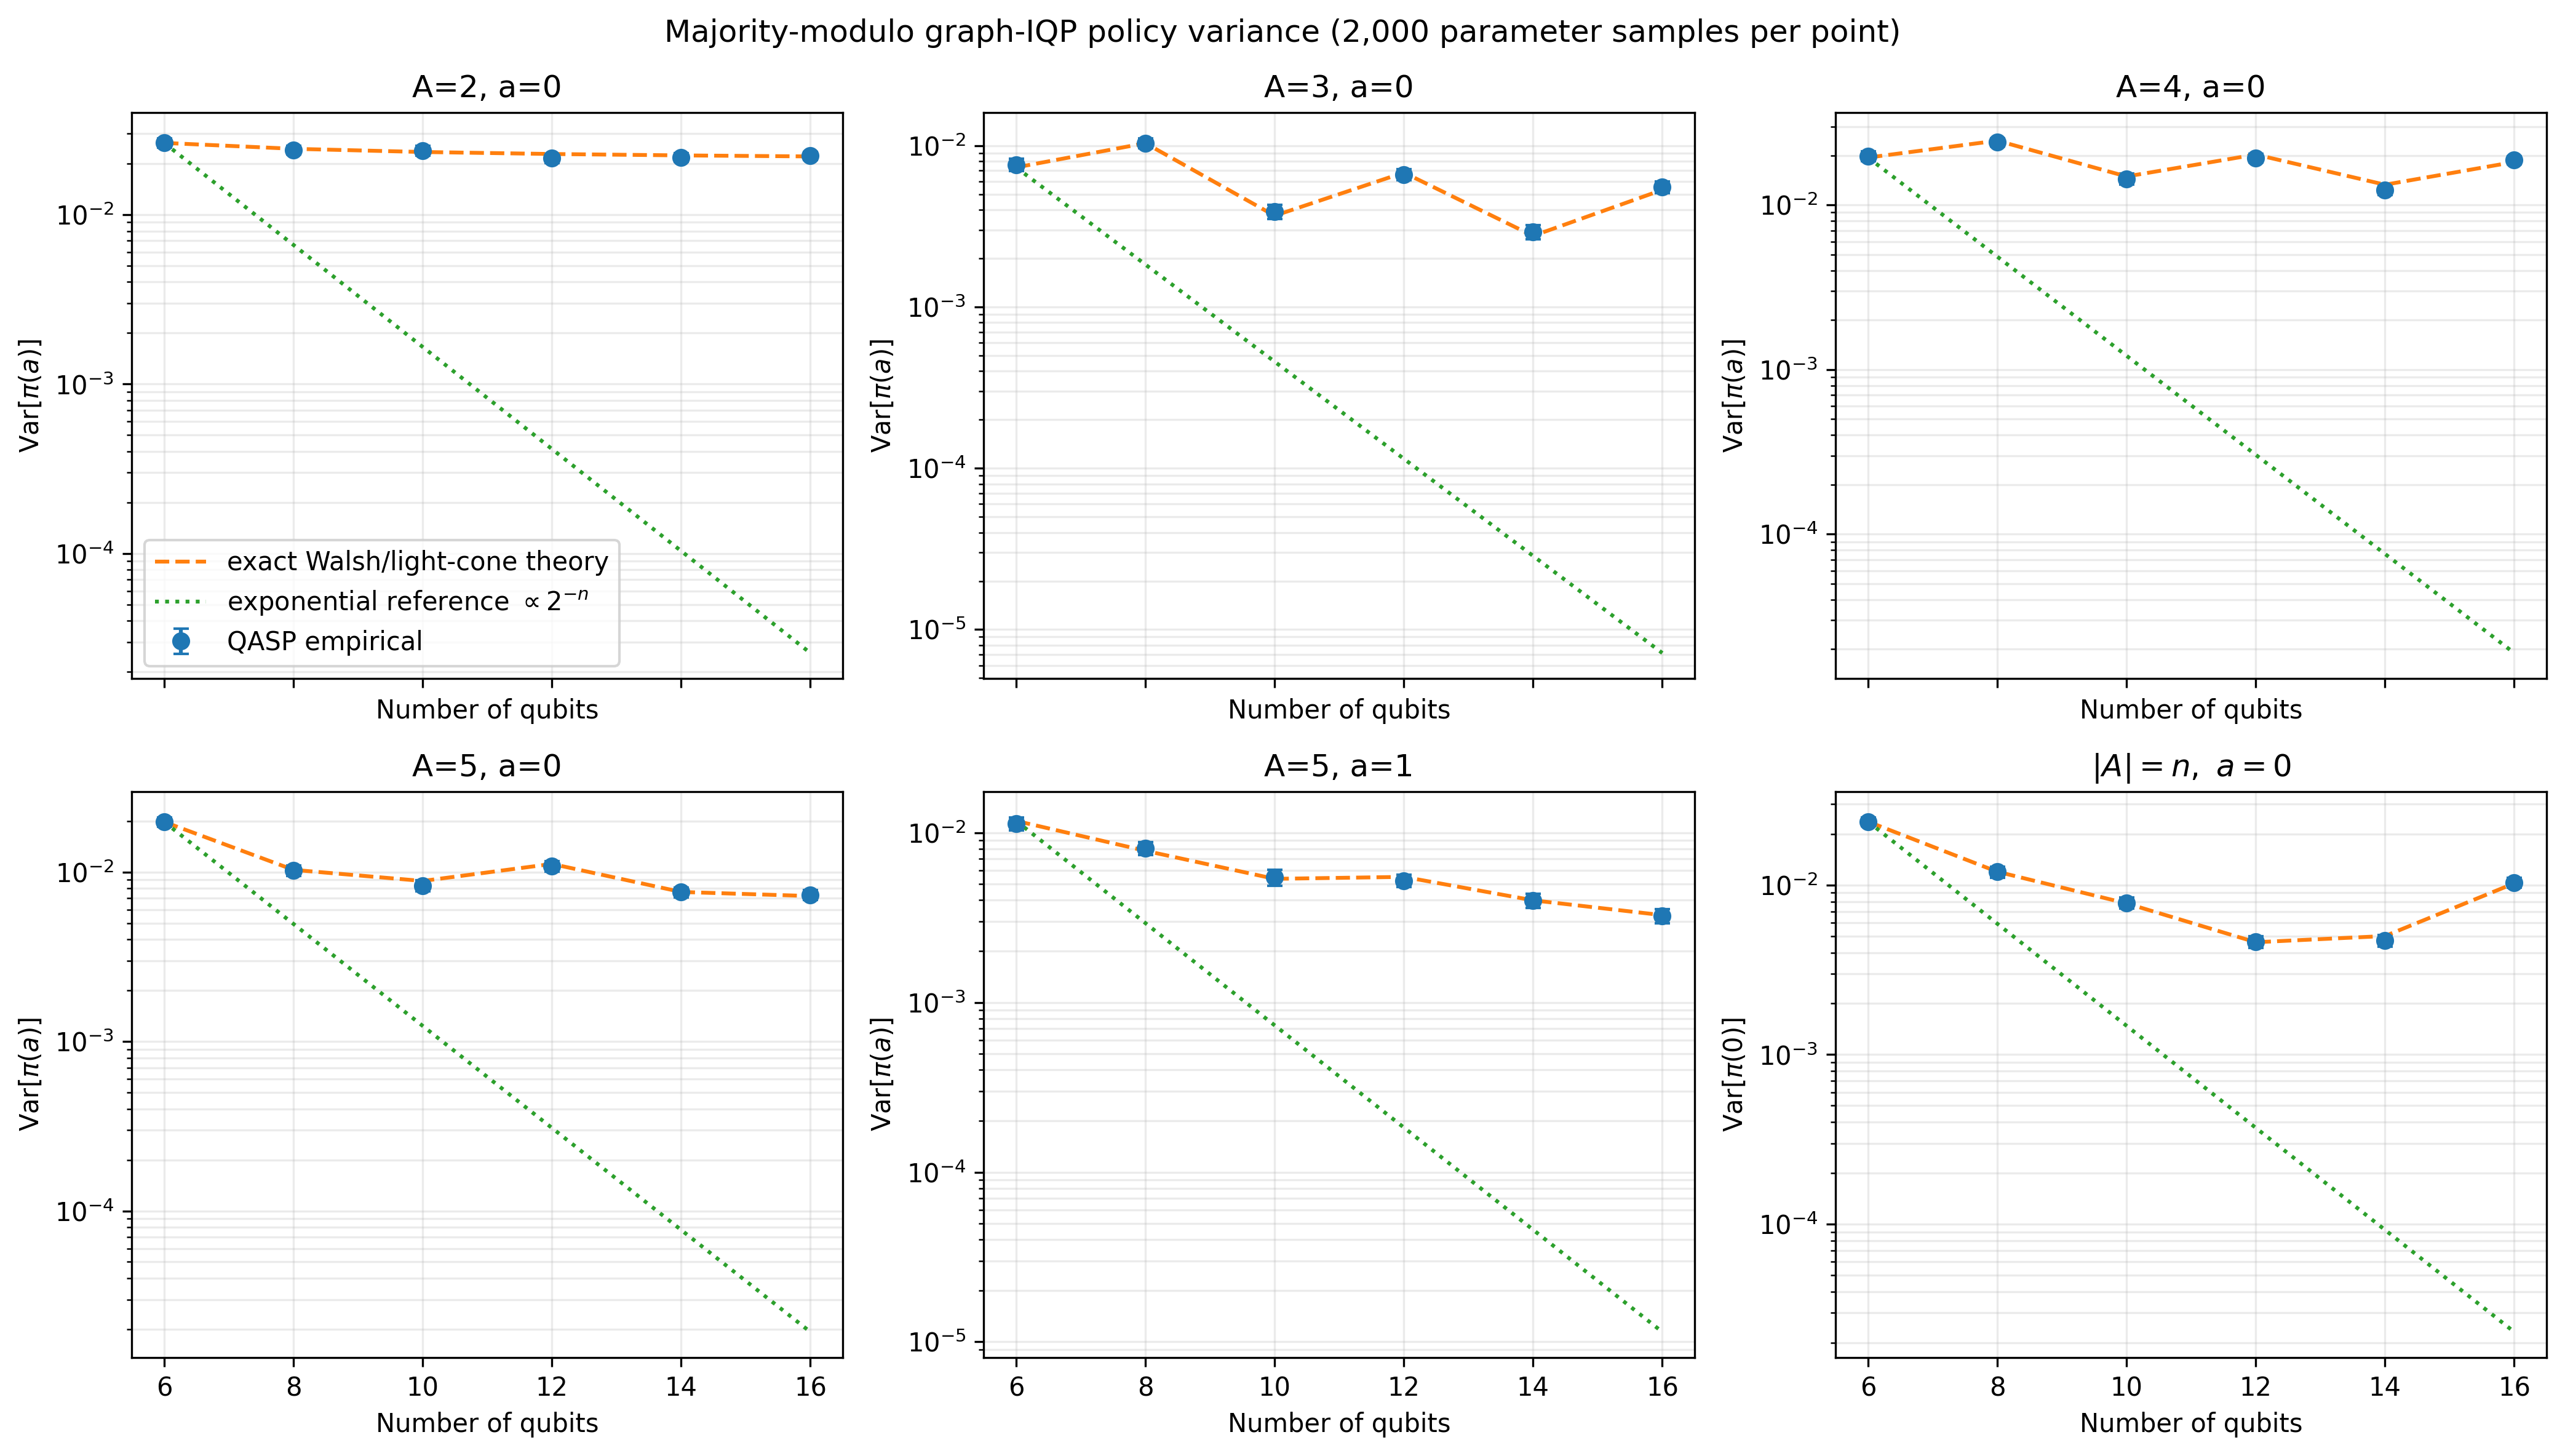

In [21]:
plot_cases = [
    'A=2, a=0',
    'A=3, a=0',
    'A=4, a=0',
    'A=5, a=0',
    'A=5, a=1',
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(14, 8),
    sharex=True,
    dpi=FIGURE_DPI,
)

axes = axes.ravel()

for ax, case in zip(axes, plot_cases):
    part = majority_modulo_df[
        majority_modulo_df['case'] == case
    ].sort_values('n')

    ax.errorbar(
        part['n'],
        part['empirical_variance'],
        yerr=2 * part['mc_se'],
        fmt='o',
        capsize=3,
        label='QASP empirical',
    )

    ax.plot(
        part['n'],
        part['theory_variance'],
        '--',
        label='exact Walsh/light-cone theory',
    )

    # ------------------------------------------------------------
    # Exponential-decay reference
    # ------------------------------------------------------------
    # Use 2^{-n}, normalized to the first theory point so that the
    # exponential slope is visually comparable with the policy curve.
    n_values = part['n'].to_numpy()
    theory_values = part['theory_variance'].to_numpy()

    exp_reference = 2.0 ** (-n_values)

    if len(theory_values) > 0 and theory_values[0] > 0:
        exp_reference *= (
            theory_values[0] / exp_reference[0]
        )

    ax.plot(
        n_values,
        exp_reference,
        ':',
        linewidth=1.5,
        label=r'exponential reference $\propto 2^{-n}$',
    )

    ax.set_title(case)
    ax.set_yscale('log')
    ax.grid(True, which='both', alpha=0.25)
    ax.set_xlabel('Number of qubits')
    ax.set_ylabel(r'$\mathrm{Var}[\pi(a)]$')


# ============================================================
# A=n in the final panel
# ============================================================

ax = axes[-1]

part = majority_modulo_df[
    majority_modulo_df['case'].str.startswith('A=n=')
].sort_values('n')

ax.errorbar(
    part['n'],
    part['empirical_variance'],
    yerr=2 * part['mc_se'],
    fmt='o',
    capsize=3,
    label='QASP empirical',
)

ax.plot(
    part['n'],
    part['theory_variance'],
    '--',
    label='exact Walsh/light-cone theory',
)

# ------------------------------------------------------------
# Exponential-decay reference
# ------------------------------------------------------------
n_values = part['n'].to_numpy()
theory_values = part['theory_variance'].to_numpy()

exp_reference = 2.0 ** (-n_values)

if len(theory_values) > 0 and theory_values[0] > 0:
    exp_reference *= (
        theory_values[0] / exp_reference[0]
    )

ax.plot(
    n_values,
    exp_reference,
    ':',
    linewidth=1.5,
    label=r'exponential reference $\propto 2^{-n}$',
)

ax.set_title(r'$|A|=n,\ a=0$')
ax.set_yscale('log')
ax.grid(True, which='both', alpha=0.25)
ax.set_xlabel('Number of qubits')
ax.set_ylabel(r'$\mathrm{Var}[\pi(0)]$')


# ============================================================
# Legend / title
# ============================================================

axes[0].legend()

fig.suptitle(
    f'Majority-modulo graph-IQP policy variance '
    f'({N_SAMPLES:,} parameter samples per point)'
)

fig.tight_layout()
plt.show()

In [22]:
majority_modulo_df['within_5_mc_se'] = (
    (
        majority_modulo_df['empirical_variance']
        -
        majority_modulo_df['theory_variance']
    ).abs()
    <=
    np.maximum(
        5 * majority_modulo_df['mc_se'],
        1e-12,
    )
)

majmod_summary_columns = [
    'case',
    'n',
    'n_actions',
    'action',
    'k_majority_bits',
    'block_sizes',
    'n_preimages',
    'collision_hamming_distance',
    'bin_fraction',
    'n_pauli_terms',
    'sample_mean',
    'theory_mean',
    'mean_error',
    'empirical_variance',
    'theory_variance',
    'mc_se',
    'z_score',
    'within_5_mc_se',
]

display(
    majority_modulo_df[
        majmod_summary_columns
    ].round(9)
)

if majority_modulo_df['within_5_mc_se'].all():
    print(
        'All majority-modulo policy variances agree with '
        'the exact Walsh/light-cone prediction within '
        '5 estimated Monte Carlo standard errors.'
    )
else:
    print(
        'Some points are outside the 5-SE Monte Carlo band. '
        'Increase N_SAMPLES before drawing conclusions.'
    )

    display(
        majority_modulo_df.loc[
            ~majority_modulo_df['within_5_mc_se'],
            [
                'case',
                'n',
                'empirical_variance',
                'theory_variance',
                'mc_se',
                'z_score',
            ],
        ]
    )

,case,n,n_actions,action,k_majority_bits,block_sizes,n_preimages,collision_hamming_distance,bin_fraction,n_pauli_terms,sample_mean,theory_mean,mean_error,empirical_variance,theory_variance,mc_se,z_score,within_5_mc_se
0,"A=2, a=0",6,2,0,1,"(6,)",1,0,0.656250,63,0.660915,0.656250,0.004665,0.026516,0.026474,0.000834,0.050905,True
1,"A=3, a=0",6,3,0,2,"(3, 3)",2,2,0.500000,16,0.500006,0.500000,0.000006,0.007605,0.007324,0.000333,0.843448,True
2,"A=4, a=0",6,4,0,2,"(3, 3)",1,0,0.250000,24,0.252947,0.250000,0.002947,0.019823,0.019409,0.000695,0.596012,True
3,"A=5, a=0",6,5,0,3,"(2, 2, 2)",2,2,0.468750,63,0.476199,0.468750,0.007449,0.019785,0.019760,0.000637,0.038832,True
4,"A=5, a=1",6,5,1,3,"(2, 2, 2)",2,3,0.187500,30,0.182040,0.187500,-0.005460,0.011320,0.011719,0.000498,-0.799982,True
5,"A=n=6, a=0",6,6,0,3,"(2, 2, 2)",2,2,0.468750,63,0.475378,0.468750,0.006628,0.023677,0.023666,0.000730,0.014541,True
6,"A=2, a=0",8,2,0,1,"(8,)",1,0,0.636719,255,0.640181,0.636719,0.003462,0.024056,0.024438,0.000728,-0.525722,True
7,"A=3, a=0",8,3,0,2,"(4, 4)",2,2,0.570312,255,0.572286,0.570312,0.001974,0.010365,0.010346,0.000365,0.052106,True
8,"A=4, a=0",8,4,0,2,"(4, 4)",1,0,0.472656,255,0.476025,0.472656,0.003368,0.024025,0.024590,0.000692,-0.816323,True
9,"A=5, a=0",8,5,0,3,"(3, 3, 2)",2,2,0.250000,84,0.250037,0.250000,0.000037,0.010239,0.010300,0.000367,-0.165123,True


All majority-modulo policy variances agree with the exact Walsh/light-cone prediction within 5 estimated Monte Carlo standard errors.


In [23]:
def majority_modulo_weight_sector_prediction(
    n,
    n_actions,
    action,
    max_weight=None,
):
    """
    Exact graph-IQP variance contribution grouped by Pauli weight.
    Uses the complete Walsh spectrum of the action projector.
    """
    theory, spectrum, diagonal, coeffs, theory_mean = (
        majority_modulo_rank_prediction(
            n=n,
            edges=chain_edges(n),
            n_actions=n_actions,
            action=action,
            include_local=True,
            collect_spectrum=True,
        )
    )

    grouped = (
        spectrum
        .groupby('weight')
        .agg(
            n_terms=('support', 'count'),
            fourier_weight=('coefficient_sq', 'sum'),
            variance_contribution=('contribution', 'sum'),
            max_abs_coefficient=(
                'coefficient',
                lambda x: np.max(np.abs(x)),
            ),
        )
        .reset_index()
    )

    if max_weight is not None:
        grouped = grouped[
            grouped['weight'] <= max_weight
        ]

    return theory, grouped


sector_rows = []

for n in MAJMOD_N_VALUES:
    for action in [0, 1]:
        A = 5

        total_theory, grouped = (
            majority_modulo_weight_sector_prediction(
                n=n,
                n_actions=A,
                action=action,
            )
        )

        by_weight = {
            int(row.weight): row.variance_contribution
            for row in grouped.itertuples()
        }

        sector_rows.append({
            'n': n,
            'A': A,
            'action': action,
            'weight_1_variance':
                by_weight.get(1, 0.0),
            'weight_2_variance':
                by_weight.get(2, 0.0),
            'weight_1_plus_2':
                by_weight.get(1, 0.0)
                + by_weight.get(2, 0.0),
            'total_theory_variance':
                total_theory,
        })

sector_df = pd.DataFrame(sector_rows)

display(
    sector_df.round(10)
)

,n,A,action,weight_1_variance,weight_2_variance,weight_1_plus_2,total_theory_variance
0,6,5,0,0.012695,0.005325,0.018021,0.019760
1,6,5,1,0.005859,0.003967,0.009827,0.011719
2,8,5,0,0.007812,0.000992,0.008804,0.010300
3,8,5,1,0.003418,0.002686,0.006104,0.007812
4,10,5,0,0.006958,0.000833,0.007791,0.008857
5,10,5,1,0.001923,0.002411,0.004333,0.005341
6,12,5,0,0.008638,0.001581,0.010219,0.011161
7,12,5,1,0.003090,0.001654,0.004744,0.005484
8,14,5,0,0.006420,0.000674,0.007095,0.007627
9,14,5,1,0.001699,0.001835,0.003534,0.003991


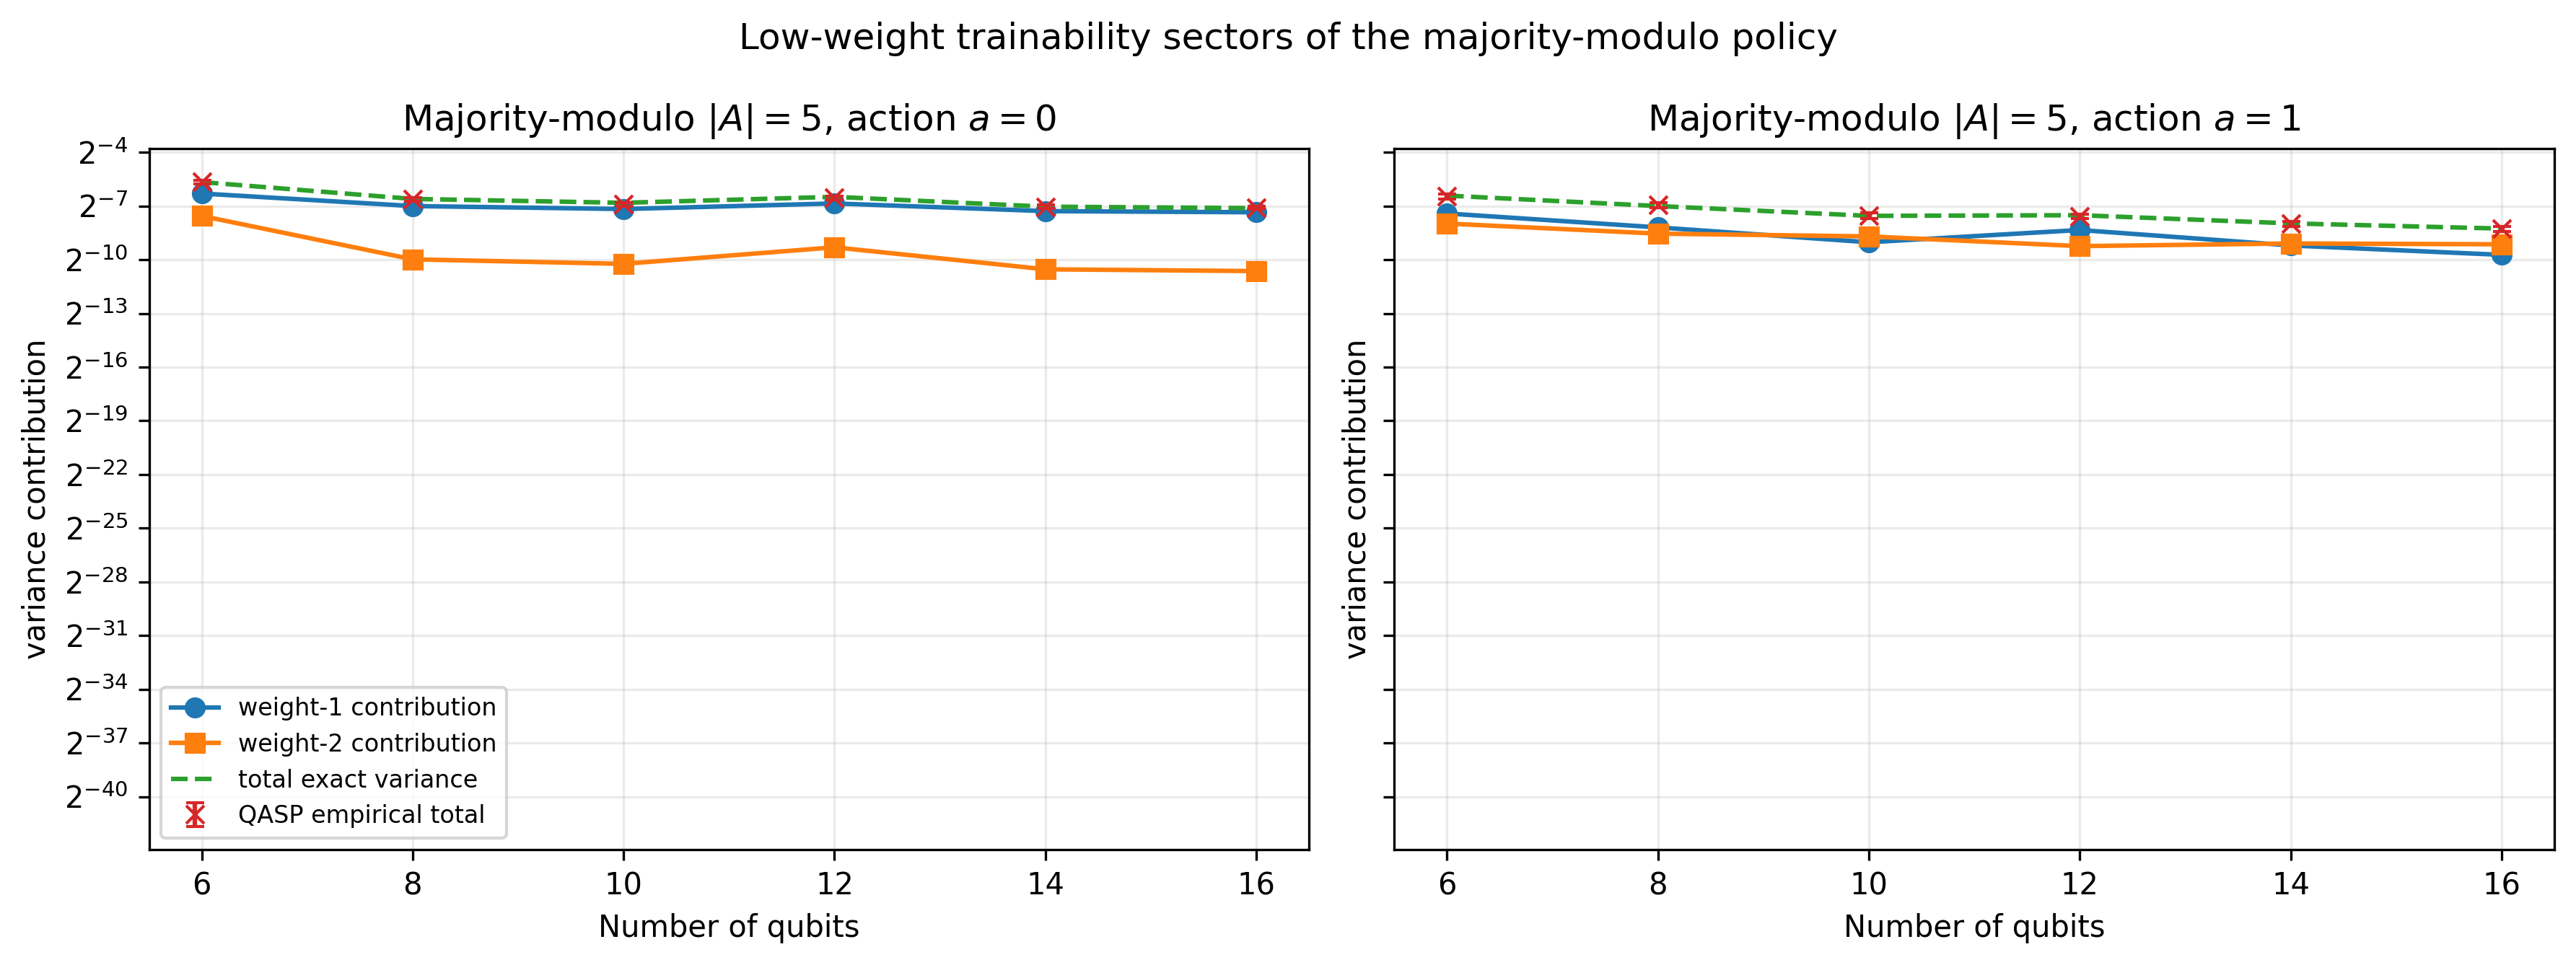

In [24]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
    sharey=True,
    dpi=FIGURE_DPI,
)

for ax, action in zip(axes, [0, 1]):
    part = sector_df[
        sector_df['action'] == action
    ]

    ax.plot(
        part['n'],
        part['weight_1_variance'],
        'o-',
        label='weight-1 contribution',
    )

    ax.plot(
        part['n'],
        part['weight_2_variance'],
        's-',
        label='weight-2 contribution',
    )

    ax.plot(
        part['n'],
        part['total_theory_variance'],
        '--',
        label='total exact variance',
    )

    empirical = majority_modulo_df[
        majority_modulo_df['case']
        == f'A=5, a={action}'
    ]

    ax.errorbar(
        empirical['n'],
        empirical['empirical_variance'],
        yerr=2 * empirical['mc_se'],
        fmt='x',
        capsize=3,
        label='QASP empirical total',
    )

    ax.set_title(
        rf'Majority-modulo $|A|=5$, action $a={action}$'
    )

    ax.set_xlabel('Number of qubits')
    ax.set_ylabel(r'variance contribution')
    ax.set_yscale('symlog', base=2, linthresh=1e-14)
    ax.grid(True, which='both', alpha=0.25)

axes[0].legend(fontsize=8)

fig.suptitle(
    'Low-weight trainability sectors of the majority-modulo policy'
)

fig.tight_layout()
plt.show()

In [25]:
# Exact structural check for the fully collided A=5, a=1 action.

for n in MAJMOD_N_VALUES:
    total, grouped = (
        majority_modulo_weight_sector_prediction(
            n=n,
            n_actions=5,
            action=1,
        )
    )

    weight_1 = grouped.loc[
        grouped['weight'] == 1,
        'variance_contribution',
    ]

    weight_2 = grouped.loc[
        grouped['weight'] == 2,
        'variance_contribution',
    ]

    weight_1_value = (
        float(weight_1.iloc[0])
        if len(weight_1)
        else 0.0
    )

    weight_2_value = (
        float(weight_2.iloc[0])
        if len(weight_2)
        else 0.0
    )

    print(
        f'n={n}: '
        f'weight-1={weight_1_value:.3e}, '
        f'weight-2={weight_2_value:.3e}, '
        f'total={total:.3e}'
    )

    assert abs(weight_1_value) < 1e-12
    assert weight_2_value > 0

print(
    '\nVerified exactly: for |A|=5, action a=1, '
    'the singleton sector cancels while the two-local '
    'sector remains nonzero.'
)

n=6: weight-1=5.859e-03, weight-2=3.967e-03, total=1.172e-02


AssertionError: 

,n,A,action,n_pauli_terms,fraction_of_full_pauli_basis
0,6,3,0,16,0.253968
1,6,4,0,24,0.380952
2,6,5,0,63,1.000000
3,6,5,1,30,0.476190
4,6,6,0,63,1.000000
5,8,3,0,255,1.000000
6,8,4,0,255,1.000000
7,8,5,0,84,0.329412
8,8,5,1,48,0.188235
9,8,8,0,99,0.388235


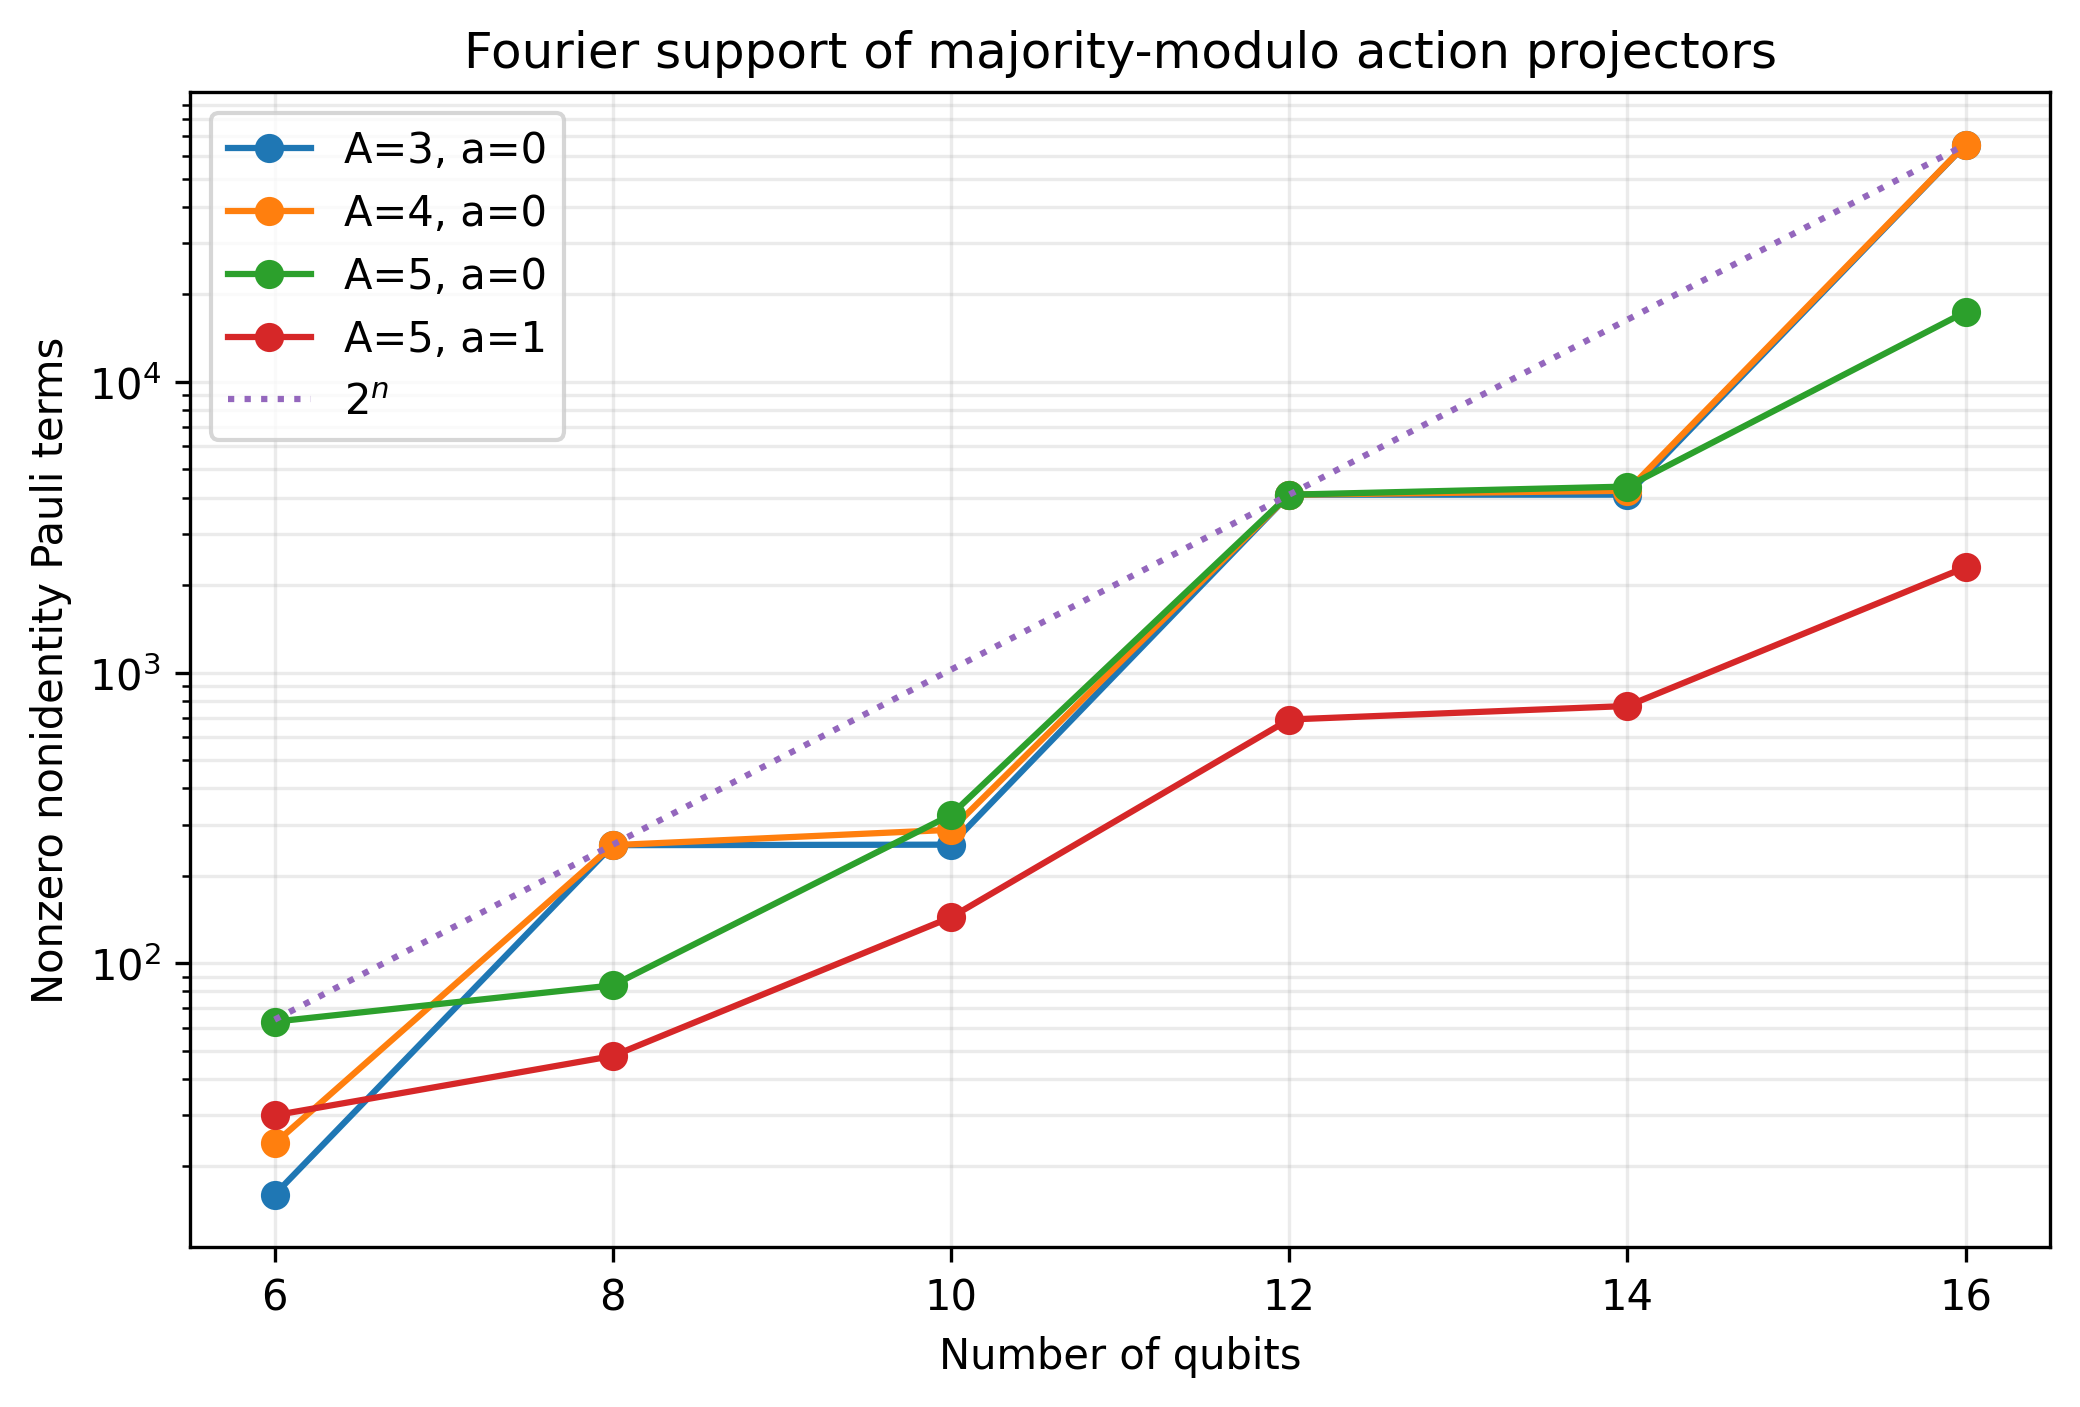

In [27]:
density_rows = []

for n in MAJMOD_N_VALUES:
    for A, action in [
        (3, 0),
        (4, 0),
        (5, 0),
        (5, 1),
        (n, 0),
    ]:
        if A > 2**n:
            continue

        (
            theory,
            n_pauli_terms,
            diagonal,
            coeffs,
            theory_mean,
        ) = majority_modulo_rank_prediction(
            n=n,
            edges=chain_edges(n),
            n_actions=A,
            action=action,
            include_local=True,
            collect_spectrum=False,
        )

        density_rows.append({
            'n': n,
            'A': A,
            'action': action,
            'n_pauli_terms': n_pauli_terms,
            'fraction_of_full_pauli_basis':
                n_pauli_terms / (2**n - 1),
        })

density_df = pd.DataFrame(density_rows)

display(density_df)

fig, ax = plt.subplots(
    figsize=(8, 5),
    dpi=FIGURE_DPI,
)

for (A, action), part in density_df.groupby(
    ['A', 'action']
):
    # Avoid grouping A=n points as separate one-point curves.
    if len(part) < 2:
        continue

    ax.plot(
        part['n'],
        part['n_pauli_terms'],
        marker='o',
        label=f'A={A}, a={action}',
    )

ax.plot(
    MAJMOD_N_VALUES,
    [2**n for n in MAJMOD_N_VALUES],
    ':',
    label=r'$2^n$',
)

ax.set_xlabel('Number of qubits')
ax.set_ylabel('Nonzero nonidentity Pauli terms')
ax.set_yscale('log')
ax.set_title('Fourier support of majority-modulo action projectors')
ax.grid(True, which='both', alpha=0.25)
ax.legend()

plt.show()

In [28]:
start = time.perf_counter()

majority_modulo_pure_rows = []

for index, n in enumerate(MAJMOD_N_VALUES):
    specs = [
        ('A=2, a=0', 2, 0),
        ('A=3, a=0', 3, 0),
        ('A=5, a=0', 5, 0),
        ('A=5, a=1', 5, 1),
        (f'A=n={n}, a=0', n, 0),
    ]

    print(
        f'pure RXX majority-modulo: n={n}'
    )

    majority_modulo_pure_rows.extend(
        run_majority_modulo_experiments_for_n(
            n=n,
            n_samples=N_SAMPLES,
            seed=SEED + 7000 + index,
            action_specs=specs,
            circuit_family='pure_rxx',
        )
    )

majority_modulo_pure_df = pd.DataFrame(
    majority_modulo_pure_rows
)

display(
    majority_modulo_pure_df.round(9)
)

print(
    f'Elapsed: '
    f'{time.perf_counter() - start:.1f} s'
)

pure RXX majority-modulo: n=6
pure RXX majority-modulo: n=8
pure RXX majority-modulo: n=10
pure RXX majority-modulo: n=12
pure RXX majority-modulo: n=14
pure RXX majority-modulo: n=16


,circuit_family,circuit_label,policy,case,n_actions,action,n,k_majority_bits,block_sizes,n_preimages,collision_hamming_distance,bin_fraction,n_pauli_terms,empirical_variance,mc_se,theory_variance,sample_mean,theory_mean,mean_error,z_score
0,pure_rxx,pure RXX,majority-modulo,"A=2, a=0",2,0,6,1,"(6,)",1,0,0.656250,63,0.077300,0.001598,0.076782,0.497477,0.500000,-0.002523,0.324201
1,pure_rxx,pure RXX,majority-modulo,"A=3, a=0",3,0,6,2,"(3, 3)",2,2,0.500000,16,0.047273,0.001256,0.045898,0.624076,0.625000,-0.000924,1.095055
2,pure_rxx,pure RXX,majority-modulo,"A=5, a=0",5,0,6,3,"(2, 2, 2)",2,2,0.468750,63,0.063520,0.001499,0.063354,0.433328,0.437500,-0.004172,0.110247
3,pure_rxx,pure RXX,majority-modulo,"A=5, a=1",5,1,6,3,"(2, 2, 2)",2,3,0.187500,30,0.042438,0.001751,0.044678,0.183978,0.187500,-0.003522,-1.279119
4,pure_rxx,pure RXX,majority-modulo,"A=n=6, a=0",6,0,6,3,"(2, 2, 2)",2,2,0.468750,63,0.070977,0.001544,0.071167,0.434733,0.437500,-0.002767,-0.123118
5,pure_rxx,pure RXX,majority-modulo,"A=2, a=0",2,0,8,1,"(8,)",1,0,0.636719,255,0.042773,0.001548,0.043169,0.769969,0.773438,-0.003469,-0.255473
6,pure_rxx,pure RXX,majority-modulo,"A=3, a=0",3,0,8,2,"(4, 4)",2,2,0.570312,255,0.040761,0.001120,0.041037,0.635338,0.640625,-0.005287,-0.246440
7,pure_rxx,pure RXX,majority-modulo,"A=5, a=0",5,0,8,3,"(3, 3, 2)",2,2,0.250000,84,0.031052,0.001208,0.032578,0.209568,0.218750,-0.009182,-1.263329
8,pure_rxx,pure RXX,majority-modulo,"A=5, a=1",5,1,8,3,"(3, 3, 2)",2,3,0.250000,48,0.034361,0.001216,0.033691,0.256824,0.250000,0.006824,0.550348
9,pure_rxx,pure RXX,majority-modulo,"A=n=8, a=0",8,0,8,3,"(3, 3, 2)",1,0,0.187500,99,0.031046,0.001383,0.032925,0.163870,0.171875,-0.008005,-1.359085


Elapsed: 91.5 s


[ 6  8 10 12 14 16]
[ 6  8 10 12 14 16]
[ 6  8 10 12 14 16]


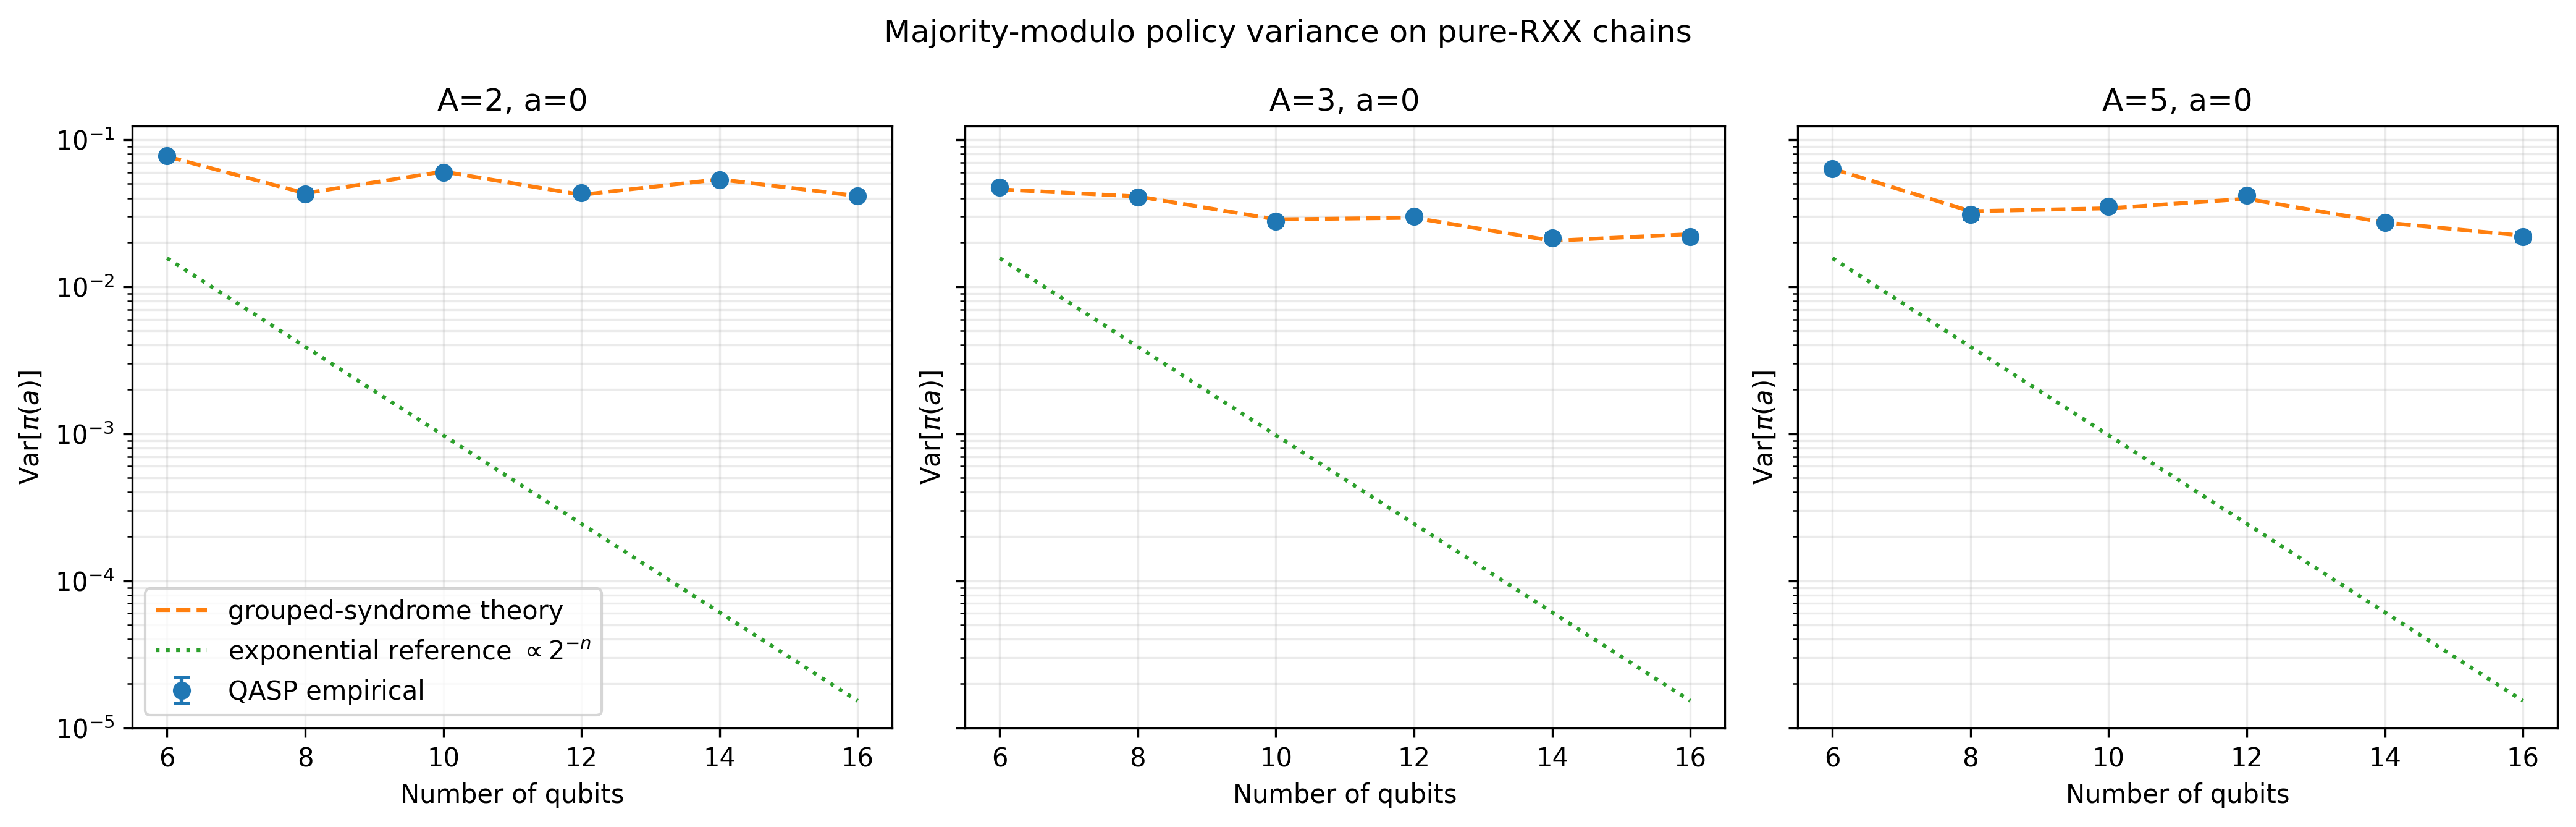

In [36]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4.5),
    sharey=True,
    dpi=FIGURE_DPI,
)

for ax, case in zip(
    axes,
    [
        'A=2, a=0',
        'A=3, a=0',
        'A=5, a=0',
        'A=5, a=1',
    ],
):
    part = majority_modulo_pure_df[
        majority_modulo_pure_df['case'] == case
    ]
    print(part['n'].to_numpy())
    exp_reference = 2.0 ** (-part['n'].to_numpy())
    ax.errorbar(
        part['n'],
        part['empirical_variance'],
        yerr=2 * part['mc_se'],
        fmt='o',
        capsize=3,
        label='QASP empirical',
    )

    ax.plot(
        part['n'],
        part['theory_variance'],
        '--',
        label='grouped-syndrome theory',
    )
    ax.plot(
    n_values,
    exp_reference,
    ':',
    linewidth=1.5,
    label=r'exponential reference $\propto 2^{-n}$',
    )
    ax.set_title(case)
    ax.set_xlabel('Number of qubits')
    ax.set_ylabel(r'$\mathrm{Var}[\pi(a)]$')
    ax.set_yscale('log')
    ax.grid(True, which='both', alpha=0.25)

axes[0].legend()

fig.suptitle(
    'Majority-modulo policy variance on pure-RXX chains'
)

fig.tight_layout()
plt.show()

<a id="repeated-iqp-depth-scaling"></a>

## Repeated-IQP depth scaling for $|A|=4$

This experiment turns the exploratory repeated-IQP cells above into a matched policy study of the augmented circuit required by the Letcher--Woerner--Zoufal variance theorem. The leading layer is $D_X^{(0)}=\prod_iR_{X_i}(\phi_i)$ and each repeated layer is
$$
\left(\prod_i R_{Z_i}\right)
\left(\prod_i R_{Z_iZ_{i+1}}\right)
\left(\prod_i R_{X_i}\right)
\left(\prod_i R_{X_iX_{i+1}}\right),
$$
The $ZZ$ edges are periodic and the $XX$ edges form an open chain. Every angle, including the angles in $D_X^{(0)}$, is sampled independently from $U[-\pi,\pi]$. In QASP the leading random $X$ layer is implemented by evaluating the one-feature `NeuralEmbedding` at input $x=1$ and sampling its input-scaling parameters. The full probability vector is simulated once per parameter sample and then decoded into contiguous, recursive-parity, and majority-modulo action probabilities. Thus all three policies see exactly the same circuit realization. We measure action $a=0$ with $|A|=4$.

For a Pauli component $Z^u$ with support $S_u$, the Letcher light-cone theorem gives
$$
\mathbb E_\omega[4^{-\Delta_u^{(L)}(\omega)}]\leq\operatorname{Var}(L_u^{(L)})\leq\mathbb E_\omega[2^{-\Delta_u^{(L)}(\omega)}],
$$
Together with $\operatorname{Var}[\pi_L(a)]=\sum_{u\neq0}c_{a,u}^2\operatorname{Var}(L_u^{(L)})$, this gives policy-level lower and upper bounds. The notebook estimates both expectations directly at the discrete Clifford ensemble $\omega\in\{0,\pi/2\}^m$. It samples Pauli masks with probability proportional to $c_{a,u}^2$, propagates them through the exact circuit, and also evaluates $\sum_{u\neq0}c_{a,u}^2\mathbb E_\omega[(L_u^{(L)})^2]$, which the theorem identifies exactly with the continuous-angle policy variance. Monte Carlo standard errors are reported for all three estimates.

The supplied manuscript additionally proposes $\Delta_u^{(L)}\leq|\mathcal B_G^{(L-1)}(S_u)|$. For the gate order tested here this is retained as an explicit hypothesis check, not assumed: the final $XX$ layer can enlarge a measured $Z^u$ light cone already at $L=1$. A conservative gate-by-gate propagation argument gives $\Delta_u^{(L)}\leq|\mathcal B_G^{(2L)}(S_u)|$, because every repeated block contains two local two-qubit rotation layers. The notebook therefore reports both the manuscript $L-1$ expression and the conservative $2L$ graph lower bound. The interaction graph is the union of all two-qubit edges; here it is the cycle because the periodic $ZZ$ ring contains the open $XX$ chain.

The five panels compare the empirical variance with the Letcher lower/upper interval and the conservative graph lower bound for $L=1$, $L=2$, $L=3$, $L=\lceil\log_2n\rceil$, and $L=n$. A second five-panel figure plots empirical variance divided by the manuscript's proposed $B_G^{(L-1)}$ lower bound, so ratios below one expose violations directly. The discrete-Clifford variance estimate is retained in the diagnostic table; it can be noisy or zero at finite sample count when the nonzero event is rare. The dotted $2^{-n}$ curve is only an additional concentration reference.

The majority decoder below matches the current QASP implementation: for $|A|=4$ it uses two disjoint, balanced odd blocks. All tested $n$ are even, so every qubit is used and ties are impossible.

In [10]:
from qasp.circuits import AngleAnsatz
from qasp.feature_maps import NeuralEmbedding
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

REPEATED_IQP_N_ACTIONS = 4
REPEATED_IQP_ACTION = 0
REPEATED_IQP_N_VALUES = [4, 6, 8, 10, 12, 14, 16]
REPEATED_IQP_N_SAMPLES = int(
    os.getenv('QASP_REPEATED_IQP_SAMPLES', str(N_SAMPLES))
)
REPEATED_IQP_BOUND_SAMPLES = int(
    os.getenv('QASP_REPEATED_IQP_BOUND_SAMPLES', str(max(10_000, N_SAMPLES)))
)
REPEATED_IQP_DEVICE = 'lightning.qubit'
REPEATED_IQP_DEPTH_KEYS = ('L=1', 'L=2', 'L=3', 'L=log2(n)', 'L=n')
REPEATED_IQP_POLICY_LABELS = {
    'contiguous': 'contiguous',
    'parity-like': 'parity',
    'majority-modulo': 'majority-modulo',
}

print(f'Repeated-IQP samples per (depth, n): {REPEATED_IQP_N_SAMPLES}')
print(f'Discrete-Clifford bound samples: {REPEATED_IQP_BOUND_SAMPLES}')
print(f'Repeated-IQP qubit sizes: {REPEATED_IQP_N_VALUES}')
print(f'Depth families: {REPEATED_IQP_DEPTH_KEYS}')

Repeated-IQP samples per (depth, n): 2000
Discrete-Clifford bound samples: 10000
Repeated-IQP qubit sizes: [4, 6, 8, 10, 12, 14, 16]
Depth families: ('L=1', 'L=2', 'L=3', 'L=log2(n)', 'L=n')


In [11]:
def repeated_iqp_rotations(n):
    """Exact Z/ZZ-ring/X/XX-chain block specified above."""
    return (
        [f'Z {i}' for i in range(n)]
        + [f'ZZ {i} {(i + 1) % n}' for i in range(n)]
        + [f'X {i}' for i in range(n)]
        + [f'XX {i} {i + 1}' for i in range(n - 1)]
    )


def resolve_repeated_iqp_depth(depth_key, n):
    if depth_key == 'L=1':
        return 1
    if depth_key == 'L=2':
        return 2
    if depth_key == 'L=3':
        return 3
    if depth_key == 'L=log2(n)':
        return int(np.ceil(np.log2(n)))
    if depth_key == 'L=n':
        return int(n)
    raise ValueError(f'Unknown repeated-IQP depth key: {depth_key}')


def build_repeated_iqp_probability_qnode(n, n_layers):
    """Build the QASP repeated circuit once and return full probabilities."""
    feature_map = NeuralEmbedding(
        n_qubits=n, features=1, rotations='X'
    )
    ansatz = AngleAnsatz(
        n_qubits=n,
        n_layers=int(n_layers),
        rotations=repeated_iqp_rotations(n),
        feature_map=feature_map,
        reuploading=False,
        include_imprimitive=False,
        imprimitive='CNOT',
        imprimitive_pattern='chain',
    )
    builder = CircuitBuilder(n_qubits=n)
    builder.set_ansatz(ansatz)
    builder.set_measurement('probs', wires=range(n))
    builder.build()
    qnode = builder.compile(device=REPEATED_IQP_DEVICE, diff_method=None)

    shapes = ansatz.get_param_shapes()
    n_input_scaling = int(shapes[0][0])
    n_parameters = int(shapes[1][0])
    return qnode, n_input_scaling, n_parameters


def repeated_balanced_odd_blocks(n, n_blocks=2):
    """Match QASP's maximally covering balanced odd-block rule."""
    used = n if (n - n_blocks) % 2 == 0 else n - 1
    pairs, extra = divmod((used - n_blocks) // 2, n_blocks)
    sizes = [
        1 + 2 * pairs + (2 if block < extra else 0)
        for block in range(n_blocks)
    ]
    blocks = []
    start = 0
    for size in sizes:
        blocks.append(tuple(range(start, start + size)))
        start += size
    return tuple(blocks), tuple(range(start, n))


def repeated_iqp_action_maps(n):
    """Return exact QASP-compatible maps for the three |A|=4 policies."""
    states = np.arange(1 << n, dtype=np.uint64)
    shifts = np.arange(n - 1, -1, -1, dtype=np.uint64)
    bits = ((states[:, None] >> shifts[None, :]) & 1).astype(np.uint8)

    contiguous = (states >> np.uint64(n - 2)).astype(np.int64)

    full_parity = bits.sum(axis=1, dtype=np.uint16) & 1
    prefix_parity = bits[:, :-1].sum(axis=1, dtype=np.uint16) & 1
    parity = ((full_parity << 1) | prefix_parity).astype(np.int64)

    blocks, unused = repeated_balanced_odd_blocks(n, n_blocks=2)
    majority_bits = [
        (bits[:, block].sum(axis=1) > len(block) / 2).astype(np.int64)
        for block in blocks
    ]
    majority = (majority_bits[0] << 1) | majority_bits[1]

    assert unused == tuple(), (n, blocks, unused)
    assert all(np.bincount(action_map, minlength=4).tolist() == [1 << (n - 2)] * 4
               for action_map in (contiguous, parity, majority))
    return {
        'contiguous': contiguous,
        'parity-like': parity,
        'majority-modulo': majority,
    }, blocks


_REPEATED_WALSH_CACHE = {}


def repeated_walsh_coefficients(indicator):
    """Coefficients c_u in Pi_a = sum_u c_u Z^u."""
    coefficients = np.asarray(indicator, dtype=float).copy()
    width = 1
    while width < len(coefficients):
        for start in range(0, len(coefficients), 2 * width):
            left = coefficients[start:start + width].copy()
            right = coefficients[start + width:start + 2 * width].copy()
            coefficients[start:start + width] = left + right
            coefficients[start + width:start + 2 * width] = left - right
        width *= 2
    return coefficients / len(coefficients)


def repeated_policy_walsh_coefficients(n, policy, action_map):
    key = (int(n), policy, REPEATED_IQP_ACTION)
    if key not in _REPEATED_WALSH_CACHE:
        indicator = np.asarray(action_map == REPEATED_IQP_ACTION, dtype=float)
        _REPEATED_WALSH_CACHE[key] = repeated_walsh_coefficients(indicator)
    return _REPEATED_WALSH_CACHE[key]


def repeated_cycle_ball_sizes(n, radius):
    """Return |B_G^radius(S_u)| for every Pauli mask u on the ring."""
    masks = np.arange(1 << n, dtype=np.uint64)
    balls = masks.copy()
    valid = np.uint64((1 << n) - 1)
    for _ in range(int(radius)):
        left = ((balls << np.uint64(1)) & valid) | (balls >> np.uint64(n - 1))
        right = (balls >> np.uint64(1)) | ((balls & np.uint64(1)) << np.uint64(n - 1))
        balls |= left | right
    return np.fromiter(
        (int(mask).bit_count() for mask in balls),
        dtype=np.uint8,
        count=len(balls),
    )


def repeated_graph_policy_lower(n, radius, policy, action_map):
    coefficients = repeated_policy_walsh_coefficients(
        n, policy, action_map
    )
    ball_sizes = repeated_cycle_ball_sizes(n, radius=radius)
    graph_factors = np.power(4.0, -ball_sizes.astype(float))
    return float(np.dot(coefficients[1:] ** 2, graph_factors[1:]))


def repeated_iqp_pauli_generators(n, n_layers):
    """(X-mask, Z-mask) generators in the QASP circuit's forward order."""
    wire_bit = lambda wire: 1 << (n - 1 - wire)
    generators = [(wire_bit(wire), 0) for wire in range(n)]
    for _ in range(int(n_layers)):
        generators.extend((0, wire_bit(wire)) for wire in range(n))
        generators.extend(
            (0, wire_bit(wire) | wire_bit((wire + 1) % n))
            for wire in range(n)
        )
        generators.extend((wire_bit(wire), 0) for wire in range(n))
        generators.extend(
            (wire_bit(wire) | wire_bit(wire + 1), 0)
            for wire in range(n - 1)
        )
    return generators


def repeated_mask_parity(values, mask):
    """Parity of values & mask; circuit generators have weight <= 2."""
    mask = int(mask)
    low_bit = mask & -mask
    parity = (values & np.uint64(low_bit)) != 0
    remaining = mask ^ low_bit
    if remaining:
        parity ^= (values & np.uint64(remaining)) != 0
    return parity


_REPEATED_POPCOUNT8 = np.asarray(
    [value.bit_count() for value in range(256)], dtype=np.uint8
)


def repeated_popcount(values):
    values = np.ascontiguousarray(values, dtype=np.uint64)
    byte_view = values.view(np.uint8).reshape(values.shape + (8,))
    return _REPEATED_POPCOUNT8[byte_view].sum(axis=-1)


def repeated_mc_mean_se(values):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return float(values.mean()), np.nan
    return float(values.mean()), float(values.std(ddof=1) / np.sqrt(len(values)))


def repeated_iqp_clifford_estimates(
    n, n_layers, action_maps, n_samples, seed
):
    """Importance-sampled Letcher bounds at omega in {0, pi/2}^m."""
    policies = tuple(REPEATED_IQP_POLICY_LABELS)
    candidate_masks = np.arange(1, 1 << n, dtype=np.uint64)
    weights = []
    total_weights = []
    for policy in policies:
        coefficients = repeated_policy_walsh_coefficients(
            n, policy, action_maps[policy]
        )
        policy_weights = coefficients[1:] ** 2
        weights.append(policy_weights)
        total_weights.append(float(policy_weights.sum()))

    rng = np.random.default_rng(seed)
    z_masks = np.stack([
        rng.choice(
            candidate_masks, size=n_samples, p=policy_weights / total_weight
        )
        for policy_weights, total_weight in zip(weights, total_weights)
    ])
    x_masks = np.zeros_like(z_masks)

    for x_generator, z_generator in reversed(
        repeated_iqp_pauli_generators(n, n_layers)
    ):
        active = rng.integers(0, 2, size=n_samples, dtype=np.uint8)
        if x_generator:
            anticommutes = repeated_mask_parity(z_masks, x_generator)
        else:
            anticommutes = repeated_mask_parity(x_masks, z_generator)
        update = anticommutes & active.astype(bool)[None, :]
        if x_generator:
            x_masks ^= update.astype(np.uint64) * np.uint64(x_generator)
        if z_generator:
            z_masks ^= update.astype(np.uint64) * np.uint64(z_generator)

    lightcone_sizes = repeated_popcount(x_masks | z_masks).astype(float)
    estimates = {}
    for index, (policy, total_weight) in enumerate(
        zip(policies, total_weights)
    ):
        lower_samples = total_weight * np.power(4.0, -lightcone_sizes[index])
        upper_samples = total_weight * np.power(2.0, -lightcone_sizes[index])
        variance_samples = total_weight * (x_masks[index] == 0)
        lower, lower_se = repeated_mc_mean_se(lower_samples)
        upper, upper_se = repeated_mc_mean_se(upper_samples)
        variance, variance_se = repeated_mc_mean_se(variance_samples)
        estimates[policy] = {
            'theory_letch_lower_mc': lower,
            'theory_letch_lower_mc_se': lower_se,
            'theory_letch_upper_mc': upper,
            'theory_letch_upper_mc_se': upper_se,
            'theory_clifford_variance_mc': variance,
            'theory_clifford_variance_mc_se': variance_se,
            'nonidentity_pauli_weight': total_weight,
        }
    return estimates


def repeated_iqp_policy_bounds(
    n, n_layers, action_maps, n_bound_samples, seed
):
    bounds = repeated_iqp_clifford_estimates(
        n, n_layers, action_maps, n_bound_samples, seed
    )
    for policy, action_map in action_maps.items():
        bounds[policy]['manuscript_graph_lower_L_minus_1'] = (
            repeated_graph_policy_lower(
                n, max(n_layers - 1, 0), policy, action_map
            )
        )
        bounds[policy]['theory_graph_lower_safe_2L'] = (
            repeated_graph_policy_lower(
                n, 2 * n_layers, policy, action_map
            )
        )
    return bounds


def repeated_sample_variance(values):
    values = np.asarray(values, dtype=float)
    variance = values.var(ddof=1)
    centered_fourth = np.mean((values - values.mean()) ** 4)
    correction = ((len(values) - 3) / (len(values) - 1)) * variance**2
    mc_se = np.sqrt(max(centered_fourth - correction, 0.0) / len(values))
    return float(variance), float(mc_se), float(values.mean())


def run_repeated_iqp_depth_family(
    depth_key,
    n_values=REPEATED_IQP_N_VALUES,
    n_samples=REPEATED_IQP_N_SAMPLES,
    seed=SEED,
):
    """Use each random circuit once, then decode all three policies."""
    rows = []
    raw_values = {}
    for n_index, n in enumerate(n_values):
        n_layers = resolve_repeated_iqp_depth(depth_key, n)
        print(
            f'\nRepeated IQP: {depth_key}, n={n}, actual L={n_layers}, '
            f'samples={n_samples}'
        )
        qnode, n_input_scaling, n_parameters = (
            build_repeated_iqp_probability_qnode(n, n_layers)
        )
        action_maps, majority_blocks = repeated_iqp_action_maps(n)
        depth_index = REPEATED_IQP_DEPTH_KEYS.index(depth_key)
        theory_bounds = repeated_iqp_policy_bounds(
            n,
            n_layers,
            action_maps,
            n_bound_samples=REPEATED_IQP_BOUND_SAMPLES,
            seed=seed + 700001 + 100003 * depth_index + n_index,
        )
        action_masks = {
            policy: action_map == REPEATED_IQP_ACTION
            for policy, action_map in action_maps.items()
        }
        policy_values = {
            policy: np.empty(n_samples, dtype=float)
            for policy in REPEATED_IQP_POLICY_LABELS
        }
        rng = np.random.default_rng(
            seed + 100003 * depth_index + n_index
        )
        # x=1 turns the first n scaling parameters into the random D_X^(0).
        inputs = np.ones(1, dtype=float)
        report_every = max(1, n_samples // 4)

        start = time.perf_counter()
        for sample in range(n_samples):
            input_scaling = np.zeros(n_input_scaling, dtype=float)
            input_scaling[:n] = rng.uniform(-np.pi, np.pi, size=n)
            params = rng.uniform(-np.pi, np.pi, size=n_parameters)
            probabilities = np.asarray(
                qnode(
                    inputs=inputs,
                    input_scaling_params=input_scaling,
                    params=params,
                ),
                dtype=float,
            )
            for policy, mask in action_masks.items():
                policy_values[policy][sample] = probabilities[mask].sum()
            if (sample + 1) % report_every == 0 or sample + 1 == n_samples:
                print(f'  {sample + 1}/{n_samples} samples', flush=True)

        elapsed = time.perf_counter() - start
        for policy, values in policy_values.items():
            variance, mc_se, mean = repeated_sample_variance(values)
            rows.append({
                'depth_family': depth_key,
                'n': n,
                'n_layers': n_layers,
                'policy': policy,
                'policy_label': REPEATED_IQP_POLICY_LABELS[policy],
                'action': REPEATED_IQP_ACTION,
                'n_actions': REPEATED_IQP_N_ACTIONS,
                'majority_blocks': majority_blocks,
                'n_parameters': n_parameters,
                'n_random_parameters': n_parameters + n,
                'sample_mean': mean,
                'empirical_variance': variance,
                'mc_se': mc_se,
                **theory_bounds[policy],
                'exponential_reference': 2.0 ** (-n),
                'elapsed_seconds_shared': elapsed,
            })
            raw_values[(depth_key, n, policy)] = values
        print(f'  shared simulation time: {elapsed:.1f} s')
    return pd.DataFrame(rows), raw_values

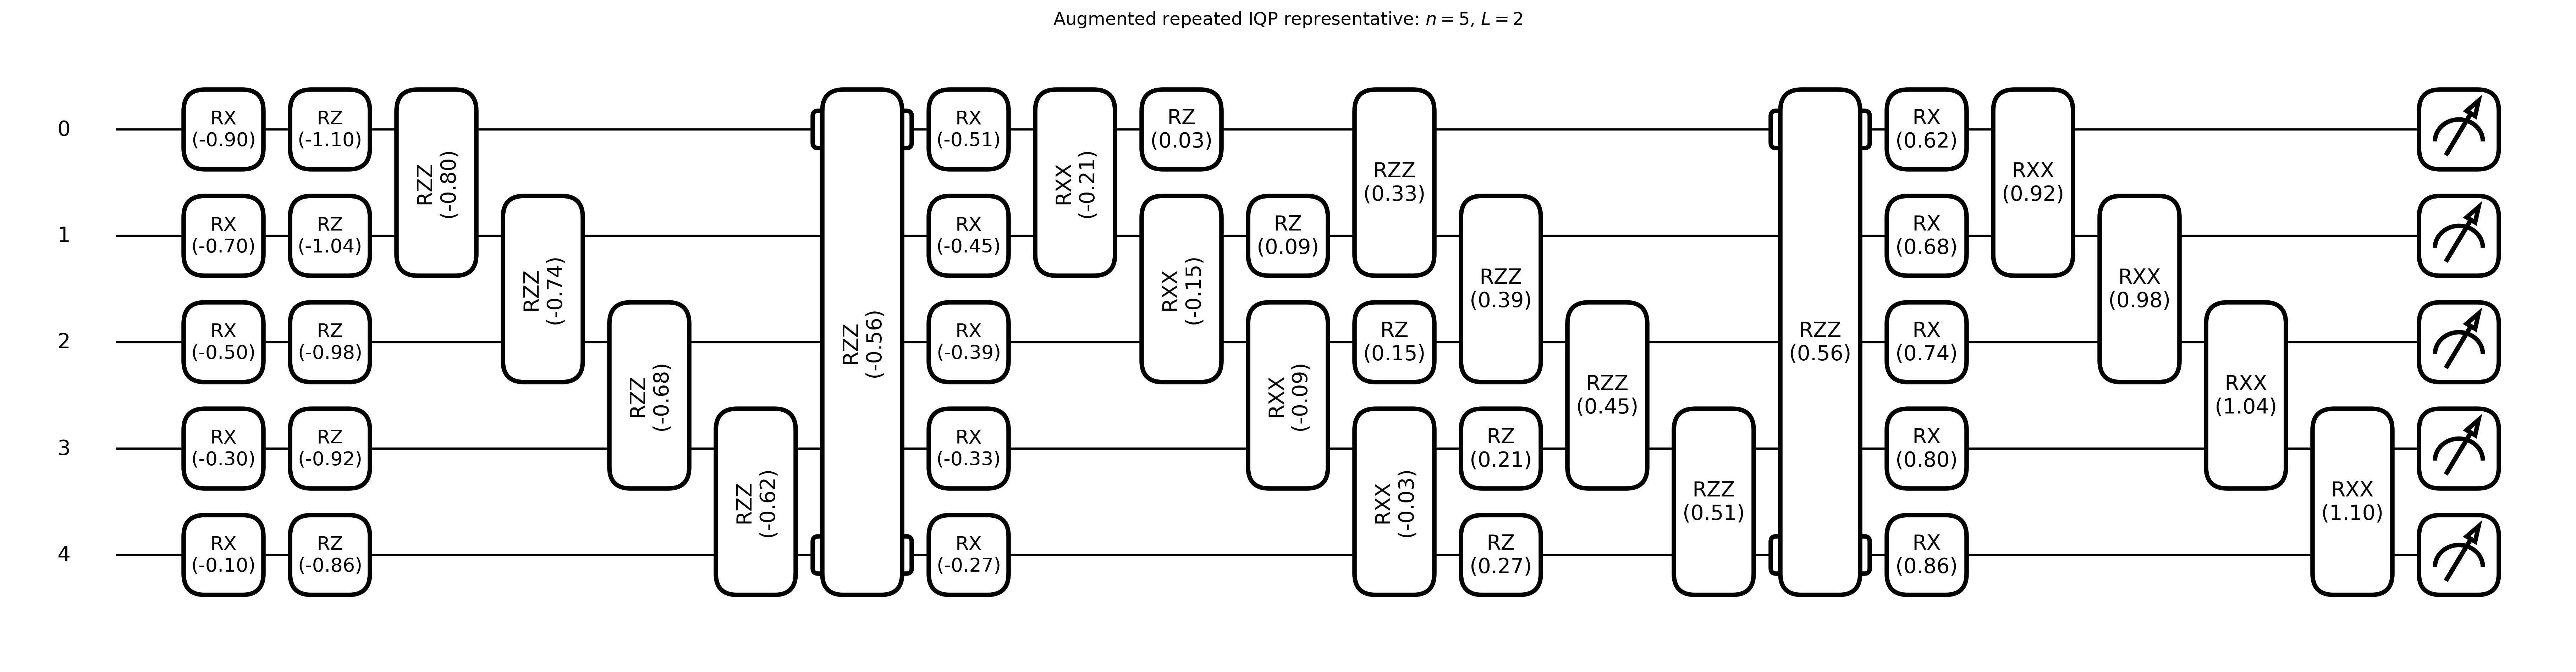

In [12]:
# Draw the representative augmented repeated circuit used by the study.
repeated_draw_qnode, repeated_draw_n_scale, repeated_draw_n_params = (
    build_repeated_iqp_probability_qnode(n=5, n_layers=2)
)
repeated_draw_params = np.linspace(-1.1, 1.1, repeated_draw_n_params)
repeated_draw_scaling = np.linspace(-0.9, 0.9, repeated_draw_n_scale)
repeated_draw_fig, repeated_draw_ax = qml.draw_mpl(
    repeated_draw_qnode, decimals=2
)(
    inputs=np.ones(1),
    input_scaling_params=repeated_draw_scaling,
    params=repeated_draw_params,
)
repeated_draw_fig.set_dpi(FIGURE_DPI)
repeated_draw_fig.suptitle(
    r'Augmented repeated IQP representative: $n=5$, $L=2$', y=1.02
)
plt.show()

In [13]:
repeated_iqp_depth_results = {}
repeated_iqp_raw_values = {}

In [14]:
# Fixed depth L=1.
(
    repeated_iqp_depth_results['L=1'],
    repeated_iqp_raw_values['L=1'],
) = run_repeated_iqp_depth_family('L=1')


Repeated IQP: L=1, n=4, actual L=1, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 4.4 s

Repeated IQP: L=1, n=6, actual L=1, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 5.8 s

Repeated IQP: L=1, n=8, actual L=1, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 6.4 s

Repeated IQP: L=1, n=10, actual L=1, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 7.9 s

Repeated IQP: L=1, n=12, actual L=1, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 12.1 s

Repeated IQP: L=1, n=14, actual L=1, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 22.4 s

Repeated IQP: L=1, n=16, act

In [15]:
# Fixed depth L=2.
(
    repeated_iqp_depth_results['L=2'],
    repeated_iqp_raw_values['L=2'],
) = run_repeated_iqp_depth_family('L=2')


Repeated IQP: L=2, n=4, actual L=2, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 4.0 s

Repeated IQP: L=2, n=6, actual L=2, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 5.6 s

Repeated IQP: L=2, n=8, actual L=2, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 8.9 s

Repeated IQP: L=2, n=10, actual L=2, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 11.6 s

Repeated IQP: L=2, n=12, actual L=2, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 14.9 s

Repeated IQP: L=2, n=14, actual L=2, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 25.0 s

Repeated IQP: L=2, n=16, ac

In [16]:
# Fixed depth L=3.
(
    repeated_iqp_depth_results['L=3'],
    repeated_iqp_raw_values['L=3'],
) = run_repeated_iqp_depth_family('L=3')


Repeated IQP: L=3, n=4, actual L=3, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 5.7 s

Repeated IQP: L=3, n=6, actual L=3, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 8.4 s

Repeated IQP: L=3, n=8, actual L=3, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 13.9 s

Repeated IQP: L=3, n=10, actual L=3, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 15.6 s

Repeated IQP: L=3, n=12, actual L=3, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 22.6 s

Repeated IQP: L=3, n=14, actual L=3, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 41.7 s

Repeated IQP: L=3, n=16, a

In [17]:
# Logarithmic depth L=ceil(log2(n)).
(
    repeated_iqp_depth_results['L=log2(n)'],
    repeated_iqp_raw_values['L=log2(n)'],
) = run_repeated_iqp_depth_family('L=log2(n)')


Repeated IQP: L=log2(n), n=4, actual L=2, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 4.8 s

Repeated IQP: L=log2(n), n=6, actual L=3, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 10.6 s

Repeated IQP: L=log2(n), n=8, actual L=3, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 14.4 s

Repeated IQP: L=log2(n), n=10, actual L=4, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 23.2 s

Repeated IQP: L=log2(n), n=12, actual L=4, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 29.8 s

Repeated IQP: L=log2(n), n=14, actual L=4, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation tim

In [18]:
# Linear depth L=n. This is the most expensive panel.
(
    repeated_iqp_depth_results['L=n'],
    repeated_iqp_raw_values['L=n'],
) = run_repeated_iqp_depth_family('L=n')


Repeated IQP: L=n, n=4, actual L=4, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 8.9 s

Repeated IQP: L=n, n=6, actual L=6, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 21.2 s

Repeated IQP: L=n, n=8, actual L=8, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 38.2 s

Repeated IQP: L=n, n=10, actual L=10, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 59.4 s

Repeated IQP: L=n, n=12, actual L=12, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 94.5 s

Repeated IQP: L=n, n=14, actual L=14, samples=2000
  500/2000 samples
  1000/2000 samples
  1500/2000 samples
  2000/2000 samples
  shared simulation time: 185.0 s

Repeated IQP: L=n, n=

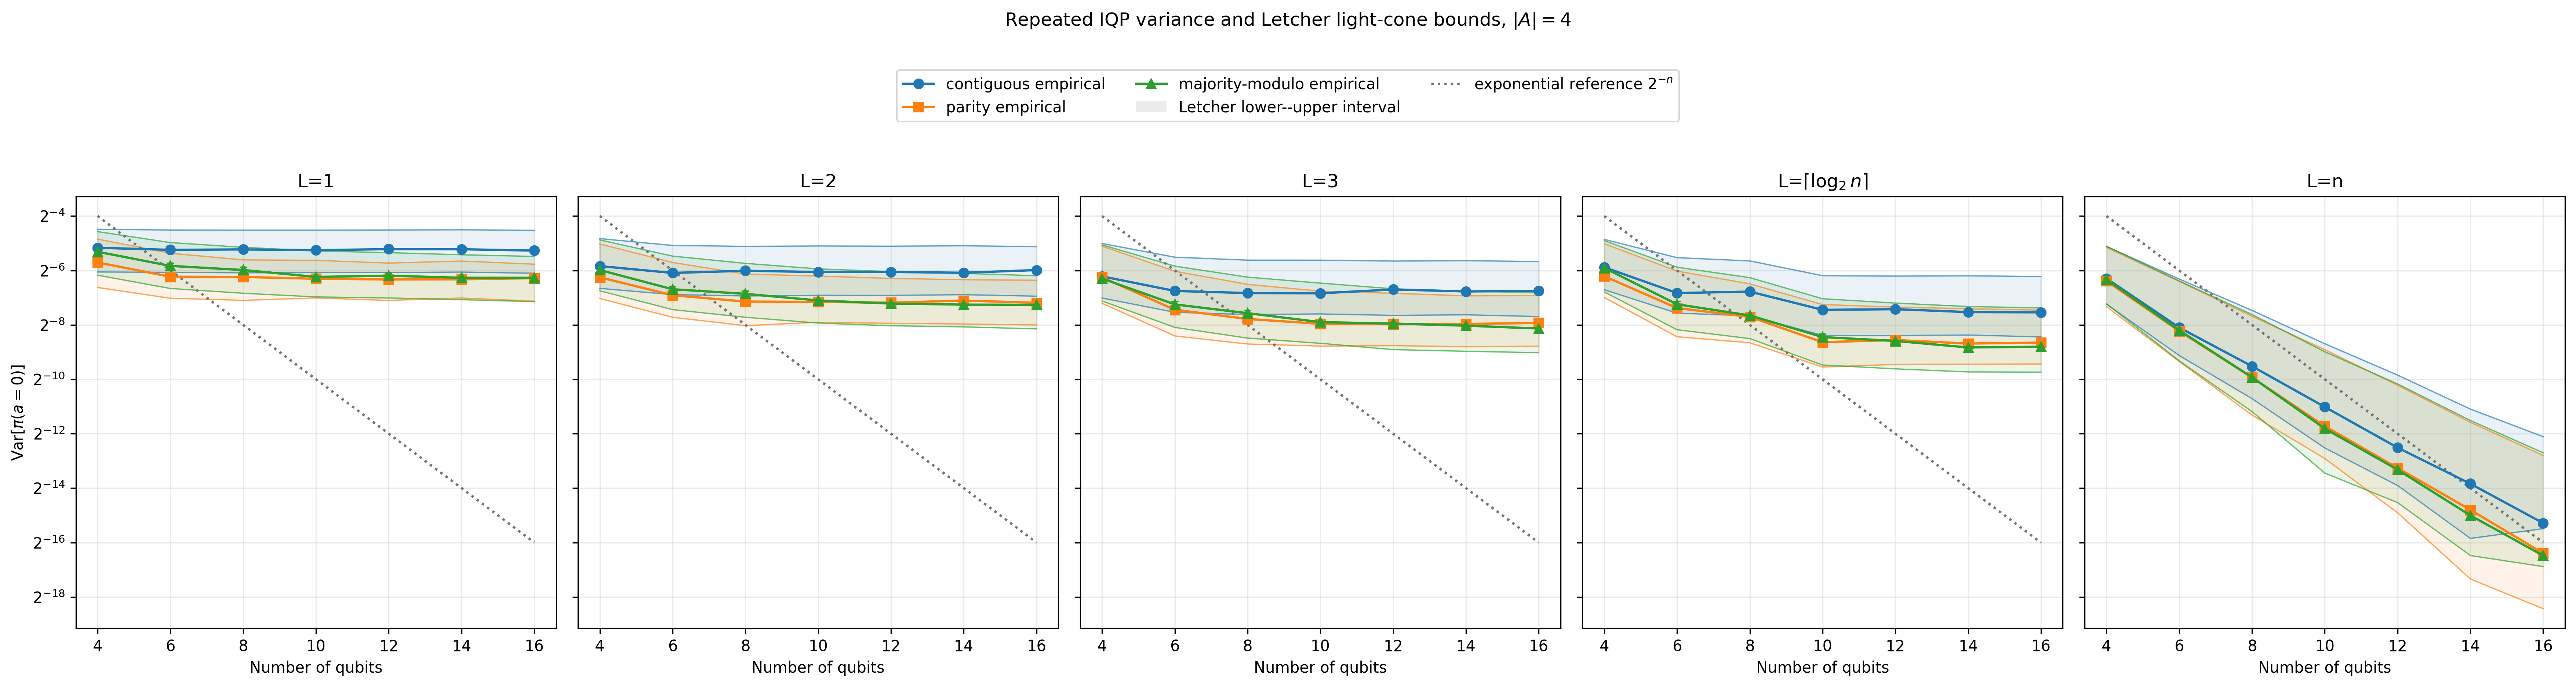

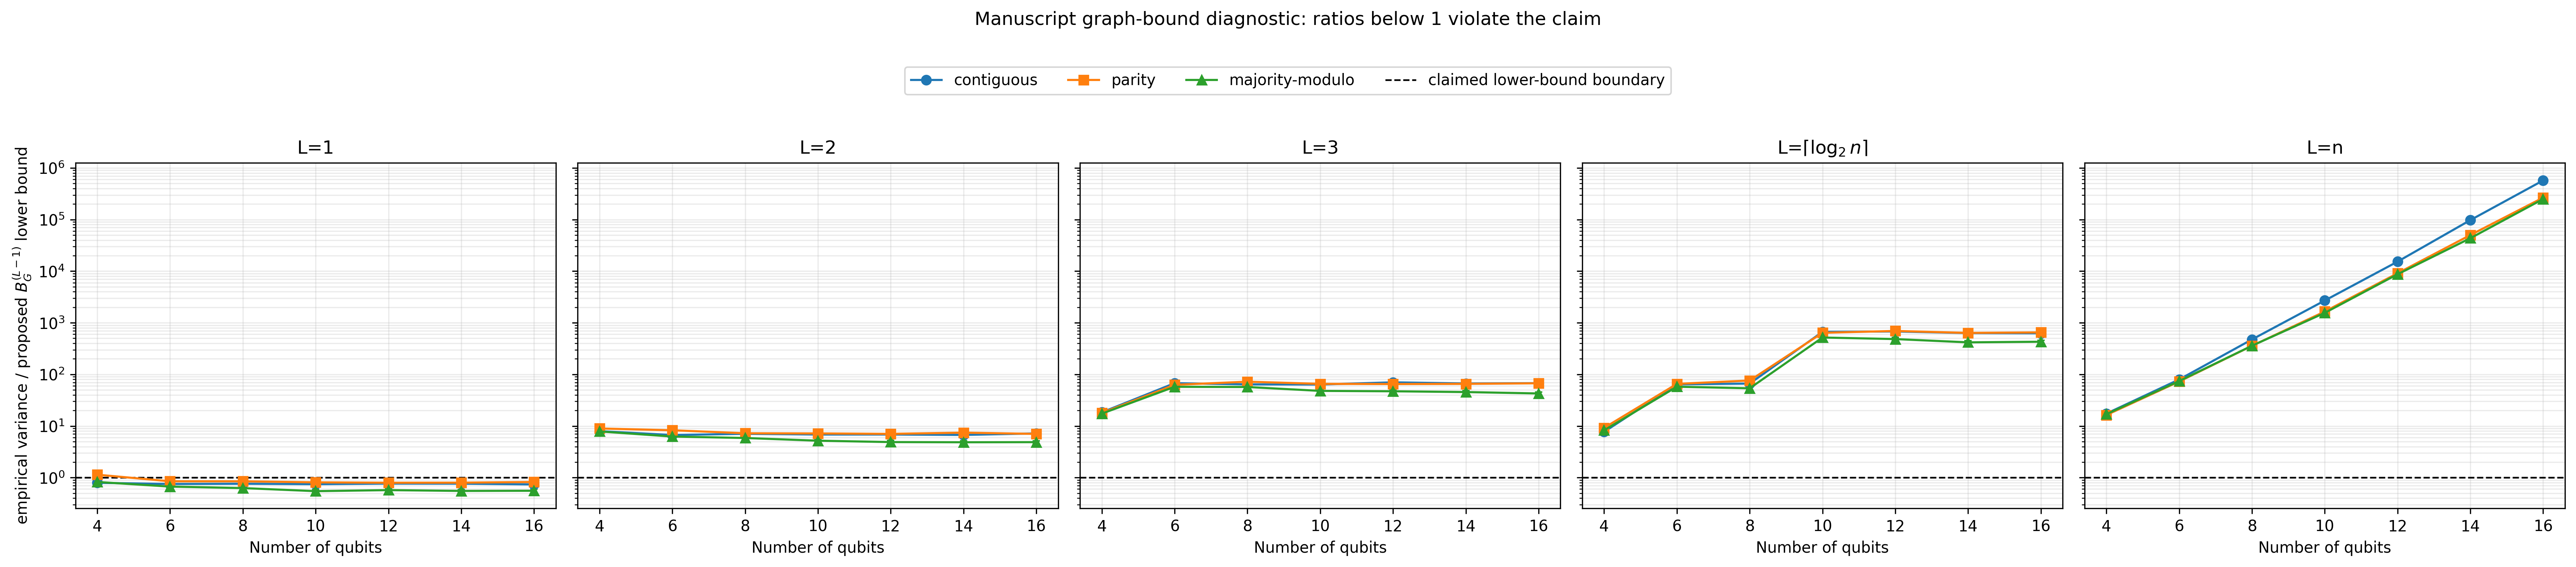

,depth_family,policy,log2_variance_slope_per_qubit
0,L=1,contiguous,-0.0045
1,L=1,parity,-0.0360
2,L=1,majority-modulo,-0.0706
3,L=2,contiguous,-0.0083
4,L=2,parity,-0.0579
5,L=2,majority-modulo,-0.0950
6,L=3,contiguous,-0.0269
7,L=3,parity,-0.1119
8,L=3,majority-modulo,-0.1332
9,L=log2(n),contiguous,-0.1253


,depth_family,n,n_layers,policy_label,sample_mean,empirical_variance,mc_se,theory_letch_lower_mc,theory_letch_lower_mc_se,theory_letch_upper_mc,...,theory_clifford_variance_mc_se,clifford_agreement_z,theory_graph_lower_safe_2L,manuscript_graph_lower_L_minus_1,letch_lower_pass_5se,letch_upper_pass_5se,safe_graph_lower_pass_5se,manuscript_L_minus_1_pass_5se,n_random_parameters,elapsed_seconds_shared
0,L=1,4,1,contiguous,0.251069,0.027861,1.059480e-03,0.015045,0.000174,0.044661,...,0.000653,1.128445,0.000732,0.035156,True,True,True,False,19,4.420498
1,L=1,4,1,parity,0.254058,0.019179,6.399700e-04,0.010134,0.000151,0.034741,...,0.000559,0.791544,0.000732,0.016846,True,True,True,True,19,4.420498
2,L=1,4,1,majority-modulo,0.253917,0.025180,8.761700e-04,0.013862,0.000171,0.042094,...,0.000633,0.536977,0.000732,0.030579,True,True,True,False,19,4.420498
3,L=1,6,1,contiguous,0.251948,0.026422,9.234600e-04,0.014910,0.000176,0.043838,...,0.000644,0.752385,0.000137,0.035156,True,True,True,False,29,5.814845
4,L=1,6,1,parity,0.247035,0.013324,3.599400e-04,0.007697,0.000152,0.024256,...,0.000497,1.478775,0.000092,0.015701,True,True,True,False,29,5.814845
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,L=n,14,14,parity,0.250025,0.000035,1.380000e-06,0.000006,0.000001,0.000327,...,0.000032,0.652520,0.000000,0.000000,True,True,True,True,784,184.963187
101,L=n,14,14,majority-modulo,0.250075,0.000030,1.100000e-06,0.000011,0.000005,0.000342,...,0.000032,0.794828,0.000000,0.000000,True,True,True,True,784,184.963187
102,L=n,16,16,contiguous,0.250046,0.000025,1.100000e-06,0.000022,0.000008,0.000226,...,0.000032,0.961092,0.000000,0.000000,True,True,True,True,1024,489.470157
103,L=n,16,16,parity,0.250014,0.000012,5.000000e-07,0.000003,0.000001,0.000140,...,0.000000,23.355179,0.000000,0.000000,True,True,True,True,1024,489.470157


,letcher_lower_all_pass,letcher_upper_all_pass,safe_graph_all_pass,manuscript_L_minus_1_all_pass,maximum_clifford_agreement_z
depth_family,,,,,
L=1,True,True,True,False,1.584
L=2,True,True,True,True,1.177
L=3,True,True,True,True,1.825
L=log2(n),True,True,True,True,2.876
L=n,True,True,True,True,23.355


In [22]:
missing_repeated_depths = (
    set(REPEATED_IQP_DEPTH_KEYS) - set(repeated_iqp_depth_results)
)
if missing_repeated_depths:
    raise RuntimeError(
        f'Run the missing repeated-IQP depth cells first: '
        f'{sorted(missing_repeated_depths)}'
    )

repeated_iqp_depth_df = pd.concat(
    [repeated_iqp_depth_results[key] for key in REPEATED_IQP_DEPTH_KEYS],
    ignore_index=True,
)
repeated_lower_combined_se = np.sqrt(
    repeated_iqp_depth_df['mc_se'] ** 2
    + repeated_iqp_depth_df['theory_letch_lower_mc_se'] ** 2
)
repeated_upper_combined_se = np.sqrt(
    repeated_iqp_depth_df['mc_se'] ** 2
    + repeated_iqp_depth_df['theory_letch_upper_mc_se'] ** 2
)
repeated_clifford_combined_se = np.sqrt(
    repeated_iqp_depth_df['mc_se'] ** 2
    + repeated_iqp_depth_df['theory_clifford_variance_mc_se'] ** 2
)
repeated_iqp_depth_df['letch_lower_pass_5se'] = (
    repeated_iqp_depth_df['empirical_variance']
    + 5 * repeated_lower_combined_se
    >= repeated_iqp_depth_df['theory_letch_lower_mc']
)
repeated_iqp_depth_df['letch_upper_pass_5se'] = (
    repeated_iqp_depth_df['empirical_variance']
    - 5 * repeated_upper_combined_se
    <= repeated_iqp_depth_df['theory_letch_upper_mc']
)
repeated_iqp_depth_df['clifford_agreement_z'] = (
    np.abs(
        repeated_iqp_depth_df['empirical_variance']
        - repeated_iqp_depth_df['theory_clifford_variance_mc']
    )
    / repeated_clifford_combined_se.replace(0, np.nan)
)
repeated_iqp_depth_df['safe_graph_lower_pass_5se'] = (
    repeated_iqp_depth_df['empirical_variance']
    + 5 * repeated_iqp_depth_df['mc_se']
    >= repeated_iqp_depth_df['theory_graph_lower_safe_2L']
)
repeated_iqp_depth_df['manuscript_L_minus_1_pass_5se'] = (
    repeated_iqp_depth_df['empirical_variance']
    + 5 * repeated_iqp_depth_df['mc_se']
    >= repeated_iqp_depth_df['manuscript_graph_lower_L_minus_1']
)

repeated_colors = {
    'contiguous': '#1f77b4',
    'parity-like': '#ff7f0e',
    'majority-modulo': '#2ca02c',
}
repeated_markers = {
    'contiguous': 'o',
    'parity-like': 's',
    'majority-modulo': '^',
}

fig, axes = plt.subplots(
    1, 5, figsize=(23.5, 5.2), dpi=FIGURE_DPI, sharey=True
)
for ax, depth_key in zip(axes, REPEATED_IQP_DEPTH_KEYS):
    panel = repeated_iqp_depth_df[
        repeated_iqp_depth_df['depth_family'] == depth_key
    ]
    for policy in REPEATED_IQP_POLICY_LABELS:
        curve = panel[panel['policy'] == policy].sort_values('n')
        variance = curve['empirical_variance'].to_numpy()
        two_se = 2 * curve['mc_se'].to_numpy()
        lower_error = np.minimum(two_se, variance * (1 - 1e-12))
        ax.errorbar(
            curve['n'],
            variance,
            yerr=np.vstack([lower_error, two_se]),
            color=repeated_colors[policy],
            marker=repeated_markers[policy],
            linewidth=1.5,
            capsize=2.5,
            label=f'{REPEATED_IQP_POLICY_LABELS[policy]} empirical',
        )
        lower_bound = curve['theory_letch_lower_mc'].to_numpy()
        upper_bound = curve['theory_letch_upper_mc'].to_numpy()
        ax.fill_between(
            curve['n'], lower_bound, upper_bound,
            color=repeated_colors[policy], alpha=0.09,
        )
        ax.plot(
            curve['n'], lower_bound, color=repeated_colors[policy],
            linewidth=0.8, alpha=0.65,
        )
        ax.plot(
            curve['n'], upper_bound, color=repeated_colors[policy],
            linewidth=0.8, alpha=0.65,
        )
        #ax.plot(
        #    curve['n'],
        #    curve['theory_graph_lower_safe_2L'],
        #    color=repeated_colors[policy],
        #    linestyle=':', linewidth=1.0, alpha=0.75,
        #)
    reference_n = np.asarray(REPEATED_IQP_N_VALUES)
    ax.plot(
        reference_n,
        2.0 ** (-reference_n),
        color='0.45',
        linestyle=':',
        linewidth=1.6,
        label=r'exponential reference $2^{-n}$',
    )
    title = depth_key.replace('log2(n)', r'$\lceil\log_2 n\rceil$')
    ax.set_title(title)
    ax.set_xlabel('Number of qubits')
    ax.set_xticks(REPEATED_IQP_N_VALUES)
    ax.set_yscale('log', base=2)
    ax.grid(True, which='both', alpha=0.25)

axes[0].set_ylabel(r'$\mathrm{Var}[\pi(a=0)]$')
policy_handles = [
    Line2D(
        [0], [0], color=repeated_colors[policy],
        marker=repeated_markers[policy], linewidth=1.5,
        label=f'{REPEATED_IQP_POLICY_LABELS[policy]} empirical',
    )
    for policy in REPEATED_IQP_POLICY_LABELS
]
theory_handles = [
    Patch(
        facecolor='0.5', alpha=0.15, label='Letcher lower--upper interval'
    ),
    #Line2D(
    #    [0], [0], color='0.25', linestyle=':', linewidth=1.0,
    #    label=r'conservative graph lower $B_G^{(2L)}$',
    #),
    Line2D(
        [0], [0], color='0.45', linestyle=':', linewidth=1.6,
        label=r'exponential reference $2^{-n}$',
    ),
]
fig.legend(
    handles=policy_handles + theory_handles, loc='upper center',
    ncol=3, bbox_to_anchor=(0.5, 1.10),
)
fig.suptitle(
    r'Repeated IQP variance and Letcher light-cone bounds, $|A|=4$', y=1.19
)
fig.tight_layout()
plt.show()

# Direct diagnostic of the manuscript's proposed B_G^(L-1) lower bound.
fig_bound_check, axes_bound_check = plt.subplots(
    1, 5, figsize=(23.5, 4.4), dpi=FIGURE_DPI, sharey=True
)
for ax, depth_key in zip(axes_bound_check, REPEATED_IQP_DEPTH_KEYS):
    panel = repeated_iqp_depth_df[
        repeated_iqp_depth_df['depth_family'] == depth_key
    ]
    for policy in REPEATED_IQP_POLICY_LABELS:
        curve = panel[panel['policy'] == policy].sort_values('n')
        proposed_lower = curve[
            'manuscript_graph_lower_L_minus_1'
        ].to_numpy()
        ratio = curve['empirical_variance'].to_numpy() / proposed_lower
        ratio_two_se = 2 * curve['mc_se'].to_numpy() / proposed_lower
        ratio_lower_error = np.minimum(
            ratio_two_se, ratio * (1 - 1e-12)
        )
        ax.errorbar(
            curve['n'], ratio,
            yerr=np.vstack([ratio_lower_error, ratio_two_se]),
            color=repeated_colors[policy],
            marker=repeated_markers[policy],
            linewidth=1.4, capsize=2.5,
        )
    ax.axhline(1.0, color='black', linestyle='--', linewidth=1.1)
    title = depth_key.replace('log2(n)', r'$\lceil\log_2 n\rceil$')
    ax.set_title(title)
    ax.set_xlabel('Number of qubits')
    ax.set_xticks(REPEATED_IQP_N_VALUES)
    ax.set_yscale('log')
    ax.grid(True, which='both', alpha=0.25)
axes_bound_check[0].set_ylabel(
    r'empirical variance / proposed $B_G^{(L-1)}$ lower bound'
)
ratio_handles = [
    Line2D(
        [0], [0], color=repeated_colors[policy],
        marker=repeated_markers[policy], linewidth=1.4,
        label=REPEATED_IQP_POLICY_LABELS[policy],
    )
    for policy in REPEATED_IQP_POLICY_LABELS
]
ratio_handles.append(
    Line2D(
        [0], [0], color='black', linestyle='--', linewidth=1.1,
        label='claimed lower-bound boundary',
    )
)
fig_bound_check.legend(
    handles=ratio_handles, loc='upper center', ncol=4,
    bbox_to_anchor=(0.5, 1.06),
)
fig_bound_check.suptitle(
    r'Manuscript graph-bound diagnostic: ratios below 1 violate the claim',
    y=1.16,
)
fig_bound_check.tight_layout()
plt.show()

# A log2-variance slope near -1 indicates 2^{-n}-like concentration.
repeated_slope_rows = []
for (depth_key, policy), curve in repeated_iqp_depth_df.groupby(
    ['depth_family', 'policy'], sort=False
):
    curve = curve.sort_values('n')
    positive = curve['empirical_variance'].to_numpy() > 0
    slope = np.nan
    if positive.sum() >= 2:
        slope = np.polyfit(
            curve.loc[positive, 'n'],
            np.log2(curve.loc[positive, 'empirical_variance']),
            deg=1,
        )[0]
    repeated_slope_rows.append({
        'depth_family': depth_key,
        'policy': REPEATED_IQP_POLICY_LABELS[policy],
        'log2_variance_slope_per_qubit': slope,
    })

repeated_slope_df = pd.DataFrame(repeated_slope_rows)
display(repeated_slope_df.round(4))
display(
    repeated_iqp_depth_df[[
        'depth_family', 'n', 'n_layers', 'policy_label',
        'sample_mean', 'empirical_variance', 'mc_se',
        'theory_letch_lower_mc', 'theory_letch_lower_mc_se',
        'theory_letch_upper_mc', 'theory_letch_upper_mc_se',
        'theory_clifford_variance_mc',
        'theory_clifford_variance_mc_se', 'clifford_agreement_z',
        'theory_graph_lower_safe_2L',
        'manuscript_graph_lower_L_minus_1',
        'letch_lower_pass_5se', 'letch_upper_pass_5se',
        'safe_graph_lower_pass_5se',
        'manuscript_L_minus_1_pass_5se', 'n_random_parameters',
        'elapsed_seconds_shared',
    ]].round(8)
)

repeated_bound_summary = (
    repeated_iqp_depth_df.groupby('depth_family', sort=False)
    .agg(
        letcher_lower_all_pass=('letch_lower_pass_5se', 'all'),
        letcher_upper_all_pass=('letch_upper_pass_5se', 'all'),
        safe_graph_all_pass=('safe_graph_lower_pass_5se', 'all'),
        manuscript_L_minus_1_all_pass=(
            'manuscript_L_minus_1_pass_5se', 'all'
        ),
        maximum_clifford_agreement_z=('clifford_agreement_z', 'max'),
    )
)
display(repeated_bound_summary.round(3))

<a id="conclusions"></a>

## Conclusions

- The general predictor is the binary rank: $\operatorname{Var}(L_s)=2^{-\operatorname{rank}_{\mathbb F_2}(G_s)}$.
- With every local $R_X$ generator present, the rank equals the graph light-cone size and the graph-IQP shortcut $2^{-\Delta_G(s)}$ is valid.
- In the pure $R_{XX}$ triangle, the light cone has size 3 but the two relevant generator columns have rank 2. QASP therefore approaches variance $1/4$, distinguishing the rank law from the incorrect $1/8$ light-cone guess.
- Binary contiguous policies are governed by a local $Z$ term on a chain and retain constant-order variance, whereas binary recursive parity uses the global $Z_0\cdots Z_{n-1}$ term and has variance $2^{-n-2}$.
- At $|A|=4$, recursive parity contains $P_n$, $P_{n-1}$, and the local term $Z_{n-1}$, so its variance no longer vanishes purely as $2^{-n}$.
- For power-of-two $|A|$, modulo policies extract the last $k=\log_2|A|$ bits and have the same factorized form as contiguous policies on the final $k$ qubits.
- For $|A|=n$ with non-power-of-two $n$, the exact modular and recursive-parity bins—not an assumed power-of-two formula—determine their Walsh spectra and theoretical curves.
- In pure-$R_{XX}$ circuits, Pauli strings with the same edge-generator syndrome must be combined before their variance is evaluated. This exposes conserved parity sectors; for example, the binary parity-like action can become deterministic with exactly zero variance.
- The policy scaling study covers $n=3,4,6,8,10,12,14,16$ qubits for graph-IQP chains and pure-$R_{XX}$ rings, while reusing one QASP probability simulation per circuit family and qubit size for all nine policy/action-set combinations.
- The repeated-IQP study uses the augmented random $D_X^{(0)}$ layer required by the Letcher theorem and compares continuous empirical variance with directly sampled discrete-Clifford lower and upper bounds.
- For the tested $Z/ZZ/X/XX$ gate order, the manuscript radius $L-1$ is recorded as a hypothesis check: the final $XX$ layer can expand a $Z$ observable already at $L=1$. The conservative graph-only radius used as a guaranteed bound is therefore $2L$.
- Every Matplotlib and PennyLane figure is configured at 300 DPI for publication-quality export.

In [1]:
a = 4

In [4]:
int((1.5 + 2) % a)

3